# 2-motor: teardown

Open the motor after every other stage 2 experiment, weigh and count its parts, look for anything across its terminals other than the winding, read the copper with no brushes in the path, sweep the gray disc behind the commutator, drive one bare coil through the board to see where the current that flows only under drive lives, and heat the bare rotor through the board to see how its copper cools, so the earlier stage 2 numbers have the motor's own parts to stand against.

## Purpose

Every stage 2 notebook before this one read the motor through its terminals. The resistance, the inductance, the back-EMF and the inertia all came through two brushes, a commutator and a winding nobody had seen. Several of them left a question that only the open motor answers. Rest-resistance read the terminal at 4.10 ohm on the meter and 4.46 ohm at an amp and could not say how much of either is copper. Inductance and bemf-coast found a spike of charge at every PWM edge (PWM is pulse width modulation, the bridge switching the motor on and off at 20 kHz) and a current that flows only while the bridge drives, and named a capacitor across the brushes as a candidate. Speed-torque and no-load-current read the rotor's inertia, $J$, through the current, with no outside check.

So the teardown has six jobs.

- Weigh, measure and count the parts, and bound $J$ from the rotor's mass and size.
- Read the end cap with the rotor out, for any part across the terminals.
- Read the winding between the commutator's tabs with no brushes in the path, and with the leads read on their own, split the terminal resistance into copper, leads and brush path.
- Read the gray disc found behind the commutator, sweep it off the rotor for its current against voltage, and hold it against the spike and the drive-only current of the earlier notebooks.
- Drive one coil of the bare rotor with inductance's fast bursts, with and without a ring sector across it and back in the can without its brushes, to find which part carries the drive-only current.
- Heat the bare rotor through the board and read its copper's resistance while it cools, as a check that the resistance over the textbook copper coefficient reads the copper's temperature through the board, and for the shape of the cooling.

The teardown is one motor, and it is destructive. Its numbers belong to mg90-b. The cooling's shape is what a brushed motor of this class most likely shares, and its time constants belong to this rotor in open air and feed no calibration.

## Procedure

The motor came out of the rig after speed-torque. In order, by hand and with the capture script where a log was useful.

1. The whole motor weighed with its pinion on and its leads unsoldered, the can measured with a micrometer, the side label photographed.
2. The pinion pulled and weighed, the end cap pried off the can, the rotor pulled out, and each part weighed and photographed. The rotor's stack, commutator and shaft measured with calipers.
3. `capture.py terminals`. The end cap seated back on the empty can, so the brushes touch nothing and a part from a terminal to the case would stay in place. The meter (the OWON B41T+ of stage 0, logging over Bluetooth) read ohms and capacitance across the two terminal tabs and ohms from each tab to the can. A part that conducts only above a volt or two reads open on ohms, so the DPS (the bench supply) then put 3.7, 5.0 and 7.4 V across the tabs with the meter on DC milliamps in series. Then a lead zero with the probes shorted and the motor's two leads in series, clipped together at their tab ends.
4. The rotor's three tab pairs read by hand on the meter's ohms, since the logged window for the first pair came through empty and the other two were never logged.
5. Two leads soldered to commutator tabs 1 and 2 for the cool run, and a third to tab 3.
6. `capture.py cool winding`. The rotor held by its shaft in still air with the thermocouple taped in the winding. The meter read the room, a lead zero and the leads at their board ends, then the leads went to the board's motor connector. The board probed the copper at room, heated it at 100 % on the 3.3 V rail and probed it again while it cooled for about eleven minutes, with the meter logging the thermocouple throughout.
7. The gray disc behind the commutator read by hand, after the coil wires were cut loose at one of its pads.
8. A brush pulled out of the end cap and photographed.
9. `capture.py coil ring`, `coil noring` and `coil can`. One coil, the other two cut loose at the third pad, with leads on the gray disc's two pads at its ends, then with one lead moved to the coil's free wire end, then with the same leads and the rotor back in the can, its two magnets in place, no end cap and no brushes, the shaft clamped. Each is inductance's fast-1 groups on a 5 V rail. The leads' free ends read by hand before each.
10. The gray disc pried off the rotor with the commutator's segments still fused to its pads, leads on two pads, and its three pad pairs read by hand on ohms and capacitance. Then the white lead fell off, taking its segment's copper with it, and was soldered again on the free pad.
11. `capture.py disc iv`. The meter read the open probes' capacitance, then ohms and capacitance across the leads, then sat on DC current in series, its microamp range held, while the DPS stepped the leads from 0 to 20 V and back in 1 V steps of 5 s with its current limit at 2 mA, both ways round.

The cool run's other half, `cool core` with the tip on the iron, was not run. The section on it below says why.

## Data

The teardown's hand readings, its photos, the end cap's meter logs and the disc's sweep are in `telemetry/mg90-b/teardown/`, with no board in the path. The cool run and the coil runs are in `telemetry/mg90-b__dev-v006-2A-D/teardown/`.

- `hand.csv`, every reading taken by hand. `quantity`, `value`, `unit` and a `note` that says how it was taken. Masses on a 1 mg scale, dimensions on a micrometer or calipers, counts off the parts and the photos, and the meter readings of the rotor and the disc as read off the display.
- `photos/01` to `27`, the teardown in order, with their metadata stripped. A few are shown below.
- `terminals-1/`, one meter log per window, the columns `t_host`, `function`, `value` and `raw`, one packet about every half second, and `marks.csv` with the host time of each prompt. `tabs-ohm`, `tabs-cap`, `tab-a-can-ohm`, `tab-b-can-ohm`, `iv-3.7`, `iv-5.0`, `iv-7.4`, `pair-zero` and `leads-ohm`.
- `cool-winding-1/`, the meter windows `room-c1`, `zero`, `tabs-ohm`, `leads-ohm` and `room-c2`, then `temp.csv`, the thermocouple through the whole board phase, `marks.csv`, and `board/room`, `board/heat-0` and `board/cool`, one `osc-lab sweep` each, with its `meta.json`, `segments.csv` (one row per segment with its commanded duty and host times) and `sweep.csv` (one row per control tick at 20 kHz for each streamed segment, the raw ADC counts of the current channel and the two terminal taps among them).
- `coil-ring-1/`, `coil-noring-1/` and `coil-can-1/`, one folder per group, `f1-fwd-25`, `f2-fwd-40`, `f3-rev-40`, `f4-rev-25`, `f5-fwd-25` and `f6-fwd-40`, each with five `burst-K.csv` and a `meta.json`, the layout of inductance's `fast-1`. The first four groups are fast decay, the last two slow decay.
- `disc-iv-1/`, the meter windows `open-cap`, `pair-ohm` and `pair-cap`, then `iv-pos.csv` and `iv-neg.csv`, the meter on DC current in series through each polarity's sweep, and `steps-pos.csv` and `steps-neg.csv`, one row per step, `t_host` the host time of the DPS's read-back 5 s after the step was set, `volts_set`, `dps_volts` and `dps_amps`. `marks.csv` has the host time of each prompt and step.

Two things about the meter's packets matter below. The loader turns an ohms packet that shows OL (open, over the range's limit) into a value of 0.0, so an open reading is found from the packet's raw bits, a decimals field of 7 with a reading of 0, and never from the value. And the loader leaves the value empty for capacitance, so those packets are decoded here from the same bits, the range field 1 being nanofarads. With the probes open in air the display read 0.090 to 0.092 nF, which fixes that scale. The DC current packets of the disc's sweep carry the loader's value, in amps.

### Setup

The motor, the board, the folders, and the constants every section uses.

In [1]:
import io
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage
from PIL import Image
from scipy.linalg import expm
from scipy.optimize import curve_fit, least_squares
from scipy.signal import lfilter

from oscnb import b41t, boards, bursts as bu, motors, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                   # the motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
TEL = Path("../../../telemetry")
HAND_DIR = (TEL / MOTOR.key / "teardown").resolve()                     # the teardown with no board: hand readings, photos, end cap logs
TERMINALS = HAND_DIR / "terminals-1"                                    # the end cap's meter windows
PHOTOS = HAND_DIR / "photos"
COOL = (TEL / f"{MOTOR.key}__{BOARD.key}" / "teardown" / "cool-winding-1").resolve()   # the bare rotor heated through the board
COIL = {w: (TEL / f"{MOTOR.key}__{BOARD.key}" / "teardown" / f"coil-{w}-1").resolve() for w in ("ring", "noring", "can")}   # one coil's bursts
DISC = HAND_DIR / "disc-iv-1"                                           # the gray disc off the rotor, swept on the DPS
FAST1 = (TEL / f"{MOTOR.key}__{BOARD.key}" / "inductance" / "fast-1" / "hole-11").resolve()   # the motor's own bursts, the same groups
BS = (TEL / BOARD.key / "bridge-states" / "capture-1").resolve()        # stage 1's resistor and inductor controls
ALPHA = 0.00393          # copper's resistance coefficient per C at 20 C, the textbook value
C_CU = 0.385             # copper's specific heat, J per g per C
print(MOTOR.key, "from", results.rel(HAND_DIR), "and", results.rel(COOL))
print("coil runs", ", ".join(str(results.rel(p)) for p in COIL.values()), "| disc", results.rel(DISC))
print("against", results.rel(FAST1), "and", results.rel(BS))
print(f"{MOTOR.label}: the registry counts {MOTOR.slots} slots, {MOTOR.brushes} brushes and a {MOTOR.pinion_teeth} tooth pinion")

mg90-b from telemetry/mg90-b/teardown and telemetry/mg90-b__dev-v006-2A-D/teardown/cool-winding-1
coil runs telemetry/mg90-b__dev-v006-2A-D/teardown/coil-ring-1, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-noring-1, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-can-1 | disc telemetry/mg90-b/teardown/disc-iv-1
against telemetry/mg90-b__dev-v006-2A-D/inductance/fast-1/hole-11 and telemetry/dev-v006-2A-D/bridge-states/capture-1
the motor of MG90 clone b: the registry counts 3 slots, 2 brushes and a 9 tooth pinion


### Values carried in

From stage 0 the thermocouple's correction. From stage 1 the current-scale and terminal-chain lines, for the power into the copper in the cool run. From the earlier stage 2 notebooks the numbers this one is held against, each read from its results file.

In [2]:
TCPL = results.read("0-instruments", "thermocouple")                    # the thermocouple's offset and slope against ice and boiling water
CS = results.read("1-board", "current-scale", pair=BOARD.key)           # counts per amp and the in-drive offset over the lap's own zero
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)          # counts per volt of tap difference and its offset
ST = results.read("1-board", "sample-timing", pair=BOARD.key)           # the bridge's edge lags in slow decay
BSR = results.read("1-board", "bridge-states", pair=BOARD.key)          # the resistor and inductor controls' DC R and L
RR = results.read("2-motor", "rest-resistance", pair=MOTOR.key)         # the terminal resistance on the meter and at an amp
IND = results.read("2-motor", "inductance", pair=MOTOR.key)             # the spike and the step at the ON edge
BEMF = results.read("2-motor", "bemf-coast", pair=MOTOR.key)            # the reading term and the spinning edges
SPT = results.read("2-motor", "speed-torque", pair=MOTOR.key)           # the rotor's inertia from the run-ups
NLC = results.read("2-motor", "no-load-current", pair=MOTOR.key)        # the inertia from the spin and the coast
G_CPA, B_OFF = CS["counts_per_a"]["value"], CS["drive_offset_counts"]["value"]
K_CPV, C_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]
TERM_3V3, CUR_3V3 = TC["terminal_error_3v3_pct"]["value"], CS["deviation_3v3_bare_pct"]["value"]   # the 3.3 V level, not graded


def t_corr(reading):
    # the stage 0 thermocouple correction, t = (reading - offset) / slope
    return (np.asarray(reading, float) - TCPL["offset_c"]["value"]) / TCPL["slope"]["value"]


print(f"current: counts over the zero = {B_OFF:+.1f} + {G_CPA:.1f} x amps; terminals: tap difference = {C_OFF:+.1f} + {K_CPV:.2f} x volts")
print(f"at the 3.3 V level, not graded in stage 1: terminal difference {TERM_3V3:+.1f} % over the meter, current {CUR_3V3:+.1f} % over the line")
print(f"rest-resistance: meter route {RR['r_ohms_median_ohm']['value']:.3f} ohm at room_c {RR['room_c']['value']:.2f} C, "
      f"stall pass {RR['r_term_median_ohm']['value']:.3f} ohm at {RR['r_term_amps']['value']:.2f} A")

current: counts over the zero = +5.3 + 1135.0 x amps; terminals: tap difference = +2.4 + 248.37 x volts
at the 3.3 V level, not graded in stage 1: terminal difference +12.6 % over the meter, current +8.4 % over the line
rest-resistance: meter route 4.100 ohm at room_c 25.50 C, stall pass 4.455 ohm at 0.78 A


### hand.csv

Every hand reading, in the order it was taken.

In [3]:
H = pd.read_csv(HAND_DIR / "hand.csv")


def hand(quantity):
    # every value logged under one quantity name, as floats
    return H.loc[H["quantity"] == quantity, "value"].astype(float).to_numpy()


with pd.option_context("display.max_colwidth", 140):
    show(H, n=None)

,quantity,value,unit,note
0,mass whole motor,3.182,g,"pinion on, leads unsoldered"
1,can across flats,7.99,mm,"micrometer, read 1"
2,can across flats,7.98,mm,"micrometer, read 2"
3,can across rounds,10.00,mm,"micrometer, read 1"
4,can across rounds,9.96,mm,"micrometer, read 2"
5,body length,12.53,mm,"can front face to end cap back face, bosses excluded, read 1"
6,body length,12.54,mm,"can front face to end cap back face, bosses excluded, read 2"
7,mass pinion,0.037,g,off the shaft
8,mass rotor,1.123,g,"shaft, stack, coils, commutator, gray disc, green washer fixed on; no pinion"
9,mass can,1.771,g,with magnets and front bushing


A few of the photos. Top left, the motor with its label, LFF-1012TA. Top right, the end cap off and the rotor still in the can, with the two brushes in the end cap. Bottom left, the rotor out, three poles wound with copper under black tape, the commutator at the near end with the gray disc and the green washer behind it. Bottom right, the end cap with one brush still in it, a strip of three parallel wire fingers.

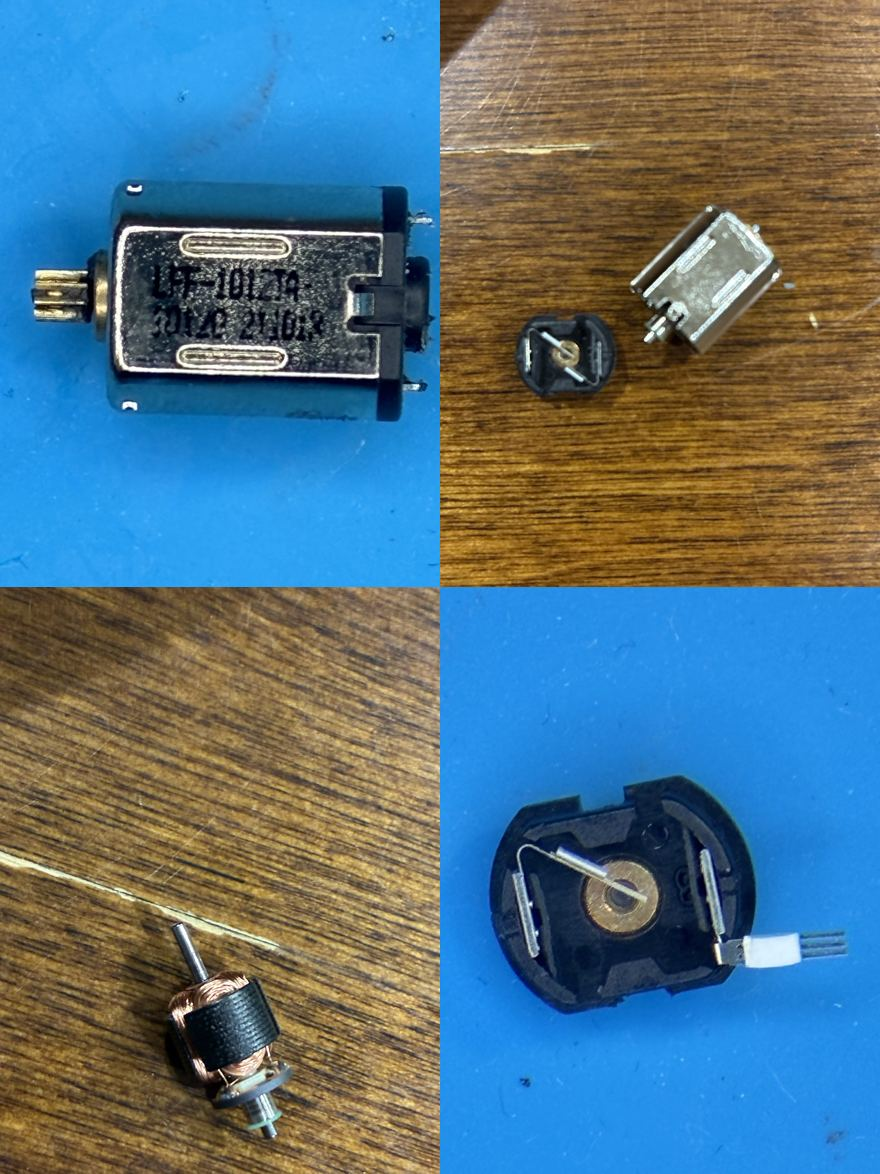

In [4]:
def photos(names, cols, width=880, quality=78):
    # a few photos side by side, each scaled into its cell, as one JPEG so the notebook stays small
    cell = width // cols
    ims = []
    for n in names:
        im = Image.open(PHOTOS / n).convert("RGB")
        im.thumbnail((cell, cell * 2))                                   # keep the aspect, fit the cell's width
        ims.append(im)
    rows = [ims[k:k + cols] for k in range(0, len(ims), cols)]
    heights = [max(im.height for im in r) for r in rows]
    sheet = Image.new("RGB", (cell * cols, sum(heights)), "white")
    y = 0
    for r, h in zip(rows, heights):
        for k, im in enumerate(r):
            sheet.paste(im, (k * cell + (cell - im.width) // 2, y))
        y += h
    buf = io.BytesIO()
    sheet.save(buf, "JPEG", quality=quality)
    return ShowImage(data=buf.getvalue(), format="jpeg")


photos(["02-whole-motor-side-label.jpg", "06-end-cap-off-can-with-rotor.jpg",
        "10-rotor-side-2.jpg", "23-end-cap-brush-three-fingers.jpg"], cols=2)

## The parts

### Masses, dimensions and counts

Left, each part's mass stacked against the whole motor weighed before it came apart. Right, the dimensions as read, each reading a dot. The thing to see on the left is whether the parts add up to the whole.

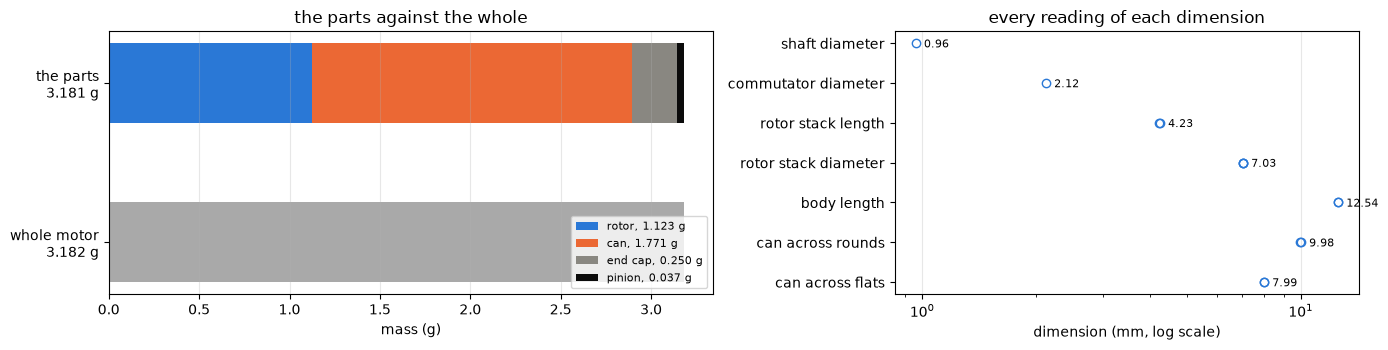

parts sum 3.181 g against the whole 3.182 g, -1 mg
counts: rotor poles 3, commutator segments 3, magnets 2, brushes 2, fingers per brush 3, commutator dark bands 3
the registry's slots 3 against 3 poles, brushes 2 against 2


In [5]:
MASS = {k: float(hand(f"mass {k}")[0]) for k in ("whole motor", "pinion", "rotor", "can", "end cap")}   # grams
PARTS = ["rotor", "can", "end cap", "pinion"]
PARTS_SUM = sum(MASS[k] for k in PARTS)
DIMS = {"can across flats": hand("can across flats"), "can across rounds": hand("can across rounds"),
        "body length": hand("body length"), "rotor stack diameter": hand("rotor stack diameter"),
        "rotor stack length": hand("rotor stack length"), "commutator diameter": hand("commutator diameter"),
        "shaft diameter": hand("shaft diameter")}                       # mm, every reading
COUNT = {"rotor poles": hand("count rotor poles")[0], "commutator segments": hand("count commutator segments")[0],
         "magnets": hand("count magnets")[0], "brushes": hand("count brushes")[0],
         "fingers per brush": hand("count fingers per brush")[0], "commutator dark bands": hand("commutator dark bands")[0]}

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
left = 0.0
for k, c in zip(PARTS, (BLUE, ORANGE, MUTED, INK)):
    ax[0].barh(1, MASS[k], left=left, color=c, height=0.5, label=f"{k}, {MASS[k]:.3f} g")    # the parts, stacked
    left += MASS[k]
ax[0].barh(0, MASS["whole motor"], color=INK, alpha=0.35, height=0.5)                         # the whole motor, weighed first
ax[0].set_yticks([0, 1], [f"whole motor\n{MASS['whole motor']:.3f} g", f"the parts\n{PARTS_SUM:.3f} g"])
ax[0].set_xlabel("mass (g)"); ax[0].set_title("the parts against the whole"); ax[0].legend(fontsize=8, loc="lower right"); ax[0].grid(alpha=0.3, axis="x")
for y, (k, v) in enumerate(DIMS.items()):
    ax[1].plot(v, [y] * len(v), "o", ms=6, color=BLUE, mfc="none")                           # each reading of a dimension
    ax[1].annotate(f"{v.mean():.2f}", (v.max(), y), xytext=(6, -3), textcoords="offset points", fontsize=8)
ax[1].set_yticks(range(len(DIMS)), list(DIMS)); ax[1].set_xscale("log")
ax[1].set_xlabel("dimension (mm, log scale)"); ax[1].set_title("every reading of each dimension"); ax[1].grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
print(f"parts sum {PARTS_SUM:.3f} g against the whole {MASS['whole motor']:.3f} g, {(PARTS_SUM - MASS['whole motor']) * 1e3:+.0f} mg")
print("counts:", ", ".join(f"{k} {int(v)}" for k, v in COUNT.items()))
print(f"the registry's slots {MOTOR.slots} against {int(COUNT['rotor poles'])} poles, brushes {MOTOR.brushes} against {int(COUNT['brushes'])}")

The four parts add to 3.181 g against 3.182 g for the whole motor, 1 mg apart, which is one step of the scale. Nothing was lost or left out in the weighing. The rotor is about a third of the motor's mass and the can with its two magnets more than half. The can is 8 by 10 mm across with a body 12.5 mm long, which is the size the side label's LFF-1012TA says. The rotor's stack is 7.03 mm across at all three poles and 4.22 to 4.24 mm long, on a shaft of 0.96 mm, with a commutator of 2.12 mm.

The counts match the registry. Three poles carry three coils, the commutator has three segments, and two arc magnets sit in the can. Each of the two brushes is a strip of three parallel wire fingers, and the commutator shows three dark wear bands, one per finger. A green fiber washer is fixed on the shaft at the commutator end, and a loose brown washer turns and slides on it at the output end, most likely a thrust spacer.

Each commutator tang (the hooked tab of a segment that the coil wires are attached to) carries two coil wire ends, which is what three coils joined in a delta need, each coil running from one segment to the next. The tangs did not melt under the iron at 750 F, so they are most likely fused, welded rather than soldered, and the wires were cut loose at the tangs instead.

### The rotor's inertia, a bound

A uniform cylinder of the rotor's mass and the stack's diameter has

$$J_\mathrm{cyl} = \frac{m \, r^2}{2}$$

with $m$ the rotor's mass and $r$ half the stack's diameter. The rotor is not uniform. The shaft, the commutator and the disc sit at a smaller radius than the stack and the copper, so the true $J$ is under this, and $J_\mathrm{cyl}$ is an upper bound. The pinion was off the rotor when it was weighed and on it in the earlier runs, so it adds a little on top, which the cell below sizes.

The bound against the inertia the earlier notebooks read through the current, each with its bracket as a whisker. The thing to see is whether every route sits under the bound.

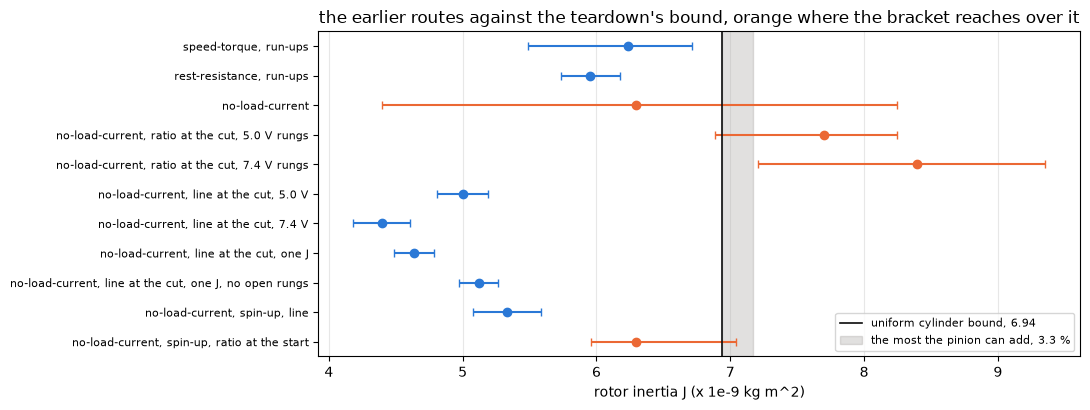

J_cyl = 6.937e-09 kg m^2 from 1.123 g over 7.03 mm
  speed-torque, run-ups: 6.24 (5.49 to 6.71) x 1e-9, -10 % against the bound
  rest-resistance, run-ups: 5.95 (5.73 to 6.18) x 1e-9, -14 % against the bound
  no-load-current: 6.30 (4.39 to 8.25) x 1e-9, -9 % against the bound
  no-load-current, ratio at the cut, 5.0 V rungs: 7.70 (6.88 to 8.25) x 1e-9, +11 % against the bound
  no-load-current, ratio at the cut, 7.4 V rungs: 8.40 (7.21 to 9.35) x 1e-9, +21 % against the bound
  no-load-current, line at the cut, 5.0 V: 5.00 (4.81 to 5.19) x 1e-9, -28 % against the bound
  no-load-current, line at the cut, 7.4 V: 4.39 (4.18 to 4.61) x 1e-9, -37 % against the bound
  no-load-current, line at the cut, one J: 4.64 (4.49 to 4.79) x 1e-9, -33 % against the bound
  no-load-current, line at the cut, one J, no open rungs: 5.12 (4.98 to 5.27) x 1e-9, -26 % against the bound
  no-load-current, spin-up, line: 5.33 (5.08 to 5.59) x 1e-9, -23 % against the bound
  no-load-current, spin-up, ratio at 

In [6]:
R_STACK_M = DIMS["rotor stack diameter"].mean() / 2 * 1e-3             # m
J_CYL = MASS["rotor"] * 1e-3 * R_STACK_M ** 2 / 2                       # kg m^2, the rotor as a uniform cylinder
PINION_PCT = MASS["pinion"] / MASS["rotor"] * 100                       # the pinion as a cylinder of the stack's radius, the most it can add
ROUTES = {"speed-torque, run-ups": SPT["j_kg_m2"], "rest-resistance, run-ups": RR["j_runup_kg_m2"],
          "no-load-current": NLC["j_kg_m2"]}
for name, q in NLC["j_by_route"].items():
    ROUTES[f"no-load-current, {name}"] = q                              # every route no-load-current carries
fig, ax = plt.subplots(figsize=(11, 4.2))
for y, (name, q) in enumerate(ROUTES.items()):
    over = q["hi"] > J_CYL
    ax.errorbar(q["value"] * 1e9, y, xerr=[[(q["value"] - q["lo"]) * 1e9], [(q["hi"] - q["value"]) * 1e9]], fmt="o", ms=6, capsize=3,
                color=ORANGE if over else BLUE)
ax.axvline(J_CYL * 1e9, color=INK, lw=1.2, label=f"uniform cylinder bound, {J_CYL * 1e9:.2f}")
ax.axvspan(J_CYL * 1e9, J_CYL * 1e9 * (1 + PINION_PCT / 100), color=MUTED, alpha=0.25, label=f"the most the pinion can add, {PINION_PCT:.1f} %")
ax.set_yticks(range(len(ROUTES)), list(ROUTES), fontsize=8); ax.invert_yaxis()
ax.set_xlabel("rotor inertia J (x 1e-9 kg m^2)"); ax.set_title("the earlier routes against the teardown's bound, orange where the bracket reaches over it")
ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
print(f"J_cyl = {J_CYL:.3e} kg m^2 from {MASS['rotor']:.3f} g over {2 * R_STACK_M * 1e3:.2f} mm")
for name, q in ROUTES.items():
    print(f"  {name}: {q['value'] * 1e9:.2f} ({q['lo'] * 1e9:.2f} to {q['hi'] * 1e9:.2f}) x 1e-9, {(q['value'] / J_CYL - 1) * 100:+.0f} % against the bound")

The bound is 6.94 x $10^{-9}$ kg m$^2$. The pinion, if all its 37 mg sat at the stack's radius, would add 3.3 %. It sits much closer to the shaft, so it most likely adds well under a percent.

Speed-torque's run-ups read 6.24 x $10^{-9}$ with a bracket of 5.49 to 6.71, and rest-resistance's run-ups 5.95, both 10 to 14 % under the bound and inside it with their brackets, which is consistent with a rotor whose shaft and commutator carry part of the mass at a small radius, with moderate confidence. A rough share of mass near the axis of a tenth to a fifth would put $J$ about there.

No-load-current's result is 6.30 with a bracket of 4.39 to 8.25, and two of its routes, the ratio at the cut on the 5.0 V and the 7.4 V rungs, read 7.70 and 8.40, 11 and 21 % over the bound, outside it with most of their brackets. A rotor holds no more inertia than a uniform cylinder of its own mass and size, the pinion aside, so those two routes most likely read high, high confidence. That notebook already carries them as the high end of its bracket, and the teardown now bounds them from outside.

## The end cap, terminals-1

The end cap seated back on the empty can, the brushes touching nothing. Each window decoded from the packets' raw bits. Left, how many packets of each ohms window read OL. Middle, the capacitance across the terminal tabs against the open probes in air. Right, the current with the DPS across the tabs at each level. The thing to see is whether anything other than an open circuit appears.

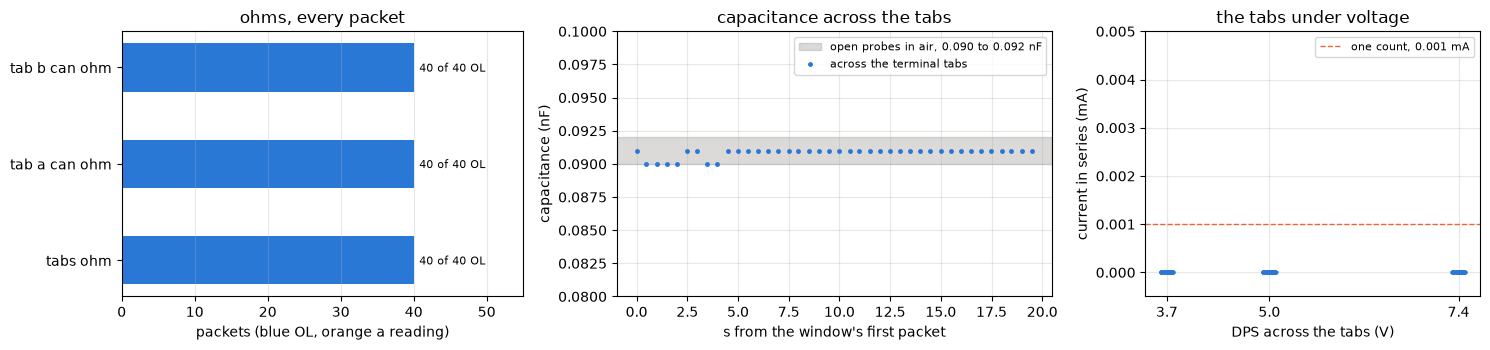

tabs ohm: 40 of 40 packets OL, range bytes ['27f1']
tab a can ohm: 40 of 40 packets OL, range bytes ['37f1']
tab b can ohm: 40 of 40 packets OL, range bytes ['27f1']
tabs cap: 0.090 to 0.091 nF over 40 packets, median 0.091
iv 3.7: 40 packets, every one 0.000 mA, 3 decimals
iv 5.0: 40 packets, every one 0.000 mA, 3 decimals
iv 7.4: 40 packets, every one 0.000 mA, 3 decimals


In [7]:
def meter(folder, name):
    # one meter log with each packet's raw fields decoded: func, scale, dec, meas, and OL found from the bits
    df = b41t.load(folder / f"{name}.csv")
    bits = pd.DataFrame([b41t.decode(r)[2] for r in df["raw"].astype(str)])
    df = pd.concat([df, bits], axis=1)
    df["ol"] = (df["func"] == 4) & (df["dec"] == 7) & (df["meas"] == 0)   # an ohms packet that shows OL; the loader's value is 0.0 there
    df["nf"] = np.where(df["func"] == 5, df["meas"] / 10.0 ** df["dec"], np.nan)   # capacitance, range field 1 = nF
    df["ma"] = np.where(df["func"] == 2, df["meas"].abs() / 10.0 ** df["dec"], np.nan)   # DC milliamps, range field 3 = mA
    return df


tmarks = pd.read_csv(TERMINALS / "marks.csv")
OHM_WINDOWS = ["tabs ohm", "tab a can ohm", "tab b can ohm"]
IV = {3.7: "iv 3.7", 5.0: "iv 5.0", 7.4: "iv 7.4"}
T = {w: meter(TERMINALS, w.replace(" ", "-")) for w in [*OHM_WINDOWS, "tabs cap", *IV.values()]}
OPEN_NF = hand("meter cap open probes")                                  # the probes in air, read off the display
assert set(T["tabs cap"]["scale"]) == {1} and set(T["iv 7.4"]["scale"]) == {3}   # nF and mA throughout
MA_STEP = 10.0 ** -T["iv 3.7"]["dec"].iloc[0]                            # one count of the DC current packets, mA

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.2, 1.3, 1]})
for y, w in enumerate(OHM_WINDOWS):
    d = T[w]
    ax[0].barh(y, d["ol"].sum(), color=BLUE, height=0.5)
    ax[0].barh(y, (~d["ol"]).sum(), left=d["ol"].sum(), color=ORANGE, height=0.5)               # anything that is not OL
    ax[0].annotate(f"{d['ol'].sum()} of {len(d)} OL", (d["ol"].sum(), y), xytext=(4, -3), textcoords="offset points", fontsize=8)
ax[0].set_yticks(range(len(OHM_WINDOWS)), OHM_WINDOWS); ax[0].set_xlim(0, 55)
ax[0].set_xlabel("packets (blue OL, orange a reading)"); ax[0].set_title("ohms, every packet"); ax[0].grid(alpha=0.3, axis="x")
c = T["tabs cap"]
ax[1].axhspan(OPEN_NF.min(), OPEN_NF.max(), color=MUTED, alpha=0.3, label=f"open probes in air, {OPEN_NF.min():.3f} to {OPEN_NF.max():.3f} nF")
ax[1].plot(c["t"], c["nf"], ".", ms=5, color=BLUE, label="across the terminal tabs")
ax[1].set_ylim(0.080, 0.100); ax[1].set_xlabel("s from the window's first packet"); ax[1].set_ylabel("capacitance (nF)")
ax[1].set_title("capacitance across the tabs"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
for v, w in IV.items():
    d = T[w]
    ax[2].plot(np.full(len(d), v) + np.random.default_rng(0).uniform(-0.08, 0.08, len(d)), d["ma"], ".", ms=4, color=BLUE)
ax[2].axhline(MA_STEP, color=ORANGE, lw=1, ls="--", label=f"one count, {MA_STEP:.3f} mA")
ax[2].set_xticks(list(IV)); ax[2].set_ylim(-0.0005, 0.005)
ax[2].set_xlabel("DPS across the tabs (V)"); ax[2].set_ylabel("current in series (mA)"); ax[2].set_title("the tabs under voltage")
ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for w in OHM_WINDOWS:
    print(f"{w}: {T[w]['ol'].sum()} of {len(T[w])} packets OL, range bytes {sorted(T[w]['raw'].astype(str).str[:4].unique())}")
print(f"tabs cap: {c['nf'].min():.3f} to {c['nf'].max():.3f} nF over {len(c)} packets, median {c['nf'].median():.3f}")
for v, w in IV.items():
    print(f"iv {v}: {len(T[w])} packets, every one {T[w]['ma'].max():.3f} mA, {T[w]['dec'].iloc[0]} decimals")

Every ohms packet across the terminal tabs and from each tab to the can reads OL, 40 of 40 in each window. The capacitance across the tabs reads 0.090 and 0.091 nF, the same as the probes hanging in air, 0.090 to 0.092 nF, so it is the probes' own stray and not a part. With the DPS across the tabs at 3.7, 5.0 and 7.4 V, every current packet decodes to 0.000 mA, under one count of the 0.001 mA the packets carry, and the sign bit only toggles about zero.

So the end cap carries no part across its terminals or to the can, high confidence. No resistor, no capacitor and nothing that conducts only above a volt or two, at the levels the bridge drives. Whatever the earlier notebooks saw across the terminals that the winding does not explain sits on the rotor, if it is in the motor at all.

## The winding

### The leads and the rotor's tab pairs

The lead zero from terminals-1, the motor's two original leads in series, and the rotor's three tab pairs read by hand. The pair zero window read OL until the meter's jack was switched, then settled at 0.06 ohm, so only its settled tail is read.

In [8]:
pz = meter(TERMINALS, "pair-zero")
settled = pz[~pz["ol"]].iloc[3:]                                        # past the OL stretch and the first packets after the jack was switched
PAIR_ZERO = float(settled["value"].median())                            # the probes' own resistance
ld = meter(TERMINALS, "leads-ohm")
LEADS = float(ld["value"].median()) - PAIR_ZERO                         # the motor's two leads in series, the zero off
PAIRS_RAW = np.array([hand(f"rotor tabs {p} ohm")[0] for p in ("1-2", "2-3", "3-1")])   # unzeroed, by hand
PAIRS = PAIRS_RAW - PAIR_ZERO                                          # zeroed
COILS = 1.5 * PAIRS                                                     # one coil in parallel with the other two in series reads 2/3 of a coil
COIL_DIRECT = hand("remaining pad pair ohm")[0] - PAIR_ZERO             # one coil alone, after the disc work
STEP = 0.01                                                             # the meter's step on the 220 ohm range
print(f"pair zero: {pz['ol'].sum()} OL packets, then {settled['value'].min():.2f} to {settled['value'].max():.2f}, median {PAIR_ZERO:.2f} ohm")
print(f"leads: {ld['value'].min():.2f} to {ld['value'].max():.2f} ohm raw over {len(ld)} packets, {LEADS:.2f} ohm with the zero off")
print("tab pairs 1-2, 2-3, 3-1 zeroed:", ", ".join(f"{p:.2f}" for p in PAIRS), "ohm; coils:", ", ".join(f"{c:.3f}" for c in COILS),
      f"ohm, spread {(COILS.max() / COILS.min() - 1) * 100:.2f} %")
print(f"one coil read directly after the disc work {COIL_DIRECT:.2f} ohm zeroed ({hand('remaining pad pair ohm')[0]:.2f} raw)")

pair zero: 25 OL packets, then 0.06 to 0.07, median 0.06 ohm
leads: 0.14 to 0.14 ohm raw over 40 packets, 0.08 ohm with the zero off
tab pairs 1-2, 2-3, 3-1 zeroed: 4.01, 4.01, 4.03 ohm; coils: 6.015, 6.015, 6.045 ohm, spread 0.50 %
one coil read directly after the disc work 6.01 ohm zeroed (6.07 raw)


The lead zero settles at 0.06 ohm and the leads read 0.14 ohm, so the motor's two leads in series are 0.08 ohm. The three tab pairs read 4.07, 4.07 and 4.09 ohm unzeroed, 4.01, 4.01 and 4.03 ohm with the zero off.

Three coils in a delta, each from one segment to the next, put every tab pair across one coil in parallel with the other two in series. With equal coils of $R_c$ that is

$$R_\mathrm{pair} = \frac{R_c \cdot 2R_c}{3R_c} = \frac{2}{3} R_c$$

so a coil is 1.5 times its pair. The three coils come to 6.02, 6.02 and 6.05 ohm, equal within 0.5 %, which is one step of the meter on the pair. One coil read on its own after the disc work, with the other coils cut off at the third pad, gives 6.01 ohm zeroed, the same coil within a step, so the delta reading holds, high confidence. The temperature of the hand readings was not logged, which moves all of them together and leaves their ratios alone.

The same geometry says what the brushes see. With each brush on one segment the terminals read one pair, 2/3 of a coil, about 4.0 ohm. With one brush bridging two segments, the coil between them is shorted and the terminals read the other two in parallel, half a coil, about 3.0 ohm. While a probe slid on the bare commutator during the hand readings, the display wandered from the high 3s to the mid 4s ohm. A probe across a gap shorts a coil and reads toward 3.0, a probe on one segment reads 4.0, and a light contact adds on top of either, so that range is what the geometry and a sliding contact give. It is also the range the assembled motor showed on the meter while its shaft wobbled, before the rig held it.

The figure puts the three coils, the direct coil and the two geometries on one scale, with the by-eye range of the sliding probe.

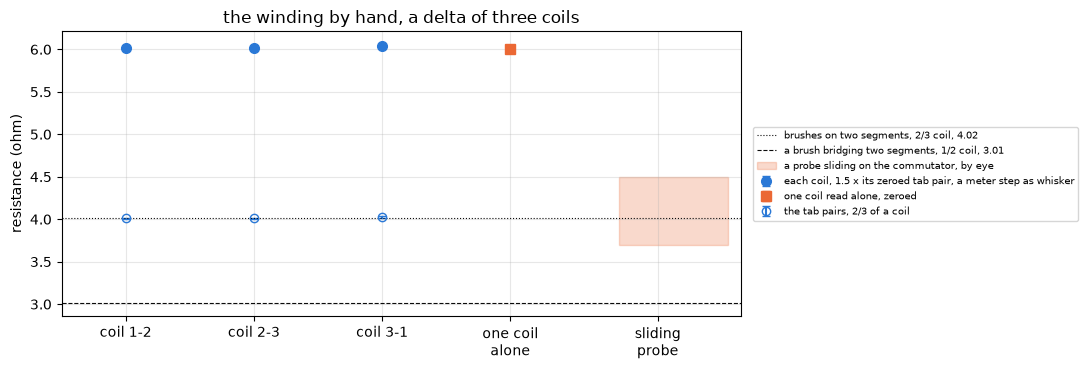

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.errorbar([0, 1, 2], COILS, yerr=1.5 * STEP, fmt="o", ms=7, capsize=3, color=BLUE, label="each coil, 1.5 x its zeroed tab pair, a meter step as whisker")
ax.errorbar([3], [COIL_DIRECT], yerr=STEP, fmt="s", ms=7, capsize=3, color=ORANGE, label="one coil read alone, zeroed")
ax.errorbar([0, 1, 2], PAIRS, yerr=STEP, fmt="o", ms=6, capsize=3, color=BLUE, mfc="none", label="the tab pairs, 2/3 of a coil")
ax.axhline(COILS.mean() * 2 / 3, color=INK, lw=0.8, ls=":", label=f"brushes on two segments, 2/3 coil, {COILS.mean() * 2 / 3:.2f}")
ax.axhline(COILS.mean() / 2, color=INK, lw=0.8, ls="--", label=f"a brush bridging two segments, 1/2 coil, {COILS.mean() / 2:.2f}")
ax.axhspan(3.7, 4.5, xmin=0.82, xmax=0.98, color=ORANGE, alpha=0.25, label="a probe sliding on the commutator, by eye")
ax.set_xticks([0, 1, 2, 3, 4.15], ["coil 1-2", "coil 2-3", "coil 3-1", "one coil\nalone", "sliding\nprobe"]); ax.set_xlim(-0.5, 4.8)
ax.set_ylabel("resistance (ohm)"); ax.set_title("the winding by hand, a delta of three coils")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### The brush path

The terminal resistance of the assembled motor is the leads, the brush path and one tab pair of copper, since the brushes sit on two segments over most of a turn. With the copper and the leads read on their own, the brush path is what is left of a terminal reading taken at the same copper temperature.

The rotor's tab pairs carry no thermometer. The cool run, about an hour after the hand readings in the same room, read the room at 24.7 to 24.9 C on the thermocouple, and the hand readings are taken at that temperature with $\pm$2 C as the bracket. Both are put through the stage 0 thermocouple correction, as rest-resistance's `room_c` is, and the copper is moved to another temperature over the textbook coefficient,

$$R(T_2) = R(T_1) \, \frac{1 + \alpha \, (T_2 - 20)}{1 + \alpha \, (T_1 - 20)}$$

with $\alpha$ = 0.00393 per C. The rotor's part is the median of the three zeroed pairs.

Two terminal readings to hold it against. Rest-resistance's meter route read the motor and its leads at the meter's milliamp, 4.100 ohm in the median over twelve holes, with the copper at `room_c`. Its stall pass read 4.455 ohm at about 0.78 A, with the brush drop in it, and its line through the levels gives `r_stall_ohm` with `v0_brush_v` and a bracket of 0 to 0.5 V on the drop. The stall pass recorded no copper temperature, and the board's NTC (the thermistor on the board) at rest, 25.5 to 25.8 C, stands in for it here.

room proxy: room-c2 and the room probes, 24.7 to 24.9 C read, 24.90 C corrected, +/- 2 C
rotor 4.01 + leads 0.08 = 4.09 ohm at 24.90 C; at room_c 25.50 C 4.100 ohm (+/- 0.032 for the 2 C, +/- 0.02 for the readings)
meter route 4.100 ohm, so the brush path at a milliamp +0.000 +/- 0.052 ohm, +0.0 % +/- 1.3 % of the terminal
stall pass 4.455 ohm at 0.78 A against copper and leads 4.102 ohm at the board's 25.68 C: +8.6 % (+6.9 to +10.4 over the holes), 0.353 ohm, 0.277 V at 0.78 A
r_stall_ohm 4.401 (3.817 to 4.455) under v0_brush_v 0.06 (0.0 to 0.5) V; its brush part over the copper and leads +0.299 ohm (-0.285 to +0.353)
a copper 5 C warmer than the proxy at the stall pass moves the copper by 0.079 ohm, 0.062 V at 0.78 A


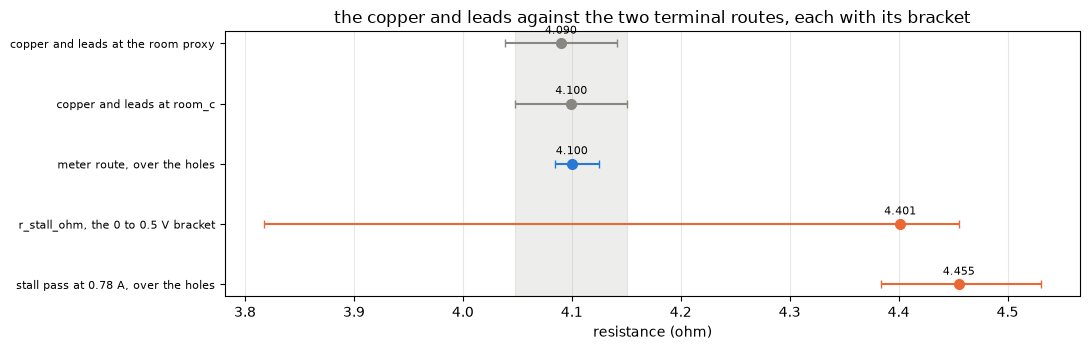

In [10]:
c2 = meter(COOL, "room-c2")                                             # the cool run's second room window, about an hour after the hand readings
temp = b41t.load(COOL / "temp.csv")                                     # the thermocouple through the board phase
cmarks = pd.read_csv(COOL / "marks.csv").set_index("mark")["t_host"]
pre = temp[temp["t_host"] < cmarks["heat 0"]]                           # the room probes' stretch, before any heat
T_ROOM_READ = np.concatenate([c2["value"].to_numpy(), pre["value"].to_numpy()])
T_HAND = float(np.median(t_corr(T_ROOM_READ)))                         # the hand readings' temperature proxy, corrected
T_HAND_BR = 2.0                                                         # its bracket, C


def to_temp(r, t_from, t_to):
    # copper moved from one temperature to another over the textbook coefficient
    return r * (1 + ALPHA * (t_to - 20)) / (1 + ALPHA * (t_from - 20))


R_ROTOR = float(np.median(PAIRS))                                       # the rotor between two segments, zeroed
CU_LEADS = R_ROTOR + LEADS                                              # the copper and the leads at T_HAND
RES = 2 * STEP                                                          # the hand readings' resolution: a step on the pair and a step on the leads
ROOM = RR["room_c"]["value"]
CU_AT_ROOM = to_temp(CU_LEADS, T_HAND, ROOM)
CU_T_BR = abs(to_temp(CU_LEADS, T_HAND, ROOM + T_HAND_BR) - CU_AT_ROOM) # what the 2 C bracket moves it by
R_METER = RR["r_ohms_median_ohm"]["value"]
BRUSH_METER = R_METER - CU_AT_ROOM                                      # the brush path at the meter's milliamp
BRUSH_METER_BR = CU_T_BR + RES
T_STALL = RR["board_ntc_c"]["value"]                                    # the board's NTC, a proxy for the stall pass's copper
CU_AT_STALL = to_temp(CU_LEADS, T_HAND, T_STALL)
R_TERM, I_TERM = RR["r_term_median_ohm"]["value"], RR["r_term_amps"]["value"]
OVER_PCT = (R_TERM / CU_AT_STALL - 1) * 100                              # the terminal at an amp over copper plus leads
OVER_LO = (RR["r_term_median_ohm"]["lo"] / CU_AT_STALL - 1) * 100
OVER_HI = (RR["r_term_median_ohm"]["hi"] / CU_AT_STALL - 1) * 100
EXCESS_V = (R_TERM - CU_AT_STALL) * I_TERM                              # the excess as a drop at the stall pass's current
print(f"room proxy: room-c2 and the room probes, {T_ROOM_READ.min():.1f} to {T_ROOM_READ.max():.1f} C read, {T_HAND:.2f} C corrected, +/- {T_HAND_BR:.0f} C")
print(f"rotor {R_ROTOR:.2f} + leads {LEADS:.2f} = {CU_LEADS:.2f} ohm at {T_HAND:.2f} C; at room_c {ROOM:.2f} C {CU_AT_ROOM:.3f} ohm "
      f"(+/- {CU_T_BR:.3f} for the 2 C, +/- {RES:.2f} for the readings)")
print(f"meter route {R_METER:.3f} ohm, so the brush path at a milliamp {BRUSH_METER:+.3f} +/- {BRUSH_METER_BR:.3f} ohm, "
      f"{BRUSH_METER / R_METER * 100:+.1f} % +/- {BRUSH_METER_BR / R_METER * 100:.1f} % of the terminal")
print(f"stall pass {R_TERM:.3f} ohm at {I_TERM:.2f} A against copper and leads {CU_AT_STALL:.3f} ohm at the board's {T_STALL:.2f} C: "
      f"{OVER_PCT:+.1f} % ({OVER_LO:+.1f} to {OVER_HI:+.1f} over the holes), {R_TERM - CU_AT_STALL:.3f} ohm, {EXCESS_V:.3f} V at {I_TERM:.2f} A")
print(f"r_stall_ohm {RR['r_stall_ohm']['value']:.3f} ({RR['r_stall_ohm']['lo']:.3f} to {RR['r_stall_ohm']['hi']:.3f}) under v0_brush_v "
      f"{RR['v0_brush_v']['value']:.2f} ({RR['v0_brush_v']['lo']:.1f} to {RR['v0_brush_v']['hi']:.1f}) V; "
      f"its brush part over the copper and leads {RR['r_stall_ohm']['value'] - CU_AT_STALL:+.3f} ohm "
      f"({RR['r_stall_ohm']['lo'] - CU_AT_STALL:+.3f} to {RR['r_stall_ohm']['hi'] - CU_AT_STALL:+.3f})")
print(f"a copper 5 C warmer than the proxy at the stall pass moves the copper by {to_temp(CU_LEADS, T_HAND, T_STALL + 5) - CU_AT_STALL:.3f} ohm, "
      f"{(to_temp(CU_LEADS, T_HAND, T_STALL + 5) - CU_AT_STALL) * I_TERM:.3f} V at {I_TERM:.2f} A")

fig, ax = plt.subplots(figsize=(11, 3.6))
rows = [("copper and leads at the room proxy", CU_LEADS, CU_LEADS - to_temp(CU_LEADS, T_HAND, T_HAND - T_HAND_BR) + RES,
         to_temp(CU_LEADS, T_HAND, T_HAND + T_HAND_BR) - CU_LEADS + RES, MUTED),
        ("copper and leads at room_c", CU_AT_ROOM, BRUSH_METER_BR, BRUSH_METER_BR, MUTED),
        ("meter route, over the holes", R_METER, R_METER - RR["r_ohms_median_ohm"]["lo"], RR["r_ohms_median_ohm"]["hi"] - R_METER, BLUE),
        ("r_stall_ohm, the 0 to 0.5 V bracket", RR["r_stall_ohm"]["value"], RR["r_stall_ohm"]["value"] - RR["r_stall_ohm"]["lo"],
         RR["r_stall_ohm"]["hi"] - RR["r_stall_ohm"]["value"], ORANGE),
        ("stall pass at 0.78 A, over the holes", R_TERM, R_TERM - RR["r_term_median_ohm"]["lo"], RR["r_term_median_ohm"]["hi"] - R_TERM, ORANGE)]
for y, (name, v, lo, hi, col) in enumerate(rows):
    ax.errorbar(v, y, xerr=[[lo], [hi]], fmt="o", ms=7, capsize=3, color=col)
    ax.annotate(f"{v:.3f}", (v, y), xytext=(0, 7), textcoords="offset points", fontsize=8, ha="center")
ax.axvspan(CU_AT_ROOM - BRUSH_METER_BR, CU_AT_ROOM + BRUSH_METER_BR, color=MUTED, alpha=0.15)
ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=8); ax.invert_yaxis()
ax.set_xlabel("resistance (ohm)"); ax.set_title("the copper and leads against the two terminal routes, each with its bracket")
ax.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()

The room proxy reads 24.90 C through the correction, and the copper and leads come to 4.09 ohm there and 4.100 ohm at rest-resistance's `room_c` of 25.50 C. The meter route reads 4.100 ohm. So at the meter's milliamp the brush path reads about zero, 0.000 ohm with a bracket of $\pm$0.05 ohm from the temperature proxy and the hand readings' steps, about 1.3 % of the terminal. So the brush path at a milliamp is zero within that resolution, with moderate to high confidence. The confidence stops short of high because the copper's temperature at the hand readings is a proxy an hour away.

At the stall pass's current the picture differs. The terminal reads 4.455 ohm against 4.102 ohm of copper and leads at the board's 25.68 C, 8.6 % over, 6.9 to 10.4 % over the holes' range. That is 0.35 ohm, or 0.28 V at 0.78 A. The stall pass's board connector is in that reading and not in the meter's, most likely milliohms. The rest is the brush path at hundreds of milliamps, or copper warmer than the proxy, or both. Rest-resistance found the stall pass's copper carrying heat from the laps before it, about 2 % from its coldest hole to its warmest, which is about 5 C of copper and moves this comparison by 0.08 ohm, a quarter of the gap. So most of the 8.6 % most likely belongs to the brush path under current, moderate confidence, with the stall pass's copper temperature as the open term.

Read against `r_stall_ohm`, the line's slope under the drop, the copper and leads leave 0.30 ohm for the brush path's ohmic part at the line's own intercept of 0.06 V. At the other end of the bracket, a drop of 0.5 V puts `r_stall_ohm` at 3.82 ohm, under the copper and leads by 0.29 ohm, which no brush path can give. So the copper and leads bound the drop from above. If the copper sat at the board's temperature, the drop at 0.78 A is at most 0.28 V, the whole excess, and copper 5 C warmer lowers that by 0.06 V. That narrows the 0 to 0.5 V bracket to about 0 to 0.3 V, moderate confidence, the limit being the stall pass's copper temperature. The teardown does not split the brush path at an amp into a drop and an ohmic part.

## The gray disc

A dark gray disc sits on the shaft behind the commutator, with three pads, one at each tang. Left, the commutator end with the disc behind it before the wires were cut. Right, the disc bent under a pry and the coil wires cut loose at one pad.

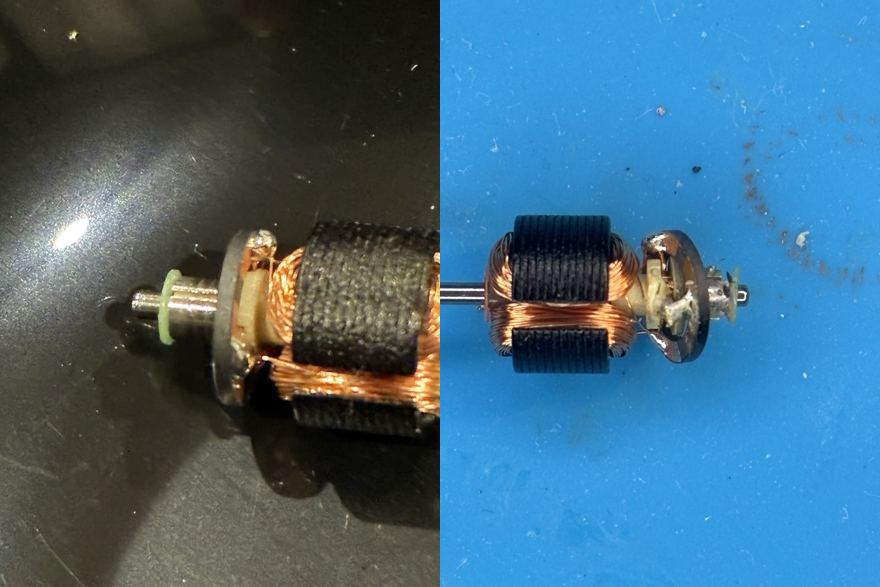

In [11]:
photos(["15-commutator-side-disc-joint.jpg", "21-commutator-disc-bent-wires-cut.jpg"], cols=2)

With the coils still on, the three pads are tied by about 6 ohm of copper, so nothing on the disc reaches the meter. The coil wires were cut loose at one pad, call it pad X. The other two pads, Y and Z, stay tied by the coil between them. Then each pair of pads was read by hand on ohms and on capacitance, hands off the part.

- X to Y read 155 kohm and 9.611 nF.
- X to Z read 162 kohm and 9.555 nF.
- Y to Z read 6.07 ohm, the coil between them, the one-coil reading used above.

The ohms held the same value on two manual ranges. That covers only the meter's own small test voltage, and the sweep further down reads the disc at the bridge's volts. The open probes read 0.090 to 0.092 nF.

The disc reads as a ring of three sectors, each sector a capacitance $C_s$ and a resistance $R_s$ between two neighboring pads. Read from X to Y, the sector XY is in parallel with the sector XZ, since Z is tied to Y by the coil at the meter's slow test. So each reading is two sectors in parallel,

$$C_\mathrm{pair} = 2 C_s, \qquad R_\mathrm{pair} = \frac{R_s}{2}$$

with the open probes' stray taken off the capacitance first.

At a PWM edge the picture changes. The winding's inductance blocks a fast edge, so for the edge's charge the three pads stand apart, each tied only to its segment. With each brush on one segment, X and Y, the terminals see the sector XY in parallel with XZ and ZY in series, 1.5 sectors. With one brush bridging two segments, X and Y together against Z, they see XZ and YZ in parallel, 2 sectors. The same two geometries give the ring's resistance across the terminals on the meter's ohms, 2/3 of $R_s$ and 1/2 of $R_s$.

In [12]:
PAIR_NF = hand("gray disc pad pair cap")                                 # the two pairs through the cut pad
PAIR_KOHM = hand("gray disc pad pair ohm")
STRAY_NF = OPEN_NF.mean()                                               # the open probes' own reading
SECTOR_NF = (PAIR_NF - STRAY_NF) / 2                                    # each pair is two sectors in parallel
SECTOR_KOHM = 2 * PAIR_KOHM
CS_NF, RS_KOHM = SECTOR_NF.mean(), SECTOR_KOHM.mean()
RING_NF = {"each brush on one segment": 1.5 * CS_NF, "a brush bridging two segments": 2.0 * CS_NF}     # at an edge
RING_KOHM = {"each brush on one segment": RS_KOHM / 1.5, "a brush bridging two segments": RS_KOHM / 2}  # across the terminals, DC
print(f"pairs {PAIR_NF[0]:.3f} and {PAIR_NF[1]:.3f} nF, less the {STRAY_NF:.3f} nF stray, so sectors of {SECTOR_NF[0]:.3f} and {SECTOR_NF[1]:.3f} nF, "
      f"mean {CS_NF:.2f} nF")
print(f"pairs {PAIR_KOHM[0]:.0f} and {PAIR_KOHM[1]:.0f} kohm, so sectors of {SECTOR_KOHM[0]:.0f} and {SECTOR_KOHM[1]:.0f} kohm, mean {RS_KOHM:.0f} kohm")
for k in RING_NF:
    print(f"{k}: {RING_NF[k]:.2f} nF at an edge, {RING_KOHM[k]:.0f} kohm across the terminals on the meter's ohms")
print(f"each sector's own time constant R_s C_s = {RS_KOHM * 1e3 * CS_NF * 1e-9 * 1e3:.2f} ms, against a 50 us PWM period")

pairs 9.611 and 9.555 nF, less the 0.091 nF stray, so sectors of 4.760 and 4.732 nF, mean 4.75 nF
pairs 155 and 162 kohm, so sectors of 310 and 324 kohm, mean 317 kohm
each brush on one segment: 7.12 nF at an edge, 211 kohm across the terminals on the meter's ohms
a brush bridging two segments: 9.49 nF at an edge, 158 kohm across the terminals on the meter's ohms
each sector's own time constant R_s C_s = 1.50 ms, against a 50 us PWM period


Each sector is about 4.75 nF and 320 kohm. Across the terminals the ring is about 7.1 nF at an edge with each brush on one segment and about 9.5 nF with a brush bridging two, and about 160 to 210 kohm on the meter's ohms. A sector's own time constant on those ohms is 1.5 ms, thirty PWM periods, so at the PWM rate the ring acts as a capacitor.

Read as fixed resistances, those ohms would put the ring's current at 35 to 47 uA at 7.4 V. That holds only if the ring is linear, and the sweep below shows it is not. A ring varistor, a disc that conducts hard above some voltage to soak up the brushes' sparking, is the part a motor of this kind often carries behind its commutator, and a plain capacitor ring with a resistive leak is the other candidate. The meter's ohms test the part at the meter's own small voltage, so the disc came off the rotor for a sweep to 20 V. It bent under a pry, so it is a thin part, ceramic or a filled polymer.

### The disc off the rotor, disc-iv-1

The disc was pried off the rotor with the commutator's three segments still fused to its pads, so each pad keeps its segment and nothing else ties the pads together. Left, the disc off, with the white and black leads on two of its pads, the commutator's plastic hub, the green washer and the rotor beside it. Middle, its front face, three electrodes, one under each segment. Right, its back face, dark gray and plain.

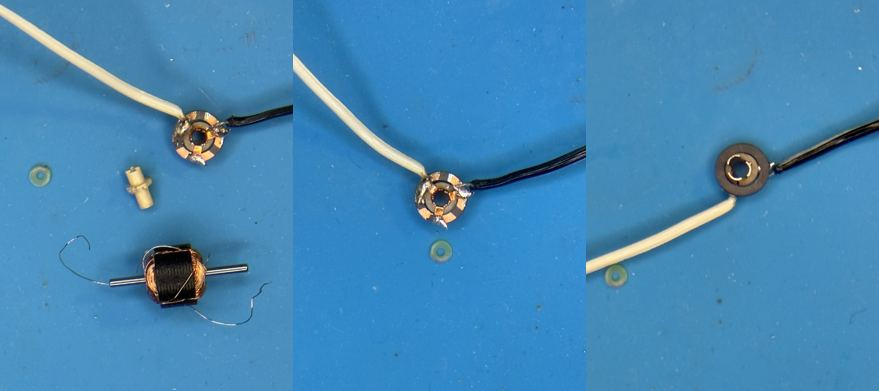

In [13]:
photos(["25-disc-off-hub-washer-rotor.jpg", "26-disc-front-three-electrodes.jpg", "27-disc-back-face.jpg"], cols=3)

Off the rotor each pad pair reads the sector between the two pads in parallel with the other two sectors in series through the third pad. With sectors $a$, $b$ and $c$, the pair across $a$ reads

$$C_\mathrm{pair} = C_a + \frac{C_b \, C_c}{C_b + C_c}, \qquad R_\mathrm{pair} = \frac{R_a \, (R_b + R_c)}{R_a + R_b + R_c}$$

so the three pairs give three equations for the three sectors, solved here with the open probes' stray taken off the capacitance first. The pairs were read by hand, hands off the part, with the white and black leads on two pads and the third pad free. Ohms on a part that may not be linear depend on the meter's test voltage, so the sectors' kohm values are what that test reads and not fixed resistances.

The same arithmetic gives what the brushes see at an edge. With each brush on one segment they read one pad pair. With one brush bridging two segments the two pads are tied, the sector between them is shorted, and the other two sit in parallel.

In [14]:
PADS = ("white-black", "white-free", "black-free")                      # the three pad pairs, named by the leads on the pads
OFF_NF = np.array([hand(f"disc pair {p} cap")[0] for p in PADS]) - STRAY_NF   # by hand, the open probes' stray off
OFF_KOHM = np.array([hand(f"disc pair {p} ohm")[0] for p in PADS])


def pair_of(s, kind):
    # what each pad pair reads with sectors s = (white-black, white-free, black-free): the sector between the two pads
    # in parallel with the other two in series through the third pad
    a, b, c = s
    if kind == "nf":
        par, ser = (lambda x, y: x + y), (lambda x, y: x * y / (x + y))
    else:
        par, ser = (lambda x, y: x * y / (x + y)), (lambda x, y: x + y)
    return np.array([par(a, ser(b, c)), par(b, ser(a, c)), par(c, ser(a, b))])


SEC_NF = least_squares(lambda s: pair_of(s, "nf") - OFF_NF, OFF_NF / 1.5).x       # three equations, three sectors
SEC_KOHM = least_squares(lambda s: pair_of(s, "kohm") - OFF_KOHM, OFF_KOHM * 1.5).x
# the brushes see the ring two ways: each brush on one segment reads one pad pair; a brush bridging two segments ties
# their pads, shorts the sector between them and leaves the other two in parallel
ONE_SEG_NF = OFF_NF
BRIDGE_NF = np.array([SEC_NF[1] + SEC_NF[2], SEC_NF[0] + SEC_NF[2], SEC_NF[0] + SEC_NF[1]])
print("pad pairs by hand, less the stray:", ", ".join(f"{p} {c:.3f} nF {r:.1f} kohm" for p, c, r in zip(PADS, OFF_NF, OFF_KOHM)))
print("sectors solved:", ", ".join(f"{p} {c:.3f} nF {r:.0f} kohm" for p, c, r in zip(PADS, SEC_NF, SEC_KOHM)),
      f"| residuals {np.abs(pair_of(SEC_NF, 'nf') - OFF_NF).max():.1e} nF, {np.abs(pair_of(SEC_KOHM, 'kohm') - OFF_KOHM).max():.1e} kohm")
print(f"the brushes see {ONE_SEG_NF.min():.2f} to {ONE_SEG_NF.max():.2f} nF with each on one segment, "
      f"{BRIDGE_NF.min():.2f} to {BRIDGE_NF.max():.2f} nF with one bridging two; on the rotor the same two geometries read "
      f"{min(RING_NF.values()):.2f} and {max(RING_NF.values()):.2f} nF")
print(f"sector mean {SEC_NF.mean():.2f} nF off the rotor against {CS_NF:.2f} nF read on it")

pad pairs by hand, less the stray: white-black 7.709 nF 225.2 kohm, white-free 8.054 nF 284.3 kohm, black-free 7.912 nF 279.1 kohm
sectors solved: white-black 5.017 nF 300 kohm, white-free 5.478 nF 461 kohm, black-free 5.293 nF 441 kohm | residuals 0.0e+00 nF, 5.7e-14 kohm
the brushes see 7.71 to 8.05 nF with each on one segment, 10.31 to 10.77 nF with one bridging two; on the rotor the same two geometries read 7.12 and 9.49 nF
sector mean 5.26 nF off the rotor against 4.75 nF read on it


The three pairs read 7.71, 8.05 and 7.91 nF with the stray off, and the sectors solve to 5.02 nF between the white and black pads, 5.48 nF between white and free and 5.29 nF between black and free, within 9 % of each other. So the brushes see 7.71 to 8.05 nF with each on one segment and 10.31 to 10.77 nF with one bridging two.

On the rotor the same disc read 4.75 nF a sector, under the 5.02 to 5.48 nF here, and 7.12 and 9.49 nF for the two geometries. The on-rotor reading took the coil between the two tied pads as a short at the meter's slow test and the two pads through the cut pad as equal. The 6 to 15 % between the two readings is not explained here. The disc bent under the pry that took it off, and its leads and contacts differ between the two sittings, and nothing separates those. The spike section below keeps the on-rotor band and checks the off-rotor one beside it.

On ohms the sectors solve to 300 kohm between white and black and 441 and 461 kohm for the other two, a spread of half against 9 % on capacitance. The meter's ohms read a nonlinear part at one low voltage, where a small shift in a sector's curve moves its ohms a lot, which is one reading of that spread. Nothing here tests it.

Then the sweep. The meter sat in series on DC current with its wide microamp range held, and the DPS stepped the leads from 0 to 20 V and back in 1 V steps of 5 s each, its current limit at 2 mA, once with the white lead's side positive and once with the leads swapped. By then the white lead had come off, taking its segment's copper with it, and was soldered again on the free pad, so the sweep reads the black-free pair. Each step is the median of the meter's packets over the last 2.5 s before the DPS's read-back of that step, when the current had settled. A step where the DPS read back under its set volts sat on its current limit, and those steps are drawn apart.

Left, the settled current against the DPS's read-back on log scales, every step of the four legs, up and down in each polarity. A resistor is a line of slope one there. Middle, the local exponent $n = d \ln I / d \ln V$ between neighboring steps, which is one for a resistor. Right, the negative polarity over the positive and the way down over the way up, step by step. The thing to see on the left is the curve bending up, and where it meets the supply's limit.

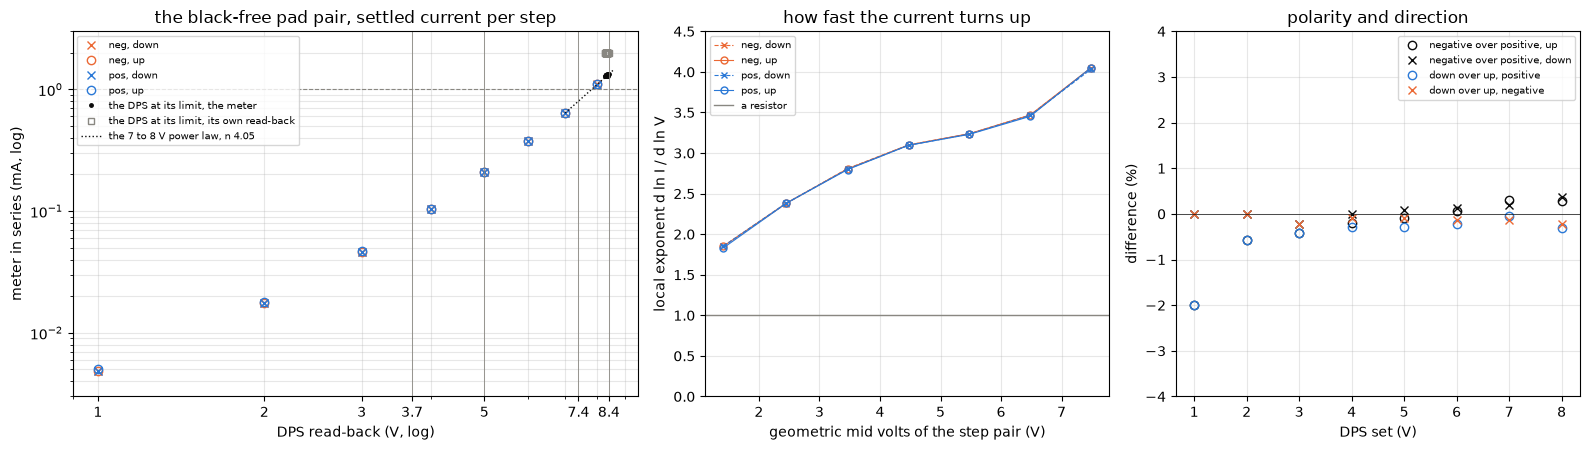

median settled current per step (uA): 1 V 4.9, 2 V 17.7, 3 V 46.5, 4 V 104.2, 5 V 208.0, 6 V 375.2, 7 V 639.7, 8 V 1098.2
V at 1 mA 7.82 V, 7.81 to 7.82 over the four legs
local exponent from 1.85 (1.83 to 1.85) at 1.41 V to 4.04 (4.03 to 4.05) at 7.48 V
negative over positive -2.00 to +0.37 %, down over up -2.00 to +0.00 % (1 to 8 V; at 1 V one count of 0.1 uA is 2 %)
0 V steps read 0.1 to 0.1 uA
at the DPS's limit: 46 steps at 8.27 to 8.39 V, the meter 1.28 to 1.34 mA (median 1.30), the DPS reads 2.00 to 2.00 mA; the meter over the 7 to 8 V power law at the same volts 0.979 to 1.039
the DPS's own current read-back on the free steps: [np.float64(0.0)] mA
pair-cap 8.203 nF less open-cap 0.083 nF = 8.120 nF; pair-ohm 292.2 kohm; by hand the same pair 8.003 nF, 279.1 kohm
as V / I the pair reads 204 kohm at 1 V and 24 kohm at 5 V
the pair at the bridge's levels: 3.7 V 84 uA (84 to 84), 5.0 V 208 uA (208 to 208), 7.4 V 801 uA (799 to 803), 8.4 V 1338 uA (past the free points)


In [15]:
rows = []
for way in ("pos", "neg"):
    d = b41t.load(DISC / f"iv-{way}.csv")                               # the meter in series, every packet
    assert set(d["function"]) == {"DC A"}
    st = pd.read_csv(DISC / f"steps-{way}.csv")                         # host time of each step's read-back, the DPS set and read
    top = int(st["volts_set"].idxmax())
    for i, r in st.iterrows():
        w = d[(d["t_host"] > r["t_host"] - 2.5) & (d["t_host"] <= r["t_host"])]   # the last 2.5 s before the read-back, settled
        rows.append({"way": way, "leg": "up" if i <= top else "down", "volts_set": r["volts_set"], "volts": r["dps_volts"],
                     "dps_ma": r["dps_amps"] * 1e3, "ua": w["value"].median() * 1e6, "n": len(w),
                     "limited": r["volts_set"] - r["dps_volts"] > 0.05})       # the DPS never reached the set volts
DIV = pd.DataFrame(rows)
FREE = DIV[~DIV["limited"] & (DIV["volts_set"] > 0)]
PLATEAU = DIV[DIV["limited"]]


def leg_curve(g):
    # one leg's free points in order of volts: the local exponent d ln I / d ln V between neighbors, and V at 1 mA
    g = g.sort_values("volts")
    v, i = g["volts"].to_numpy(), g["ua"].to_numpy()
    n = np.diff(np.log(i)) / np.diff(np.log(v))
    vm = np.sqrt(v[1:] * v[:-1])                                        # each exponent at the geometric mid volts
    k = np.searchsorted(i, 1000.0)                                      # the first point at or over 1 mA
    v1ma = v[k - 1] * np.exp(np.log(1000.0 / i[k - 1]) / n[k - 1])      # the power law between its neighbors
    return vm, n, v1ma


LEGS = {(w, l): leg_curve(g) for (w, l), g in FREE.groupby(["way", "leg"])}
V1MA = np.array([c[2] for c in LEGS.values()])
N_ALL = np.array([c[1] for c in LEGS.values()])                         # legs x intervals
VM = next(iter(LEGS.values()))[0]
MED = FREE.groupby("volts_set").agg(volts=("volts", "median"), ua=("ua", "median"), lo=("ua", "min"), hi=("ua", "max"))
N_TOP = N_ALL[:, -1]                                                    # the exponent between 7 and 8 V, at the 1 mA point


def ring_ua(v):
    # the pad pair's current at v volts: log-log between the median free points, the 7 to 8 V power law past 8 V
    lv, li = np.log(MED["volts"].to_numpy()), np.log(MED["ua"].to_numpy())
    v = np.asarray(v, float)
    out = np.exp(np.interp(np.log(v), lv, li))
    past = v > MED["volts"].iloc[-1]
    return np.where(past, MED["ua"].iloc[-1] * (v / MED["volts"].iloc[-1]) ** np.median(N_TOP), out)


pw = FREE.pivot_table(index=["volts_set", "leg"], columns="way", values="ua")
SYM_PCT = (pw["neg"] / pw["pos"] - 1) * 100                             # negative against positive at each step and leg
ud = FREE.pivot_table(index=["volts_set", "way"], columns="leg", values="ua")
UPDOWN_PCT = (ud["down"] / ud["up"] - 1) * 100
PL_PRED = ring_ua(PLATEAU["volts"])                                      # what the curve gives at the plateau's own volts
PL_RATIO = PLATEAU["ua"].to_numpy() / PL_PRED
CAPW = {w: meter(DISC, w) for w in ("open-cap", "pair-cap", "pair-ohm")}
PAIR_CAP_NF = float(CAPW["pair-cap"]["nf"].median() - CAPW["open-cap"]["nf"].median())
PAIR_OHM_KOHM = float(CAPW["pair-ohm"]["value"].median() / 1e3)
LEVELS = (3.7, 5.0, 7.4, 8.4)                                            # the bridge's 1S levels and a full 2S pack
LEVEL_UA = {v: float(ring_ua(v)) for v in LEVELS}


def leg_at(g, v):
    # one leg's current at v volts, log-log between its own free points
    g = g.sort_values("volts")
    return float(np.exp(np.interp(np.log(v), np.log(g["volts"]), np.log(g["ua"]))))


LEVEL_UA_BR = {v: (min(leg_at(g, v) for _, g in FREE.groupby(["way", "leg"])), max(leg_at(g, v) for _, g in FREE.groupby(["way", "leg"])))
               for v in (3.7, 5.0, 7.4)}                                # the spread over the four legs, inside the free points

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
for (w, l), g in FREE.groupby(["way", "leg"]):
    ax[0].plot(g["volts"], g["ua"] / 1e3, "o" if l == "up" else "x", ms=6, mfc="none", color=BLUE if w == "pos" else ORANGE, label=f"{w}, {l}")
ax[0].plot(PLATEAU["volts"], PLATEAU["ua"] / 1e3, ".", ms=5, color=INK, label="the DPS at its limit, the meter")
ax[0].plot(PLATEAU["volts"], PLATEAU["dps_ma"], "s", ms=4, mfc="none", color=MUTED, label="the DPS at its limit, its own read-back")
vv = np.linspace(7, 8.6, 30)
ax[0].plot(vv, ring_ua(vv) / 1e3, ":", color=INK, lw=1, label=f"the 7 to 8 V power law, n {np.median(N_TOP):.2f}")
ax[0].axhline(1.0, color=MUTED, lw=0.8, ls="--")
for v in (3.7, 5.0, 7.4, 8.4):
    ax[0].axvline(v, color=MUTED, lw=0.6)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(0.9, 9.5); ax[0].set_ylim(3e-3, 3)
ax[0].set_xticks([1, 2, 3, 3.7, 5, 7.4, 8.4], ["1", "2", "3", "3.7", "5", "7.4", "8.4"]); ax[0].xaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_xlabel("DPS read-back (V, log)"); ax[0].set_ylabel("meter in series (mA, log)")
ax[0].set_title("the black-free pad pair, settled current per step"); ax[0].legend(fontsize=7, loc="upper left"); ax[0].grid(alpha=0.3, which="both")
for (w, l), (vm, n, _) in LEGS.items():
    ax[1].plot(vm, n, "o-" if l == "up" else "x--", ms=5, lw=0.8, mfc="none", color=BLUE if w == "pos" else ORANGE, label=f"{w}, {l}")
ax[1].axhline(1, color=MUTED, lw=1, label="a resistor")
ax[1].set_xlabel("geometric mid volts of the step pair (V)"); ax[1].set_ylabel("local exponent d ln I / d ln V")
ax[1].set_title("how fast the current turns up"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3); ax[1].set_ylim(0, 4.5)
ax[2].plot(SYM_PCT.xs("up", level="leg").index, SYM_PCT.xs("up", level="leg"), "o", mfc="none", color=INK, label="negative over positive, up")
ax[2].plot(SYM_PCT.xs("down", level="leg").index, SYM_PCT.xs("down", level="leg"), "x", color=INK, label="negative over positive, down")
ax[2].plot(UPDOWN_PCT.xs("pos", level="way").index, UPDOWN_PCT.xs("pos", level="way"), "o", mfc="none", color=BLUE, label="down over up, positive")
ax[2].plot(UPDOWN_PCT.xs("neg", level="way").index, UPDOWN_PCT.xs("neg", level="way"), "x", color=ORANGE, label="down over up, negative")
ax[2].axhline(0, color=INK, lw=0.5); ax[2].set_ylim(-4, 4)
ax[2].set_xlabel("DPS set (V)"); ax[2].set_ylabel("difference (%)"); ax[2].set_title("polarity and direction"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("median settled current per step (uA):", ", ".join(f"{v:.0f} V {u:.1f}" for v, u in zip(MED.index, MED["ua"])))
print(f"V at 1 mA {V1MA.mean():.2f} V, {V1MA.min():.2f} to {V1MA.max():.2f} over the four legs")
print(f"local exponent from {N_ALL[:, 0].mean():.2f} ({N_ALL[:, 0].min():.2f} to {N_ALL[:, 0].max():.2f}) at {VM[0]:.2f} V "
      f"to {N_TOP.mean():.2f} ({N_TOP.min():.2f} to {N_TOP.max():.2f}) at {VM[-1]:.2f} V")
print(f"negative over positive {SYM_PCT.min():+.2f} to {SYM_PCT.max():+.2f} %, down over up {UPDOWN_PCT.min():+.2f} to {UPDOWN_PCT.max():+.2f} % "
      f"(1 to 8 V; at 1 V one count of 0.1 uA is {0.1 / MED['ua'].iloc[0] * 100:.0f} %)")
print(f"0 V steps read {DIV[DIV['volts_set'] == 0]['ua'].min():.1f} to {DIV[DIV['volts_set'] == 0]['ua'].max():.1f} uA")
print(f"at the DPS's limit: {len(PLATEAU)} steps at {PLATEAU['volts'].min():.2f} to {PLATEAU['volts'].max():.2f} V, the meter "
      f"{PLATEAU['ua'].min() / 1e3:.2f} to {PLATEAU['ua'].max() / 1e3:.2f} mA (median {PLATEAU['ua'].median() / 1e3:.2f}), the DPS reads "
      f"{PLATEAU['dps_ma'].min():.2f} to {PLATEAU['dps_ma'].max():.2f} mA; the meter over the 7 to 8 V power law at the same volts "
      f"{PL_RATIO.min():.3f} to {PL_RATIO.max():.3f}")
print(f"the DPS's own current read-back on the free steps: {sorted(FREE['dps_ma'].unique())} mA")
print(f"pair-cap {CAPW['pair-cap']['nf'].median():.3f} nF less open-cap {CAPW['open-cap']['nf'].median():.3f} nF = {PAIR_CAP_NF:.3f} nF; "
      f"pair-ohm {PAIR_OHM_KOHM:.1f} kohm; by hand the same pair {hand('disc pair black-free cap')[0]:.3f} nF, {hand('disc pair black-free ohm')[0]:.1f} kohm")
print(f"as V / I the pair reads {1.0 / MED['ua'].iloc[0] * 1e3:.0f} kohm at 1 V and {5.0 / LEVEL_UA[5.0] * 1e3:.0f} kohm at 5 V")
print("the pair at the bridge's levels:", ", ".join(f"{v} V {LEVEL_UA[v]:.0f} uA" + (f" ({LEVEL_UA_BR[v][0]:.0f} to {LEVEL_UA_BR[v][1]:.0f})" if v in LEVEL_UA_BR else " (past the free points)") for v in LEVELS))

The current is smooth and nonlinear from the first volt. In the median of the four legs it reads 4.9 uA at 1 V, 17.7 at 2, 46.5 at 3, 104 at 4, 208 at 5, 375 at 6, 640 at 7 and 1098 uA at 8 V. A resistor through the 1 V point would read 39 uA at 8 V, 28 times less. The local exponent rises steadily from 1.85 between 1 and 2 V to 4.04 between 7 and 8 V, and the four legs agree within 0.02 at every step. The negative polarity against the positive and the way down against the way up agree within 0.4 % from 2 to 8 V. At 1 V they sit 2 % apart, which is one count of the meter's 0.1 uA there, and every 0 V step reads that one count. So the curve has no polarity and no memory over the sweep, high confidence.

From the 9 V setting on, in both polarities and both ways, the DPS reads back 8.27 to 8.39 V and 2.00 mA, while the meter reads 1.28 to 1.34 mA, 1.30 in the median. The DPS's own current read back 0.00 mA on every step under its limit, up to the meter's 1.1 mA at 8 V, so its current reading is coarse at this level and the meter's is the one kept. The meter's plateau readings sit within -2 to +4 % of the 7 to 8 V power law carried on to their own volts. So the plateau at 8.3 V is where the curve met the supply's limit and not a knee of the part.

So the gray disc is a varistor ring, nonlinear and symmetric with a soft knee, high confidence. This pad pair passes 1 mA at 7.82 V, 7.81 to 7.82 over the four legs, with a local exponent of 4.04 there, 4.03 to 4.05. It is not a capacitor ring with a linear leak.

The logged windows read the pair at 8.12 nF less the open probes' 0.083 nF, and 292 kohm, against 7.91 nF and 279 kohm by hand for the same pair, 2.6 % and 4.7 % higher. The white lead's re-soldering sits between the two, heat on the part and a moved lead are the candidates, and one reading of each does not separate them. As volts over current the pair reads 204 kohm at 1 V, under the meter's 292 kohm, so the meter's ohms most likely test it under a volt.

At the bridge's levels the pair passes 84 uA at 3.7 V, 208 uA at 5.0 V and 801 uA at 7.4 V, 799 to 803 over the legs. That is the ring as the brushes see it with each on one segment. A brush bridging two segments puts two sectors in parallel at the full volts, which with equal sectors is at most twice the pair. A full 2S pack at 8.4 V sits past this pair's 1 mA point. The power law carries the pair to about 1.34 mA there, and the plateau's 1.30 mA at 8.3 V agrees.

### Against the spike in inductance and bemf-coast

Inductance found that every fast-decay window on the locked rotor starts with a spike of current at the ON edge, where the bridge turns the drive on. In fast decay the bridge opens all four switches between windows, and in slow decay it shorts the winding through its two low sides. The spike holds about 40 nC over the window's later line at a step of about 4.9 V, and read it as 8 to 9 nF across the terminals. Bemf-coast read the same spike on the spinning rotor at two rails and both decays. A capacitance $C$ charged through a step of $\Delta V$ takes

$$Q = C \, \Delta V$$

so the ring predicts 1.5 to 2 sectors times the step. The step is the window's volts, since before the edge the terminals sit near zero in both decays, with no current between windows in fast decay and the bridge's low sides shorting the winding in slow decay. Inductance's result file carries the spike's charge by duty and not the window's volts, so those two volts are read from the inductance notebook's printed output. Inductance read the spike at one hole only, hole 11, so nothing here tests the 1.5 against the 2 sector geometry by angle.

The figure is the spike's charge against the step, the ring's band between its two geometries, every earlier spike as a point. The thing to see is whether the points fall in the band.

,source,decay,point,volts,nc,ring_lo_nc,ring_hi_nc,as_nf,in_band
0,"inductance, locked, hole 11",fast,25 %,4.920,41.870,35.030,46.700,8.510,True
1,"inductance, locked, hole 11",fast,40 %,4.900,37.760,34.880,46.510,7.710,True
2,"bemf-coast, spinning",slow,5 V 30 %,4.910,11.120,34.990,46.650,2.260,False
3,"bemf-coast, spinning",fast,5 V 30 %,4.920,39.020,35.050,46.730,7.920,True
4,"bemf-coast, spinning",slow,7.4 V 20 %,7.300,35.860,51.980,69.310,4.910,False
5,"bemf-coast, spinning",fast,7.4 V 20 %,7.300,66.910,51.980,69.310,9.160,True
6,"bemf-coast, spinning",slow,7.4 V 40 %,7.290,28.610,51.900,69.200,3.920,False
7,"bemf-coast, spinning",fast,7.4 V 40 %,7.280,40.770,51.830,69.100,5.600,False


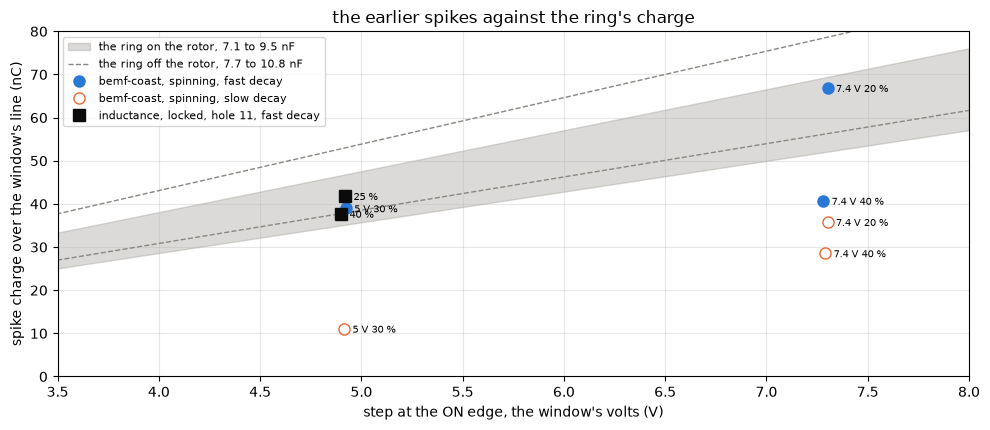

window volts read from the inductance notebook's output: {'25': 4.92, '40': 4.9}
against the ring off the rotor, 7.71 to 10.77 nF: 3 of 8 inside; inductance, locked, hole 11 fast 40 % out (37.8 nC against 37.8 to 52.8)
4 of 8 spikes inside the ring's band; fast decay 4 of 5, slow decay 0 of 3


In [16]:
IND_NB = Path("../inductance/inductance.ipynb")
out_text = "".join("".join(o.get("text", "")) for c in __import__("json").loads(IND_NB.read_text())["cells"] if c["cell_type"] == "code"
                   for o in c.get("outputs", []))
IND_V = {m.group(1): float(m.group(2)) for m in re.finditer(r"(\d+) %, the motor: spike.*?at the window's ([\d.]+) V", out_text, re.S)}   # duty -> window volts
SPIKES = []                                                             # (source, decay, label, volts, nC)
for duty, q in IND["fast_on_edge_spike_nc"].items():
    SPIKES.append(("inductance, locked, hole 11", "fast", f"{duty} %", IND_V[duty], q["value"]))
for point, by_decay in BEMF["spinning_by_point"].items():
    for decay, d in by_decay.items():
        SPIKES.append(("bemf-coast, spinning", decay, point, d["v_on_v"]["value"], d["spike_nc"]["value"]))
SP = pd.DataFrame(SPIKES, columns=["source", "decay", "point", "volts", "nc"])
C_LO, C_HI = min(RING_NF.values()), max(RING_NF.values())
SP["ring_lo_nc"], SP["ring_hi_nc"] = C_LO * SP["volts"], C_HI * SP["volts"]
SP["as_nf"] = SP["nc"] / SP["volts"]
SP["in_band"] = (SP["nc"] >= SP["ring_lo_nc"]) & (SP["nc"] <= SP["ring_hi_nc"])
show(SP.round(2), n=None)

fig, ax = plt.subplots(figsize=(10, 4.4))
v = np.linspace(0, 8, 50)
ax.fill_between(v, C_LO * v, C_HI * v, color=MUTED, alpha=0.3, label=f"the ring on the rotor, {C_LO:.1f} to {C_HI:.1f} nF")
ax.plot(v, ONE_SEG_NF.min() * v, "--", color=MUTED, lw=1, label=f"the ring off the rotor, {ONE_SEG_NF.min():.1f} to {BRIDGE_NF.max():.1f} nF")
ax.plot(v, BRIDGE_NF.max() * v, "--", color=MUTED, lw=1)
style = {("inductance, locked, hole 11", "fast"): dict(marker="s", color=INK, mfc=INK),
         ("bemf-coast, spinning", "fast"): dict(marker="o", color=BLUE, mfc=BLUE),
         ("bemf-coast, spinning", "slow"): dict(marker="o", color=ORANGE, mfc="none")}
for (src, dec), g in SP.groupby(["source", "decay"]):
    ax.plot(g["volts"], g["nc"], ls="none", ms=8, label=f"{src}, {dec} decay", **style[(src, dec)])
    for _, r in g.iterrows():
        ax.annotate(r["point"], (r["volts"], r["nc"]), xytext=(6, -3), textcoords="offset points", fontsize=7)
ax.set_xlim(3.5, 8); ax.set_ylim(0, 80)
ax.set_xlabel("step at the ON edge, the window's volts (V)"); ax.set_ylabel("spike charge over the window's line (nC)")
ax.set_title("the earlier spikes against the ring's charge"); ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"window volts read from the inductance notebook's output: {IND_V}")
SP["in_off_band"] = (SP["nc"] >= ONE_SEG_NF.min() * SP["volts"]) & (SP["nc"] <= BRIDGE_NF.max() * SP["volts"])
print(f"against the ring off the rotor, {ONE_SEG_NF.min():.2f} to {BRIDGE_NF.max():.2f} nF: {SP['in_off_band'].sum()} of {len(SP)} inside; "
      + ", ".join(f"{r['source']} {r['decay']} {r['point']} {'in' if r['in_off_band'] else 'out'} ({r['nc']:.1f} nC against {ONE_SEG_NF.min() * r['volts']:.1f} to {BRIDGE_NF.max() * r['volts']:.1f})"
                  for _, r in SP.iterrows() if r["in_off_band"] != r["in_band"]))
print(f"{SP['in_band'].sum()} of {len(SP)} spikes inside the ring's band; fast decay {SP[SP['decay'] == 'fast']['in_band'].sum()} of "
      f"{(SP['decay'] == 'fast').sum()}, slow decay {SP[SP['decay'] == 'slow']['in_band'].sum()} of {(SP['decay'] == 'slow').sum()}")

Inductance's two spikes, 42 nC at 4.92 V and 38 nC at 4.90 V, fall inside the ring's band, which runs from 35 to 47 nC at that step. So does bemf-coast's fast-decay spike at 5.0 V, 39 nC, and its fast-decay spike at 20 % on 7.4 V, 67 nC against a band of 52 to 69. The ring most likely holds the charge of the fast-decay spike, moderate to high confidence. Against the ring as read off the rotor, 7.7 to 10.8 nF, the dashed lines, the same spikes fall in but inductance's at 40 %, which sits on that band's lower edge, 37.8 nC against 37.8. Earlier work, on another MG90 and board, inferred about 10 to 15 nF across the terminals from the edge charge in its burst model, which is the same order as the ring and somewhat above it.

Four of the earlier spikes do not fall in the band, and the ring does not explain them as read. Bemf-coast's fast-decay spike at 40 % on 7.4 V reads 41 nC, 5.6 nF, under the band's 52 nC. Its three slow-decay spikes read 11 nC at 5.0 V and 36 and 29 nC at 7.4 V, 2.3, 4.9 and 3.9 nF, all under. In slow decay the terminals also start near zero, so the ring would take about the same charge as in fast decay at the same step. The charge in those folds is read over a line through the window, and in slow decay that line starts on the winding's carried current, so how the fold splits the spike from the step is one candidate, and a ring that charges partly through some other path at those points is another. Nothing here separates them. A scope across the terminals and a current probe on one lead, through a few edges in each decay, read the charge the terminals take directly.

### Against the drive-only current

Inductance's fast-decay windows also start on a step of about 20 mA under the ramp, 18.0 mA at 25 % and 23.2 mA at 40 % read at fast decay's own ON edge, and it named a path of a few hundred ohms in parallel with the winding's inductance as a candidate. Bemf-coast's crest sample, the board's sample at the middle of the window, reads over a meter in series by about 4.3 mA per volt of the window over 20 to 40 % duty, falling to zero at 100 %, and its spinning fast-decay windows carry a step of about the same size per volt. The ring is the one path the teardown found across the terminals, so the figure puts each of these at its window's volts beside the ring's swept current at the same volts, on a log scale. Bemf-coast's high-1 ran on 5.0 V, so its reading term at 60 and 80 % is drawn there. The thing to see is the gap.

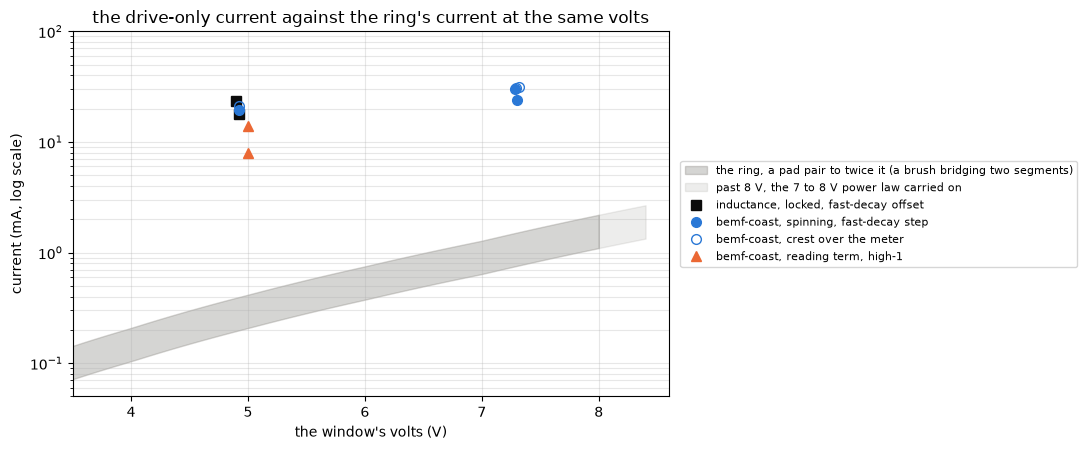

inductance, locked, fast-decay offset, 25 %: 18.0 mA at 4.92 V, the pad pair 198 uA there, 91 x it, 46 x twice it
inductance, locked, fast-decay offset, 40 %: 23.2 mA at 4.90 V, the pad pair 195 uA there, 119 x it, 59 x twice it
bemf-coast, spinning, fast-decay step, 5 V 30 %: 19.4 mA at 4.92 V, the pad pair 198 uA there, 98 x it, 49 x twice it
bemf-coast, spinning, fast-decay step, 7.4 V 20 %: 23.8 mA at 7.30 V, the pad pair 759 uA there, 31 x it, 16 x twice it
bemf-coast, spinning, fast-decay step, 7.4 V 40 %: 29.9 mA at 7.28 V, the pad pair 750 uA there, 40 x it, 20 x twice it
bemf-coast, crest over the meter, 5 V 30 %: 21.3 mA at 4.92 V, the pad pair 198 uA there, 107 x it, 54 x twice it
bemf-coast, crest over the meter, 7.4 V 20 %: 31.6 mA at 7.31 V, the pad pair 764 uA there, 41 x it, 21 x twice it
bemf-coast, crest over the meter, 7.4 V 40 %: 30.7 mA at 7.30 V, the pad pair 756 uA there, 41 x it, 20 x twice it
bemf-coast, reading term, high-1, 60 % on 5.0 V: 13.9 mA at 5.00 V, t

In [17]:
PTS = []                                                                # (source, label, volts, mA)
for duty, q in IND["fast_on_edge_step_corrected_ma"].items():
    PTS.append(("inductance, locked, fast-decay offset", f"{duty} %", IND_V[duty], q["value"]))
for point, by_decay in BEMF["spinning_by_point"].items():
    if "on_edge_step_corrected_ma" in by_decay.get("fast", {}):                # read at fast decay's own ON edge, as inductance's corrected step
        PTS.append(("bemf-coast, spinning, fast-decay step", point, by_decay["fast"]["v_on_v"]["value"], by_decay["fast"]["on_edge_step_corrected_ma"]["value"]))
for point, d in BEMF["meter_by_point"].items():
    PTS.append(("bemf-coast, crest over the meter", point, d["v_on_v"]["value"], d["gap_ma"]["value"]))
for duty in ("60 %", "80 %"):                                           # high-1 ran on 5.0 V; 20 to 40 % are the meter points above
    PTS.append(("bemf-coast, reading term, high-1", f"{duty} on 5.0 V", 5.0, BEMF["reading_term_by_duty"][duty]["value"] * 5.0 * 1e3))
PV = pd.DataFrame(PTS, columns=["source", "point", "volts", "ma"])
PV["ring_ma"] = ring_ua(PV["volts"]) / 1e3                              # the pad pair at the same volts, each brush on one segment
PV["over_ring"] = PV["ma"] / PV["ring_ma"]
PV["over_ring_bridged"] = PV["ma"] / (2 * PV["ring_ma"])                # a brush bridging two segments sees at most twice the pair
STYLE = {"inductance, locked, fast-decay offset": dict(marker="s", color=INK, mfc=INK),
         "bemf-coast, spinning, fast-decay step": dict(marker="o", color=BLUE, mfc=BLUE),
         "bemf-coast, crest over the meter": dict(marker="o", color=BLUE, mfc="none"),
         "bemf-coast, reading term, high-1": dict(marker="^", color=ORANGE, mfc=ORANGE)}
fig, ax = plt.subplots(figsize=(11, 4.6))
vv, vx = np.linspace(3.5, 8.0, 50), np.linspace(8.0, 8.4, 10)
ax.fill_between(vv, ring_ua(vv) / 1e3, 2 * ring_ua(vv) / 1e3, color=MUTED, alpha=0.35, label="the ring, a pad pair to twice it (a brush bridging two segments)")
ax.fill_between(vx, ring_ua(vx) / 1e3, 2 * ring_ua(vx) / 1e3, color=MUTED, alpha=0.15, label="past 8 V, the 7 to 8 V power law carried on")
for src, g in PV.groupby("source", sort=False):
    ax.plot(g["volts"], g["ma"], ls="none", ms=7, label=src, **STYLE[src])
ax.set_yscale("log"); ax.set_xlim(3.5, 8.6); ax.set_ylim(0.05, 100)
ax.set_xlabel("the window's volts (V)"); ax.set_ylabel("current (mA, log scale)")
ax.set_title("the drive-only current against the ring's current at the same volts"); ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
for _, r in PV.iterrows():
    print(f"{r['source']}, {r['point']}: {r['ma']:.1f} mA at {r['volts']:.2f} V, the pad pair {r['ring_ma'] * 1e3:.0f} uA there, {r['over_ring']:.0f} x it, "
          f"{r['over_ring_bridged']:.0f} x twice it")
print(f"the drive-only current is {PV['over_ring_bridged'].min():.0f} to {PV['over_ring'].max():.0f} times the ring's current over every reading")
print("inductance's step as a resistance across the window's volts:",
      ", ".join(f"{IND_V[d] / (q['value'] * 1e-3):.0f} ohm at {d} %" for d, q in IND["fast_on_edge_step_corrected_ma"].items()),
      "; the pad pair as V / I", ", ".join(f"{v / LEVEL_UA[v] * 1e3:.0f} kohm at {v} V" for v in (3.7, 5.0, 7.4)))

Every drive-only reading sits 31 to 119 times over the pad pair's current at its own volts, and 16 to 59 times over twice the pair, the most a brush bridging two segments sees with equal sectors. The narrowest gaps are at 7.4 V, where the ring has turned up to about 0.76 mA against 24 to 32 mA, and bemf-coast's reading term at 80 %, where the term is already falling toward zero. As a resistance, inductance's step is a path of 210 to 270 ohm across the window, while the pad pair reads 24 kohm as volts over current at 5 V and 9 kohm at 7.4 V. So the ring's current is out as the cause of the step and the reading term, high confidence, by a factor of about 16 at the closest and not by the two and a half to three orders of magnitude a linear reading of the meter's ohms gave.

The ring's capacitance takes current only while the terminal voltage moves, which is the spike. Inductance left open whether that capacitance ringing with the winding could give the step, with eddy currents in the rotor iron and the brush contact as the other candidates. The coil runs next take the brushes, the magnets, the can and the ring out of the path, a few at a time.

## The drive-only current on one coil, coil-ring-1, coil-noring-1 and coil-can-1

In a fast-decay window on the locked motor, the shunt current does not start from zero at the bridge's ON edge. The line through the window, carried back to the edge, meets it at about 20 mA, and bemf-coast found the same current per volt in the spinning motor's crest sample. The candidates were the ring's capacitance ringing with the winding, a loss in the iron, and the brush contact. The bare rotor takes them apart. One coil of it, about 6 ohm on its own tooth, the other two cut loose at the third pad earlier, was driven through the board with inductance's fast-1 groups on a 5 V rail, three ways.

- coil-ring-1, the leads on the gray disc's two pads at the coil's ends, so one ring sector sits across the coil and two more in series through the third pad. The leads' free ends read 5.95 ohm.
- coil-noring-1, one lead moved to the coil's free wire end, cut from the third pad, so no sector sits across it. The leads read 6.08 ohm.
- coil-can-1, coil-noring-1's leads with the rotor slid back into the can, its two magnets in place, no end cap and no brushes, the shaft clamped so it cannot turn.

None of the three has brushes. Beside them run the motor's own fast-1 bursts at hole 11 and stage 1's bridge-states controls on the same board, `r`, the 5 ohm resistor, `ra`, the resistor with one 1 mH powdered-iron inductor, and `rab`, the resistor with two.

Every group's sense block is checked against the board's entry as it loads. The reading below takes every fast-decay burst but the first of its group, the first after a change of duty or sign.

In [18]:
ARR = BOARD.pwm_arr                                                    # the PWM counter's crest, ticks
PERIOD = 2 * ARR                                                        # one PWM period, 50 us at 48 ticks per us
TPU = bu.TICKS_PER_US                                                   # timer ticks per us
A_PER_COUNT = 1 / G_CPA                                                 # amps per count of the current channel, current-scale


def pct_of(m):
    # a burst's commanded duty in percent, from its q15 step
    return int(round(abs(m["step_q15"]) * 100 / 32768))


def samples(df, center="trough"):
    # inductance's sample placement: one row per sample with its stream, its code, the tick its aperture closed,
    # the ticks from the nearest window center `tc` and its period `n` on the grid that starts at the first full
    # window after the step (fast decay puts the window on the trough)
    m, ph, sh, ta, tb = bu.phase(df, ARR)
    half = int(BOARD.drive_ticks(m["step_q15"]))                         # half the window, ticks
    k = np.arange(len(df))
    phi0 = m["start_cnt"] if m["start_dir"] == 0 else PERIOD - m["start_cnt"]
    tick = phi0 + bu.STEP_TICKS * k + bu.APERTURE_CLK * bu.TICKS_PER_ADC_CLK
    trough = PERIOD * np.ceil(tick[m["step_index"]] / PERIOD)
    c = ARR if center == "crest" else PERIOD
    origin = trough + c - half
    n = np.floor((tick - origin) / PERIOD).astype(int)
    last = int(np.floor((tick[-1] - origin) / PERIOD))
    tc = ((tick - c) % PERIOD + PERIOD // 2) % PERIOD - PERIOD // 2
    stream = np.where(sh, "sh", np.where(ta, "ta", "tb"))
    s = pd.DataFrame({"stream": stream, "code": df["code"].to_numpy(float), "tick": tick, "tc": tc, "n": n, "full": n < last})
    return s, m, half


def load_groups(root):
    # every burst under root/<group>/burst-K.csv, one row each, the sense block of each group checked against the board
    rows = []
    for gdir in sorted(p for p in Path(root).iterdir() if (p / "meta.json").exists()):
        meta = __import__("json").loads((gdir / "meta.json").read_text())
        BOARD.check_meta(meta, str(results.rel(gdir)))
        for k, df in enumerate(bu.load(gdir)):
            m = bu.meta(df)
            rows.append({"group": gdir.name, "k": k, "first": k == 0, "decay": meta.get("decay", "slow"), "pct": pct_of(m),
                         "sign": 1 if m["step_q15"] > 0 else -1, "df": df})
    return pd.DataFrame(rows)


def load_bs(wire):
    # bridge-states' fast-decay bursts on one stage 1 wiring, the first burst of each duty and sign marked as in load_groups
    folder = BS / wire / "bursts-fast"
    BOARD.check_meta(__import__("json").loads((folder / "meta.json").read_text()), str(results.rel(folder)))
    rows, seen = [], set()
    for df in bu.load(folder):
        m = bu.meta(df)
        key = (pct_of(m), 1 if m["step_q15"] > 0 else -1)
        rows.append({"group": wire, "first": key not in seen, "decay": "fast", "pct": key[0], "sign": key[1], "df": df})
        seen.add(key)
    return pd.DataFrame(rows)


def term_diff(s, sign):
    # tap A less tap B at each tap A sample, tap B interpolated to it, in volts through the terminal-chain line, signed by the step
    a, b = s[s["stream"] == "ta"], s[s["stream"] == "tb"]
    vb = np.interp(a["tick"], b["tick"], b["code"])
    return a["tc"].to_numpy(), a["n"].to_numpy(), (sign * (a["code"].to_numpy() - vb) - C_OFF) / K_CPV


def binned(x, y, lo, hi, w):
    # median, standard error of the median (1.2533 sd / sqrt n) and count of y in w-tick bins of x
    edges = np.arange(lo, hi + w, w)
    idx = np.floor((x - lo) / w).astype(int)
    ok = (idx >= 0) & (idx < len(edges) - 1)
    cen = edges[:-1] + w / 2
    med, se, cnt = np.full(len(cen), np.nan), np.full(len(cen), np.nan), np.zeros(len(cen), int)
    for i, g in pd.DataFrame({"i": idx[ok], "y": y[ok]}).groupby("i"):
        med[i], cnt[i] = g["y"].median(), len(g)
        se[i] = 1.2533 * g["y"].std(ddof=1) / np.sqrt(len(g)) if len(g) > 2 else np.nan
    return cen, med, se, cnt


def fold_points(dfs):
    # every shunt sample (mA over the burst's own pre-step zero) and terminal difference sample (V) of the full periods
    sh, tv = [], []
    for b, df in enumerate(dfs):
        s, m, half = samples(df)
        s = s[(s["n"] >= 0) & s["full"]]
        z = bu.zero(df, ARR)
        x = s[s["stream"] == "sh"]
        sh.append(pd.DataFrame({"tc": x["tc"].to_numpy(), "b": b, "half": half, "ma": (x["code"].to_numpy() - z) * A_PER_COUNT * 1e3}))
        tc, n, v = term_diff(s, 1 if m["step_q15"] > 0 else -1)
        tv.append(pd.DataFrame({"tc": tc, "b": b, "v": v}))
    return pd.concat(sh, ignore_index=True), pd.concat(tv, ignore_index=True)


def data_fold(S, pct, w=4):
    # one set's fast-decay fold at one duty: every burst but the first of its group, 4-tick bins of the shunt,
    # the window's volts (the terminal difference's median inside it) and the return's level (its 2 % quantile)
    g = S[(S["decay"] == "fast") & (S["pct"] == pct) & ~S["first"]]
    sh, tv = fold_points(g["df"])
    x, y, se, n = binned(sh["tc"].to_numpy(), sh["ma"].to_numpy(), -ARR, ARR, w)
    half = int(sh["half"].median())
    inw = (tv["tc"] > -half + 150) & (tv["tc"] < half - 60)
    xv, v, _, _ = binned(tv["tc"].to_numpy(), tv["v"].to_numpy(), -ARR, ARR, 24)
    return dict(x=x, y=y, se=se, half=half, nb=len(g), v_on=float(tv[inw]["v"].median()), v_ret=float(tv["v"].quantile(0.02)), xv=xv, v=v)


SETS = {"motor, fast-1 hole 11": load_groups(FAST1), "coil-can-1": load_groups(COIL["can"]),
        "coil-noring-1": load_groups(COIL["noring"]), "coil-ring-1": load_groups(COIL["ring"])}
CONTROLS = {w: load_bs(w) for w in ("r", "ra", "rab")}
for name, S in {**SETS, **CONTROLS}.items():
    f = S[S["decay"] == "fast"]
    print(f"{name}: {len(S)} bursts, {len(f)} in fast decay at {sorted(f['pct'].unique())} %, "
          f"{len(f[~f['first']])} after the first of each group")

motor, fast-1 hole 11: 30 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
coil-can-1: 30 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
coil-noring-1: 30 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
coil-ring-1: 30 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
r: 20 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
ra: 20 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group
rab: 20 bursts, 20 in fast decay at [np.int64(25), np.int64(40)] %, 16 after the first of each group


### The bridge's edges in fast decay

The offset is read at the bridge's ON edge, so the edge's time matters. Sample-timing read the edges in slow decay, where a dead time comes before the ON edge. In fast decay the bridge turns on from all four switches open, with no dead time, so its edge need not sit where slow decay's does.

The edge is found here on stage 1's controls with a model of the bridge, the leads and the load, run tick by tick. The bridge drives the window's volts inside the window and returns the current through the body diodes outside it, and floats once that current runs out. The load's state is stepped through one timer tick exactly with the matrix exponential, so a fast edge through a small capacitance stays stable, and the shunt amplifier is a first-order lag. On `r` and `ra` at 25 and 40 %, the amplifier's lag and a gain are fitted on the rising edge and the window for each candidate ON lag, and the lag with the least misfit is kept. Then the OFF lag is scanned on `ra`'s OFF edge and return with the amplifier held.

In [19]:
DT = 1.0 / (TPU * 1e6)                                                  # one timer tick, s
INV_DT = 1 / DT
ON, RET, FLOAT = 0, 1, 2                                                # the bridge's three states in fast decay


def discretize(rs, l0, g, c, driven, r_ser):
    # the network bridge - r_ser - terminal (c across it) - rs - (l0 in parallel with g) - back-EMF, as x' = A x + B u
    # with x = [inductor current, terminal volts, charge out of the bridge] and u = [the bridge's volts, the back-EMF],
    # then held over one tick exactly through the matrix exponential, so the fast edge through the ring's c stays
    # stable. The rotor is locked or bare here, so the back-EMF input stays at zero
    den = 1 + rs * g
    vm, vm_e = np.array([-rs / den, 1 / den, 0.0]), np.array([0.0, -1 / den])   # the volts across l0 || g
    i_s, i_s_e = np.array([1.0, 0.0, 0.0]) + g * vm, g * vm_e         # the current through rs: the inductor's plus g's
    ib, ib_u = np.zeros(3), np.zeros(2)
    if driven:                                                          # the bridge drives the terminal through r_ser
        ib[1], ib_u[0] = -1 / r_ser, 1 / r_ser
    A, B = np.zeros((3, 3)), np.zeros((3, 2))
    A[0], B[0] = vm / l0, vm_e / l0
    A[1], B[1] = (ib - i_s) / c, (ib_u - i_s_e) / c
    A[2], B[2] = ib, ib_u
    M = np.zeros((5, 5)); M[:3, :3] = A; M[:3, 3:] = B
    E = expm(M * DT)
    return E[:3, :3], E[:3, 3]                                          # the state's step and the bridge volts' column


def run(net, modes, vb, r_on, r_ret=0.3):
    # step a per-tick schedule of ON and RET (return through the body diodes) ticks; a RET tick whose bridge current
    # would turn negative floats instead (all switches off, no diode conducting), and a floating terminal that swings
    # past the return's clamp conducts again. Returns the shunt current per tick (+ in the window, - in the return)
    # and the terminal volts
    rs, l0, g, c = net
    D = [discretize(rs, l0, g, c, True, r_on), discretize(rs, l0, g, c, True, r_ret), discretize(rs, l0, g, c, False, r_on)]
    x = np.zeros(3)
    sh, vc = np.zeros(len(modes)), np.zeros(len(modes))
    floating = False
    for t in range(len(modes)):
        md = modes[t]
        if md == ON:
            floating = False
        if md == RET and floating:
            md = FLOAT
        xn = D[md][0] @ x + D[md][1] * vb[t]
        i_b = (xn[2] - x[2]) * INV_DT
        if md == FLOAT and modes[t] == RET and xn[1] < vb[t]:          # past the clamp: the diodes conduct again
            floating, md = False, RET
            xn = D[md][0] @ x + D[md][1] * vb[t]
            i_b = (xn[2] - x[2]) * INV_DT
        if md == RET and i_b <= 0:                                      # the return has run out: float
            floating, md = True, FLOAT
            xn = D[md][0] @ x + D[md][1] * vb[t]
            i_b = 0.0
        x = xn
        sh[t] = i_b if md == ON else (-i_b if md == RET else 0.0)
        vc[t] = x[1]
    return sh, vc


def amp(sh, tau):
    # the shunt amplifier as a first-order lag of tau ticks
    a = np.exp(-1.0 / tau)
    return lfilter([1 - a], [1, -a], sh)


def sim_fold(net, half, v_on, v_ret, on_lag, off_lag, tau, gain, periods, r_on, burst=False, gain2=1.0):
    # fast-decay windows centered in each period, the ON edge on_lag ticks after the commanded start and the OFF edge
    # off_lag after the commanded end, from rest, through the amplifier, in mA against ticks from the window center.
    # burst=False returns the last period; burst=True starts on a window's second half, as a burst does, and returns
    # the mean of every period after the first
    P = PERIOD
    tt = np.arange(P * periods) % P
    on = (tt >= ARR - half + on_lag) & (tt < ARR + half + off_lag)
    if burst:
        on[:ARR + on_lag] = False
        on[ARR:ARR + half + off_lag] = True
    sh, vc = run(net, np.where(on, ON, RET), np.where(on, v_on, v_ret), r_on)
    y = amp(sh, tau) * gain * gain2 * 1e3
    if burst:
        return np.arange(P) - ARR, y[P:].reshape(periods - 1, P).mean(axis=0), vc[P:].reshape(periods - 1, P).mean(axis=0)
    return np.arange(P) - ARR, y[-P:], vc[-P:]


# the board on stage 1's controls: the 5 ohm resistor r and the resistor with one 1 mH powdered-iron inductor ra
CAL_FOLDS = {(w, p): data_fold(CONTROLS[w], p) for w in ("r", "ra") for p in (25, 40)}
CAL_NETS = {"r": (BSR["dc_r_ohm"]["r"]["value"], 1e-6, 0.0, 5e-11),
            "ra": (BSR["dc_r_ohm"]["ra"]["value"], BSR["l_fast_ramp_mh"]["ra_25"]["value"] * 1e-3, 0.0, 5e-11)}


def cal_resid(p, on_lag, off_lag, keys, sel):
    # data less model where sel(fold) is true, each bin over its standard error (at least 0.3 mA)
    tau, gain = p
    out = []
    for key in keys:
        f = CAL_FOLDS[key]
        tc, y, _ = sim_fold(CAL_NETS[key[0]], f["half"], f["v_on"], f["v_ret"], on_lag, off_lag, tau, gain, 4, 0.02)
        ok = sel(f) & np.isfinite(f["y"]) & np.isfinite(f["se"])
        out.append(((f["y"] - np.interp(f["x"], tc, y)) / np.maximum(f["se"], 0.3))[ok])
    return np.concatenate(out)


rise = lambda f: (f["x"] >= -f["half"] - 60) & (f["x"] < f["half"] - 20)       # the rising edge and the window
fall = lambda f: (f["x"] > f["half"] - 60) & (f["x"] < f["half"] + 400)       # the OFF edge and the return
# the ON lag: for each candidate, the amplifier's lag and a gain fitted on the rising edge and the window of all four folds
scan = []
for lag in range(4, 46, 2):
    fr = least_squares(cal_resid, [10.0, 1.0], args=(lag, 14, list(CAL_FOLDS), rise), bounds=([1, 0.8], [60, 1.2]))
    scan.append((lag, np.sum(fr.fun ** 2), *fr.x))
scan = np.array(scan)
j = int(np.argmin(scan[:, 1]))
ON_LAG, TAU_A, GAIN_A = int(scan[j, 0]), scan[j, 2], scan[j, 3]
dof = len(cal_resid([TAU_A, GAIN_A], ON_LAG, 14, list(CAL_FOLDS), rise)) - 3
# the OFF lag: ra's OFF edge and return, with the amplifier held
scan_off = np.array([(lag, np.sum(cal_resid([TAU_A, GAIN_A], ON_LAG, lag, [("ra", 25), ("ra", 40)], fall) ** 2)) for lag in range(0, 32, 2)])
OFF_LAG = int(scan_off[np.argmin(scan_off[:, 1]), 0])
SLOW_ON_LAG = np.mean([ST["tap_on_edge_lag_7v4"]["value"], ST["tap_on_edge_lag_3v7"]["value"]])   # sample-timing's slow-decay ON lag
SLOW_OFF_LAG = np.mean([ST["off_edge_lag_7v4"]["value"], ST["off_edge_lag_3v7"]["value"]])
print(f"fast decay: ON edge {ON_LAG} ticks after the commanded start, against slow decay's {SLOW_ON_LAG:.1f} in sample-timing; "
      f"OFF edge {OFF_LAG} ticks after the commanded end, against {SLOW_OFF_LAG:.0f}")
print(f"the amplifier's lag {TAU_A:.2f} ticks, gain {GAIN_A:.4f}, chi2/dof {scan[j, 1] / dof:.0f} at the best ON lag")
print("ON lag scan, chi2/dof:", ", ".join(f"{int(a)}: {b / dof:.0f}" for a, b in scan[:, :2][::2]))

fast decay: ON edge 8 ticks after the commanded start, against slow decay's 39.5 in sample-timing; OFF edge 12 ticks after the commanded end, against 14
the amplifier's lag 2.32 ticks, gain 1.0034, chi2/dof 89 at the best ON lag
ON lag scan, chi2/dof: 4: 94, 8: 89, 12: 98, 16: 156, 20: 283, 24: 518, 28: 968, 32: 1821, 36: 3029, 40: 4534, 44: 6398


The ON edge sits 8 ticks after the commanded start in fast decay, against 39.5 in slow decay from sample-timing, about 0.66 us earlier. The misfit is flat from 4 to 12 ticks and climbs fast past that, so the edge is known to about 4 ticks. The resistor's fit leaves about 1 % of misfit on its edge and its window, which keeps the chi2 high, and only the lag's minimum is used. The OFF edge sits 12 ticks after the commanded end, against 14 in slow decay. The amplifier's lag is 2.3 ticks and the gain 1.0034.

### The ON edge

The fast-decay folds, every burst's shunt samples placed by their time from the window's center and binned in 4 ticks, against time from the bridge's ON edge. Each dotted line is that run's window line, fitted from about 3 us after the edge, where the shaded band ends, to just before the OFF edge, and carried back to the edge. Right, the 5 ohm resistor's own edge over its level, against the fast and slow ON lags. The thing to see is which runs start with a spike, and where each dotted line meets the edge.

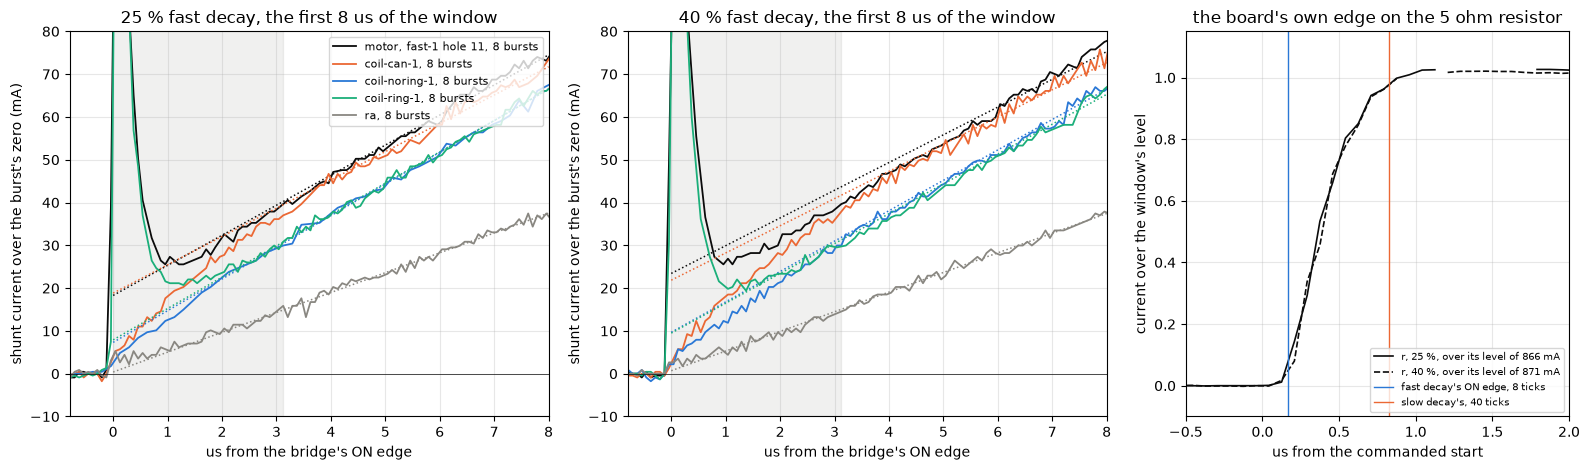

motor, fast-1 hole 11, 25 %: over the window's line +39.6 nC in the spike (0.4 us before to 0.8 us after the edge), -2.0 nC from 0.8 to 3.1 us, at 4.92 V
motor, fast-1 hole 11, 40 %: over the window's line +31.5 nC in the spike (0.4 us before to 0.8 us after the edge), -9.1 nC from 0.8 to 3.1 us, at 4.90 V
coil-can-1, 25 %: over the window's line -17.2 nC in the spike (0.4 us before to 0.8 us after the edge), -7.8 nC from 0.8 to 3.1 us, at 4.92 V
coil-can-1, 40 %: over the window's line -20.9 nC in the spike (0.4 us before to 0.8 us after the edge), -13.5 nC from 0.8 to 3.1 us, at 4.90 V
coil-noring-1, 25 %: over the window's line -2.4 nC in the spike (0.4 us before to 0.8 us after the edge), -0.5 nC from 0.8 to 3.1 us, at 4.93 V
coil-noring-1, 40 %: over the window's line -7.9 nC in the spike (0.4 us before to 0.8 us after the edge), -6.2 nC from 0.8 to 3.1 us, at 4.91 V
coil-ring-1, 25 %: over the window's line +46.4 nC in the spike (0.4 us before to 0.8 us after the edge), +4.5 nC f

In [20]:
LOOK = {"motor, fast-1 hole 11": INK, "coil-can-1": ORANGE, "coil-noring-1": BLUE, "coil-ring-1": "#1baf7a", "ra": MUTED}
LOOK_FOLDS = {name: {p: data_fold(SETS[name] if name in SETS else CONTROLS[name], p) for p in (25, 40)} for name in LOOK}


def window_line(f):
    # the line through the window from about 3 us after the ON edge to 20 ticks before the OFF edge
    on, off = -f["half"] + ON_LAG, f["half"] + OFF_LAG
    sel = (f["x"] > on + 151) & (f["x"] < off - 20) & np.isfinite(f["y"])
    return np.polyfit(f["x"][sel], f["y"][sel], 1)


def charge(f, a, b):
    # the fold over the window's line, summed over ticks a to b from the ON edge, in nC (mA x us)
    on = -f["half"] + ON_LAG
    ln = window_line(f)
    sel = (f["x"] >= on + a) & (f["x"] < on + b) & np.isfinite(f["y"])
    return float(np.sum(f["y"][sel] - np.polyval(ln, f["x"][sel])) * 4 / TPU)


fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for j, pct in enumerate((25, 40)):
    for name, col in LOOK.items():
        f = LOOK_FOLDS[name][pct]
        on = -f["half"] + ON_LAG
        t = (f["x"] - on) / TPU                                         # us from the bridge's ON edge
        ok = np.isfinite(f["y"])
        ax[j].plot(t[ok], f["y"][ok], "-", lw=1.3, color=col, label=f"{name}, {f['nb']} bursts")
        tt = np.linspace(0, 8, 50)
        ax[j].plot(tt, np.polyval(window_line(f), on + tt * TPU), ":", lw=1.1, color=col)   # the window's line read back to the edge
    ax[j].axvspan(0, 150 / TPU, color=MUTED, alpha=0.12)
    ax[j].axhline(0, color=INK, lw=0.5)
    ax[j].set_xlim(-0.8, 8); ax[j].set_ylim(-10, 80)
    ax[j].set_xlabel("us from the bridge's ON edge"); ax[j].set_ylabel("shunt current over the burst's zero (mA)")
    ax[j].set_title(f"{pct} % fast decay, the first 8 us of the window"); ax[j].grid(alpha=0.3)
ax[0].legend(fontsize=8, loc="upper right")
for pct, ls in ((25, "-"), (40, "--")):
    f = CAL_FOLDS[("r", pct)]
    t = (f["x"] + f["half"]) / TPU                                      # us from the commanded start
    level = np.nanmedian(f["y"][(f["x"] > -f["half"] + 150) & (f["x"] < f["half"] - 20)])
    ax[2].plot(t, f["y"] / level, ls, lw=1.2, color=INK, label=f"r, {pct} %, over its level of {level:.0f} mA")
ax[2].axvline(ON_LAG / TPU, color=BLUE, lw=1, label=f"fast decay's ON edge, {ON_LAG} ticks")
ax[2].axvline(SLOW_ON_LAG / TPU, color=ORANGE, lw=1, label=f"slow decay's, {SLOW_ON_LAG:.0f} ticks")
ax[2].set_xlim(-0.5, 2); ax[2].set_ylim(-0.1, 1.15)
ax[2].set_xlabel("us from the commanded start"); ax[2].set_ylabel("current over the window's level")
ax[2].set_title("the board's own edge on the 5 ohm resistor"); ax[2].legend(fontsize=7, loc="lower right"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Q = pd.DataFrame([{"set": name, "pct": pct, "spike_nc": charge(LOOK_FOLDS[name][pct], -20, 40), "tail_nc": charge(LOOK_FOLDS[name][pct], 40, 150),
                   "v_on": LOOK_FOLDS[name][pct]["v_on"]} for name in LOOK for pct in (25, 40)]).set_index(["set", "pct"])
for (name, pct), r in Q.iterrows():
    print(f"{name}, {pct} %: over the window's line {r['spike_nc']:+.1f} nC in the spike (0.4 us before to 0.8 us after the edge), "
          f"{r['tail_nc']:+.1f} nC from 0.8 to 3.1 us, at {r['v_on']:.2f} V")
RING_TAIL = {p: Q.loc[("coil-ring-1", p), "tail_nc"] - Q.loc[("coil-noring-1", p), "tail_nc"] for p in (25, 40)}
print("the ring's tail, coil-ring-1 less coil-noring-1 from 0.8 to 3.1 us:", ", ".join(f"{v:+.1f} nC at {p} %" for p, v in RING_TAIL.items()))

The motor and coil-ring-1 start on a spike that runs off the top of the plot and falls back within about a microsecond. coil-noring-1 and coil-can-1 show none. Over the window's line, from 0.4 us before the edge to 0.8 us after it, the spike holds 40 and 32 nC on the motor at 25 and 40 %, 46 and 41 nC on coil-ring-1, and -2 and -8 nC on coil-noring-1, where the sign is the window's own early shortfall under its line. So the ring sector makes the spike, high confidence. From 0.8 to 3.1 us coil-ring-1 sits 5.0 and 7.5 nC over coil-noring-1, a slower part of the ring's charge. After about 3 us the two bare coil runs lie on each other.

The dotted lines tell the rest. Without the ring the bare coil's line still meets the edge at about 7 to 10 mA, where ra's meets it at about zero. In the can the same coil's line meets the edge at about 18 to 22 mA, near the motor's. In the can and on the bare coil the current does not jump onto its line at the edge. It starts within a few milliamps of zero and climbs onto the line over the first 2 to 3 us.

On the resistor the current starts to rise 8 ticks after the commanded start and is near its level by slow decay's 40. Inductance read its step at slow decay's lag, 17.5 and 21.5 mA. Read at the fast-decay edge, the same windows give the motor's offsets in the next section.

### The offset at the ON edge

Burst by burst, the window's line from 150 ticks after the commanded start, about 3 us after the ON edge, to 20 ticks before the commanded end, read at the fast-decay ON edge, is the offset. A line through the return's middle, read back to the OFF edge, against the window's line there, is the drop at the OFF edge. An inductor alone gives zero for both. A conductance $G$ across the inductance carries $G V$ while the volts across the inductance are $V$. At the ON edge the terminal jumps from about zero to the window's volts, so $G$ adds about $G V_\mathrm{on}$, and at the OFF edge it jumps from the window's volts to the return's, about -6 V, so the current drops by about $G (V_\mathrm{on} + |V_\mathrm{ret}|)$. The ratio of the two is the ratio of the jumps, about 2.2, which the right panel marks for each run. Each offset is the mean over the bursts with its standard error.

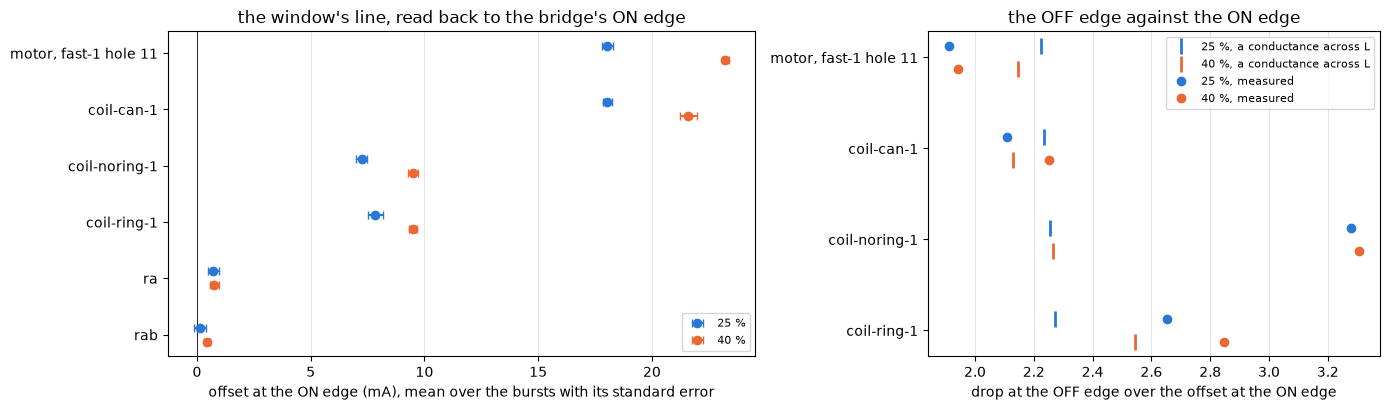

motor, fast-1 hole 11, 25 %: offset +18.04 +/- 0.25 mA over 8 bursts at 4.92 V, 3.58 +/- 0.05 mS of the ON jump; OFF drop +34.5 mA, 1.91 x the offset (a conductance gives 2.22); offset over the window's slope 2.55 us
motor, fast-1 hole 11, 40 %: offset +23.23 +/- 0.14 mA over 8 bursts at 4.90 V, 4.43 +/- 0.03 mS of the ON jump; OFF drop +45.1 mA, 1.94 x the offset (a conductance gives 2.15); offset over the window's slope 3.57 us
coil-can-1, 25 %: offset +18.05 +/- 0.21 mA over 8 bursts at 4.92 V, 3.60 +/- 0.04 mS of the ON jump; OFF drop +38.0 mA, 2.11 x the offset (a conductance gives 2.23); offset over the window's slope 2.68 us
coil-can-1, 40 %: offset +21.61 +/- 0.36 mA over 8 bursts at 4.90 V, 4.08 +/- 0.07 mS of the ON jump; OFF drop +48.7 mA, 2.25 x the offset (a conductance gives 2.13); offset over the window's slope 3.40 us
coil-noring-1, 25 %: offset +7.23 +/- 0.25 mA over 8 bursts at 4.93 V, 1.45 +/- 0.05 mS of the ON jump; OFF drop +23.7 mA, 3.28 x the offset (a conductanc

In [21]:
def edges(df):
    # one burst read for its edges: a line through the window from 150 ticks after the commanded start (about 3 us
    # after the ON edge, past the ring's tail) to 20 before the commanded end, read at the bridge's fast-decay ON edge
    # (the offset) and OFF edge; a line through the return's middle read back at the OFF edge (the drop under the
    # window's top); the window's volts, the floating terminal just before it and the return's lowest
    s, m, half = samples(df)
    s = s[(s["n"] >= 0) & s["full"]]
    z = bu.zero(df, ARR)
    sh = s[s["stream"] == "sh"]
    y = (sh["code"].to_numpy() - z) * A_PER_COUNT * 1e3
    tc = sh["tc"].to_numpy()
    on, off = -half + ON_LAG, half + OFF_LAG
    win = (tc >= -half + 150) & (tc <= half - 20)
    lw = np.polyfit(tc[win], y[win], 1)
    ret = (tc > off + 120) & (y < -8)                                   # the return, past the ring's swing
    if ret.sum() < 6:
        return None
    keep = tc[ret] < np.quantile(tc[ret], 0.8)                          # its linear middle, the tail where it runs out left off
    lr = np.polyfit(tc[ret][keep], y[ret][keep], 1)
    tv, nv, v = term_diff(s, 1 if m["step_q15"] > 0 else -1)
    v_on = float(np.median(v[(tv > -half + 150) & (tv < half - 60)]))
    v_pre = float(np.median(v[(tv < -half - 60) & (tv > -ARR + 60)]))
    v_ret = float(np.quantile(v, 0.02))
    return {"step_ma": np.polyval(lw, on), "drop_ma": np.polyval(lw, off) + np.polyval(lr, off), "slope_ma_us": lw[0] * TPU,
            "v_on": v_on, "jump_on": v_on - v_pre, "jump_off": v_on - v_ret}


rows = []
for name, S in {**SETS, "ra": CONTROLS["ra"], "rab": CONTROLS["rab"]}.items():
    for pct in (25, 40):
        for _, b in S[(S["decay"] == "fast") & (S["pct"] == pct) & ~S["first"]].iterrows():
            e = edges(b["df"])
            if e is not None:
                rows.append({"set": name, "pct": pct, "sign": b["sign"], **e})
E = pd.DataFrame(rows)
E["g_on_ms"] = E["step_ma"] / E["jump_on"]                              # the offset per volt of the ON edge's jump
E["step_over_slope_us"] = E["step_ma"] / E["slope_ma_us"]
se = lambda x: x.std(ddof=1) / np.sqrt(len(x))
STEPS = E.groupby(["set", "pct"]).agg(n=("step_ma", "size"), step=("step_ma", "mean"), step_se=("step_ma", se),
                                      drop=("drop_ma", "mean"), drop_se=("drop_ma", se), g_on=("g_on_ms", "mean"), g_on_se=("g_on_ms", se),
                                      slope=("slope_ma_us", "mean"), v_on=("v_on", "mean"), jump_on=("jump_on", "mean"),
                                      jump_off=("jump_off", "mean"), sos=("step_over_slope_us", "mean"))
STEPS["drop_over_step"] = STEPS["drop"] / STEPS["step"]
STEPS["mirror"] = STEPS["jump_off"] / STEPS["jump_on"]                  # what a conductance across the inductance gives for that ratio
ORDER = ["motor, fast-1 hole 11", "coil-can-1", "coil-noring-1", "coil-ring-1", "ra", "rab"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
for k, pct in enumerate((25, 40)):
    g = STEPS.xs(pct, level="pct").reindex(ORDER)
    yy = np.arange(len(ORDER)) + (k - 0.5) * 0.25
    ax[0].errorbar(g["step"], yy, xerr=g["step_se"], fmt="o", ms=6, capsize=3, color=(BLUE, ORANGE)[k], label=f"{pct} %")
    ax[1].errorbar(g["drop_over_step"].iloc[:4], yy[:4], fmt="o", ms=6, color=(BLUE, ORANGE)[k], label=f"{pct} %, measured")
    ax[1].plot(g["mirror"].iloc[:4], yy[:4], "|", ms=12, mew=2, color=(BLUE, ORANGE)[k], label=f"{pct} %, a conductance across L")
ax[0].set_yticks(range(len(ORDER)), ORDER); ax[1].set_yticks(range(4), ORDER[:4])
for a in ax:
    a.invert_yaxis(); a.grid(alpha=0.3, axis="x"); a.legend(fontsize=8)
ax[0].axvline(0, color=INK, lw=0.6)
ax[0].set_xlabel("offset at the ON edge (mA), mean over the bursts with its standard error")
ax[0].set_title("the window's line, read back to the bridge's ON edge")
ax[1].set_xlabel("drop at the OFF edge over the offset at the ON edge"); ax[1].set_title("the OFF edge against the ON edge")
plt.tight_layout(); plt.show()
for (name, pct), r in STEPS.reindex(ORDER, level="set").iterrows():
    print(f"{name}, {pct} %: offset {r['step']:+.2f} +/- {r['step_se']:.2f} mA over {int(r['n'])} bursts at {r['v_on']:.2f} V, "
          f"{r['g_on']:.2f} +/- {r['g_on_se']:.2f} mS of the ON jump; OFF drop {r['drop']:+.1f} mA, {r['drop_over_step']:.2f} x the offset "
          f"(a conductance gives {r['mirror']:.2f}); offset over the window's slope {r['sos']:.2f} us")
DIR_SLOPE = E.pivot_table(index=["set", "pct"], columns="sign", values="slope_ma_us", aggfunc="mean")
for (name, pct), r in DIR_SLOPE.reindex(ORDER, level="set").iterrows():
    print(f"{name}, {pct} %: the window's slope {r[1]:.2f} mA/us forward, {r[-1]:.2f} reverse, reverse {(r[-1] / r[1] - 1) * 100:+.1f} %")

The bare coil without the ring carries an offset of 7.2 $\pm$ 0.3 mA at 25 % and 9.5 $\pm$ 0.2 mA at 40 %, at 4.9 V. With the ring across it, 7.8 $\pm$ 0.3 and 9.5 $\pm$ 0.2 mA, the same within two standard errors. Back in the can the same coil carries 18.1 $\pm$ 0.2 and 21.6 $\pm$ 0.4 mA, 2.5 and 2.3 times the bare coil, against the motor's 18.0 $\pm$ 0.3 and 23.2 $\pm$ 0.1 mA. ra carries 0.7 and 0.8 mA and rab 0.1 and 0.5 mA, so the board's own edges give under a milliamp of it. So an offset survives on a bare coil with no brushes, no magnets, no can and no ring, and grows to about the motor's once the can and the magnets come back, high confidence. The ring is not needed for it.

The OFF edge agrees with a conductance across the inductance on the motor and in the can. The motor drops 1.9 times its offset against 2.2 for a conductance, and the coil in the can 2.1 and 2.3 against 2.2 and 2.1. The bare coil drops 3.3 times its offset. ra drops 5 and 9 mA at its OFF edge with no offset at all, a board effect at the OFF edge that every run carries, and the bare coil's drops sit 7 and 10 mA over what its offsets give through a conductance, about ra's size.

One thing in the can differs by direction. Its window's slope reads 7.3 and 11.7 % lower in reverse than forward at 25 and 40 %, where the motor at hole 11 and the bare coil read within 2 % of forward in reverse. The slope over a window is the volts over the inductance, so in the can the coil's inductance most likely depends on which way its current runs against the magnets, and the folds below mix both directions under one $L_0$. That is why the can's 40 % fold splits into two tracks in the second half of its window. It is one coil at one angle in the can, and it is not followed further here.

### A conductance across the inductance

The offsets say that a current in proportion to the volts flows beside the inductance. The model that says so is the copper $R_s$ in series with the inductance $L_0$, a conductance $G$ across $L_0$, and the ring's capacitance $C$ across the terminals, fed by the board model above,

$$Y(s) = s C + \frac{1}{R_s + \left( \dfrac{1}{s L_0} + G \right)^{-1}}$$

Fitted to both duties at once are $L_0$, $G$, $C$, a zero offset per fold within 5 mA, and a gain held within 0.01 % of the calibration's, since a free gain trades against $L_0$ and $G$. $R_s$ is held, the motor's at hole 11 from rest-resistance's stall pass and the coil's from the hand reading of its leads. The fit band runs from 150 ticks after the ON edge, past the spike and the ring's slower charge, to the end of the floating stretch after the return. The spike enters only through its charge over the window's line, so $C$ follows the spike while the spike's shape stays out of $G$. With no ring across the coil, $C$ runs onto its lower bound, and for the 1 sigma it is held there. The same fit with $G$ = 0, an inductor alone, is the null. $G$ is a pure conductance here, so a part of the current that builds over a microsecond or two shows up as a misfit from 0.8 to 3.1 us, outside the band.

The product $G L_0$ is a time, the network's own. One coil in parallel with two in series scales the whole impedance of a coil by one factor, coupled or not, and leaves $G L_0$ unchanged, so it compares the motor's terminals with one coil without knowing how the coils couple.

In [22]:
PARAMS = {"M0": {"l0": (0.65e-3, 0.2e-3, 3e-3)},                                # an inductor alone
          "A1": {"l0": (0.65e-3, 0.2e-3, 3e-3), "g": (3e-3, 0, 0.05)}}           # the inductor with a conductance across it
NUIS = {"c": (8e-9, 4e-9, 14e-9), "gain": (1.0, 0.9999, 1.0001), "off": (0.0, -5.0, 5.0)}   # the ring, a held gain, a zero offset per fold
NPER = 11                                                               # a half window and ten full periods, from rest


def regions(f):
    # the stretches of one fold in ticks from the trough: the spike, the ring's tail, the window from about 3 us
    # after the ON edge, the OFF edge, the return and the floating stretch after it
    on, off = -f["half"] + ON_LAG, f["half"] + OFF_LAG
    after = (f["x"] > off + 20) & np.isfinite(f["y"])
    ret_end = f["x"][after & (f["y"] < -2)].max() if np.any(after & (f["y"] < -2)) else off + 400
    return {"spike": (on - 20, on + 40), "tail": (on + 40, on + 150), "window": (on + 150, off - 20),
            "OFF edge": (off - 20, off + 100), "return": (off + 100, ret_end), "after return": (ret_end, ret_end + 150)}


def model_fold(model, p, rs, f, j):
    net = (rs, p["l0"], p.get("g", 0.0), p["c"])
    tc, y, vc = sim_fold(net, f["half"], f["v_on"], f["v_ret"], ON_LAG, OFF_LAG, TAU_A, p[f"gain{j}"], NPER, 0.05, burst=True, gain2=GAIN_A)
    return tc, y + p[f"off{j}"], vc


def fit_net(model, folds, rs, c_bounds=None):
    # least squares over the band from 150 ticks after the ON edge to the end of the floating stretch, both duties at
    # once, plus the spike's charge over the window's line as one more residual with a 1 nC tolerance, so the ring's
    # capacitance stays tied to the spike while the spike's shape and the ring's tail stay out of G
    names = list(PARAMS[model]) + ["c"] + [f"gain{j}" for j in range(len(folds))] + [f"off{j}" for j in range(len(folds))]
    start = {**PARAMS[model], **NUIS, **({"c": c_bounds} if c_bounds else {})}
    base = lambda n: n.rstrip("0123456789") if n.startswith(("gain", "off")) else n
    x0, lo, hi = (np.array([start[base(n)][i] for n in names]) for i in range(3))
    scale = np.where(np.abs(x0) > 0, np.abs(x0), 1.0)

    def resid(z, full=False):
        p = dict(zip(names, z * scale))
        out, parts = [], []
        for j, f in enumerate(folds):
            tc, ym, vm = model_fold(model, p, rs, f, j)
            yi = np.interp(f["x"], tc, ym)
            R = regions(f)
            band = (f["x"] >= R["window"][0]) & (f["x"] < R["after return"][1]) & np.isfinite(f["y"]) & np.isfinite(f["se"])
            out.append(((f["y"] - yi) / np.maximum(f["se"], 0.5))[band])
            ln_sel = (f["x"] > R["window"][0] + 1) & (f["x"] < R["window"][1]) & np.isfinite(f["y"])
            ln = np.polyfit(f["x"][ln_sel], f["y"][ln_sel], 1)
            zs = (f["x"] >= R["spike"][0]) & (f["x"] < R["spike"][1]) & np.isfinite(f["y"])
            q_data = np.sum(f["y"][zs] - np.polyval(ln, f["x"][zs])) * 4 / TPU            # mA us = nC
            q_model = np.sum(yi[zs] - np.polyval(ln, f["x"][zs])) * 4 / TPU
            out.append(np.array([q_data - q_model]))
            parts.append((tc, ym, yi))
        return (np.concatenate(out), parts) if full else np.concatenate(out)

    r = least_squares(resid, x0 / scale, bounds=(lo / scale, hi / scale), x_scale="jac", max_nfev=400)
    res, parts = resid(r.x, full=True)
    dof = max(len(res) - len(r.x), 1)
    chi2 = float(np.sum(res ** 2) / dof)
    # 1 sigma from the Jacobian, scaled by the reduced chi2. With no ring across the coil the ring's c has nothing to hold
    # it and runs onto its lower bound, where its column is about zero and the inverse blows up every other sigma, so
    # a c sitting on its bound is held there for the sigmas
    x = r.x * scale
    free = np.array([not (n == "c" and x[i] <= lo[i] * 1.01) for i, n in enumerate(names)])
    sd = np.zeros(len(names))
    sd[free] = np.sqrt(np.diag(np.linalg.inv(r.jac[:, free].T @ r.jac[:, free]) * chi2)) * scale[free]
    return dict(zip(names, x)), dict(zip(names, sd)), chi2, parts


RS_FIT = {"motor, fast-1 hole 11": (RR["r_term_by_hole"][11], None),   # hole 11's terminal resistance at 100 %, rest-resistance
          "coil-can-1": (hand("coil noring leads ohm")[0], (2e-10, 1e-11, 3e-9)),   # the coil and its leads by hand; no ring across it
          "coil-noring-1": (hand("coil noring leads ohm")[0], (2e-10, 1e-11, 3e-9)),
          "coil-ring-1": (hand("coil ring leads ohm")[0], None)}
FOLDS = {name: [LOOK_FOLDS[name][25], LOOK_FOLDS[name][40]] for name in SETS}   # the folds drawn above
FITS = {}
for name, (rs, cb) in RS_FIT.items():
    FITS[name] = {m: fit_net(m, FOLDS[name], rs, cb) for m in ("M0", "A1")}
    p, sd, chi2, _ = FITS[name]["A1"]
    gl, gl_sd = p["g"] * p["l0"] * 1e6, p["g"] * p["l0"] * 1e6 * np.hypot(sd["g"] / p["g"], sd["l0"] / p["l0"])
    print(f"{name}: G {p['g'] * 1e3:.2f} +/- {sd['g'] * 1e3:.2f} mS ({1 / p['g']:.0f} ohm), L0 {p['l0'] * 1e3:.3f} +/- {sd['l0'] * 1e3:.3f} mH, "
          f"G x L0 {gl:.2f} +/- {gl_sd:.2f} us, ring {p['c'] * 1e9:.2f} nF, chi2/dof {chi2:.1f} against {FITS[name]['M0'][2]:.0f} for the inductor alone "
          f"(R_s {rs:.3f} ohm)")

motor, fast-1 hole 11: G 4.62 +/- 0.23 mS (217 ohm), L0 0.685 +/- 0.043 mH, G x L0 3.16 +/- 0.25 us, ring 7.97 nF, chi2/dof 10.3 against 898 for the inductor alone (R_s 4.497 ohm)


coil-can-1: G 3.82 +/- 0.11 mS (262 ohm), L0 0.654 +/- 0.030 mH, G x L0 2.50 +/- 0.13 us, ring 0.01 nF, chi2/dof 8.5 against 269 for the inductor alone (R_s 6.080 ohm)


coil-noring-1: G 1.87 +/- 0.07 mS (536 ohm), L0 0.628 +/- 0.020 mH, G x L0 1.17 +/- 0.06 us, ring 0.58 nF, chi2/dof 8.3 against 74 for the inductor alone (R_s 6.080 ohm)


coil-ring-1: G 2.61 +/- 0.15 mS (383 ohm), L0 0.666 +/- 0.050 mH, G x L0 1.74 +/- 0.17 us, ring 9.46 nF, chi2/dof 37.9 against 303 for the inductor alone (R_s 5.950 ohm)


The 40 % folds with the inductor alone and with $G$ across it, and the data less each model below. The shaded band is the stretch from the ON edge left out of the fit. The thing to see is how much of the misfit $G$ takes away, and what it leaves at the start of the window.

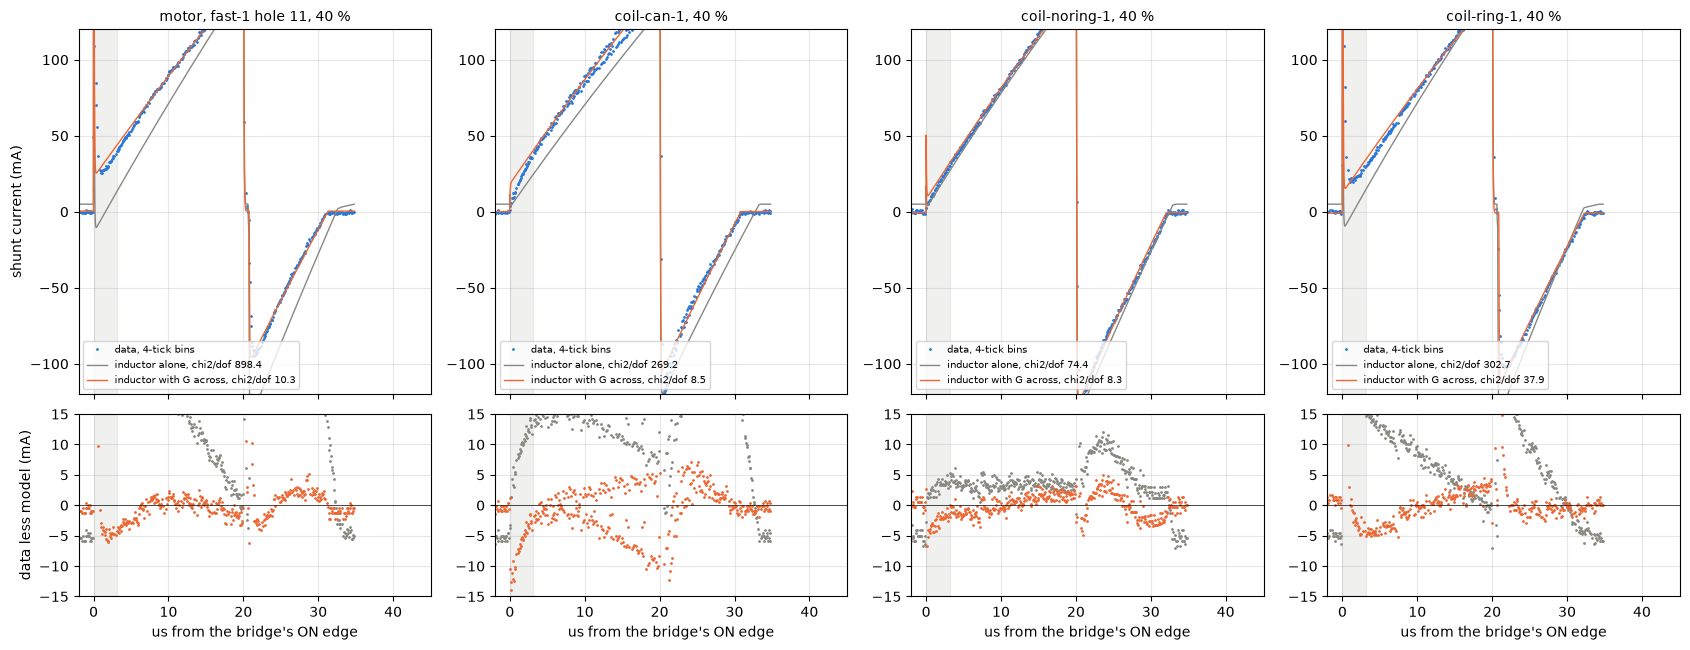

motor, fast-1 hole 11: 25 % tail -3.1/3.3 (se 0.4); 25 % window -0.2/1.6 (se 0.6); 25 % return -1.1/2.1 (se 0.6); 40 % tail -4.6/4.7 (se 0.6); 40 % window -0.5/1.7 (se 0.5); 40 % return +1.1/2.1 (se 0.6)
coil-can-1: 25 % tail -3.1/3.6 (se 0.5); 25 % window -0.3/1.6 (se 0.7); 25 % return +0.9/1.7 (se 0.7); 40 % tail -4.7/5.0 (se 0.5); 40 % window -1.0/4.0 (se 2.4); 40 % return +2.2/3.2 (se 1.0)
coil-noring-1: 25 % tail -1.6/1.8 (se 0.4); 25 % window -0.5/1.2 (se 0.5); 25 % return +1.0/1.9 (se 0.5); 40 % tail -2.3/2.6 (se 0.5); 40 % window +0.3/1.4 (se 0.5); 40 % return -0.0/2.3 (se 0.4)
coil-ring-1: 25 % tail -0.8/2.5 (se 0.7); 25 % window -0.2/1.8 (se 0.6); 25 % return +0.3/1.2 (se 0.6); 40 % tail -2.3/3.1 (se 0.4); 40 % window -0.3/2.6 (se 0.5); 40 % return -0.6/1.1 (se 0.6)


In [23]:
fig, ax = plt.subplots(2, 4, figsize=(17, 6.6), gridspec_kw={"height_ratios": [2, 1]}, sharex="col")
for k, name in enumerate(RS_FIT):
    f = FOLDS[name][1]                                                  # 40 %
    on, off = -f["half"] + ON_LAG, f["half"] + OFF_LAG
    t = (f["x"] - on) / TPU
    ok = np.isfinite(f["y"])
    ax[0, k].plot(t[ok], f["y"][ok], ".", ms=2, color=BLUE, label="data, 4-tick bins")
    for model, col in (("M0", MUTED), ("A1", ORANGE)):
        p, sd, chi2, parts = FITS[name][model]
        tc, ym, yi = parts[1]
        ax[0, k].plot((tc - on) / TPU, ym, "-", lw=1, color=col, label=f"{'inductor alone' if model == 'M0' else 'inductor with G across'}, chi2/dof {chi2:.1f}")
        ax[1, k].plot(t[ok], (f["y"] - yi)[ok], ".", ms=2, color=col)
    ax[0, k].axvspan(0, 150 / TPU, color=MUTED, alpha=0.12)
    ax[1, k].axvspan(0, 150 / TPU, color=MUTED, alpha=0.12)
    ax[0, k].set_title(f"{name}, 40 %", fontsize=10); ax[0, k].legend(fontsize=7, loc="lower left"); ax[0, k].grid(alpha=0.3)
    ax[0, k].set_ylim(-120, 120)
    ax[1, k].set_ylim(-15, 15); ax[1, k].axhline(0, color=INK, lw=0.5); ax[1, k].grid(alpha=0.3)
    ax[1, k].set_xlim(-2, (off - on) / TPU + 25); ax[1, k].set_xlabel("us from the bridge's ON edge")
ax[0, 0].set_ylabel("shunt current (mA)"); ax[1, 0].set_ylabel("data less model (mA)")
plt.tight_layout(); plt.show()

# what the fit leaves in each stretch of the fold, A1, mean and rms in mA against the bins' median standard error
for name in RS_FIT:
    p, sd, chi2, parts = FITS[name]["A1"]
    cells = []
    for j, pct in enumerate((25, 40)):
        f, yi = FOLDS[name][j], parts[j][2]
        for lab, (a, b) in regions(f).items():
            if lab in ("spike", "OFF edge", "after return"):
                continue
            sel = (f["x"] >= a) & (f["x"] < b) & np.isfinite(f["y"])
            r = f["y"][sel] - yi[sel]
            cells.append(f"{pct} % {lab} {np.mean(r):+.1f}/{np.sqrt(np.mean(r ** 2)):.1f} (se {np.nanmedian(f['se'][sel]):.1f})")
    print(f"{name}: " + "; ".join(cells))

An inductor alone misses every run, chi2/dof 898 on the motor, 269 in the can, 74 on the bare coil and 303 with the ring, and it misses the same way, the whole window low by about the offset and the return shifted. A conductance across it brings them to 10.3, 8.5, 8.3 and 37.9. On the motor $G$ is 4.62 $\pm$ 0.23 mS, 217 ohm, with $L_0$ = 0.685 $\pm$ 0.043 mH. The coil in the can reads 3.82 $\pm$ 0.11 mS, the bare coil 1.87 $\pm$ 0.07 mS and the bare coil with the ring 2.61 $\pm$ 0.15 mS. From bare to the can the coil's $L_0$ moves 4 %, 0.628 to 0.654 mH, while $G$ doubles, so the can and the magnets most likely add a loss path rather than inductance. The ring run's chi2 stays at 38, and its $G$ reads 0.7 mS over the bare coil's. With the ring across, the floating terminal after the return rings and the ring's slower charge reaches into the band, so that $G$ is not the coil's alone. The offsets above, read without a model, put the runs with and without the ring level.

Inside the band, $G$ leaves -0.5 to +0.3 mA in the mean and 1.2 to 1.7 mA rms in the window on the motor and the bare coil, against bin errors of 0.5 to 0.6 mA. The can's 40 % window leaves 4.0 mA rms, the two directions' slopes. From 0.8 to 3.1 us, outside the band, it leaves the data 1.6 to 4.7 mA under the model, more at 40 % than at 25 %, and more in the can and the motor than on the bare coil. There the current climbs onto its line instead of stepping onto it. So a part of the loss builds over a few microseconds, moderate confidence, and a pure $G$ is the fast end of a loss network rather than all of it.

An offline cross-check, not recomputed here since it needs bemf-coast's meter runs and a model of the spinning bridge's steady state that this notebook does not otherwise read, carried the motor's $G$ from these locked fast-decay folds, about 4.6 mS, unchanged into bemf-coast's meter runs. With the meter's own burden in the loop, it predicted the crest sample's excess over the meter at 20 to 100 % duty, the reading term's 4.29, 2.78, 1.58 and 0 mA/V, to within 1 to 5 mA with nothing refitted. That ties the locked rotor's offset and the spinning rotor's reading term to one conductance, moderate to high confidence, and it rests on that offline analysis until a notebook reads it.

### Where the conductance lives

The ratios between the runs' fits, each with its 1 sigma, and the offset over the window's slope, also a time and read with no model. In the figure each $G$ sits beside the offset per volt of the ON jump at 25 and 40 %. The thing to see is how much of the motor's $G$ the bare coil already has, how much arrives with the can and the magnets, and how much is left for the brushes.

bare coil over coil in the can, G: 0.49 +/- 0.02
coil in the can over the motor, G: 0.83 +/- 0.05
bare coil over the motor, G: 0.40 +/- 0.03
motor over coil in the can, G x L0: 1.27 +/- 0.12
motor over coil in the can, offset over the window's slope: 0.95 at 25 %, 1.05 at 40 %
coil in the can over the bare coil, offset at the ON edge: 2.49 at 25 %, 2.27 at 40 %


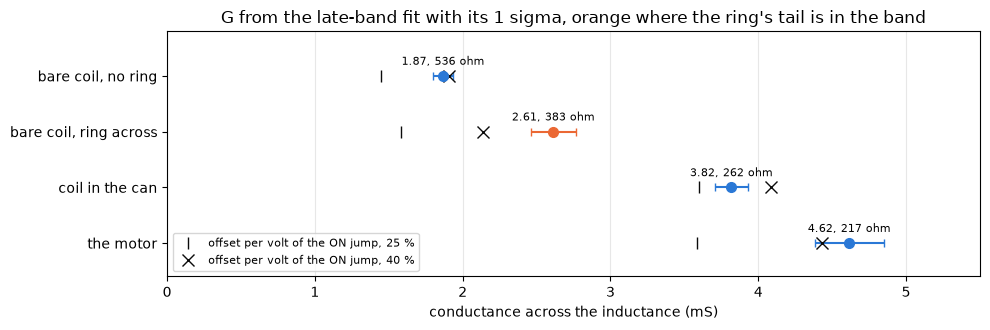

In [24]:
def a1(name):
    # G, L0 and G x L0 of one set's A1 fit, each with its 1 sigma
    p, sd, chi2, _ = FITS[name]["A1"]
    gl = p["g"] * p["l0"]
    return {"g": (p["g"], sd["g"]), "l0": (p["l0"], sd["l0"]), "gl": (gl, gl * np.hypot(sd["g"] / p["g"], sd["l0"] / p["l0"]))}


def ratio(a, b):
    # a / b with its 1 sigma, the two independent
    return a[0] / b[0], a[0] / b[0] * np.hypot(a[1] / a[0], b[1] / b[0])


FIT_A1 = {name: a1(name) for name in RS_FIT}
SHARE = {"bare coil over coil in the can, G": ratio(FIT_A1["coil-noring-1"]["g"], FIT_A1["coil-can-1"]["g"]),
         "coil in the can over the motor, G": ratio(FIT_A1["coil-can-1"]["g"], FIT_A1["motor, fast-1 hole 11"]["g"]),
         "bare coil over the motor, G": ratio(FIT_A1["coil-noring-1"]["g"], FIT_A1["motor, fast-1 hole 11"]["g"]),
         "motor over coil in the can, G x L0": ratio(FIT_A1["motor, fast-1 hole 11"]["gl"], FIT_A1["coil-can-1"]["gl"])}
SOS = {pct: STEPS.loc[("motor, fast-1 hole 11", pct), "sos"] / STEPS.loc[("coil-can-1", pct), "sos"] for pct in (25, 40)}
OFFSET_X = {pct: STEPS.loc[("coil-can-1", pct), "step"] / STEPS.loc[("coil-noring-1", pct), "step"] for pct in (25, 40)}
for k, (v, s) in SHARE.items():
    print(f"{k}: {v:.2f} +/- {s:.2f}")
print("motor over coil in the can, offset over the window's slope:", ", ".join(f"{v:.2f} at {p} %" for p, v in SOS.items()))
print("coil in the can over the bare coil, offset at the ON edge:", ", ".join(f"{v:.2f} at {p} %" for p, v in OFFSET_X.items()))

fig, ax = plt.subplots(figsize=(10, 3.4))
names = ["coil-noring-1", "coil-ring-1", "coil-can-1", "motor, fast-1 hole 11"]
for y, name in enumerate(names):
    g, s = FIT_A1[name]["g"]
    ax.errorbar(g * 1e3, y, xerr=s * 1e3, fmt="o", ms=7, capsize=3, color=ORANGE if name == "coil-ring-1" else BLUE)
    ax.annotate(f"{g * 1e3:.2f}, {1 / g:.0f} ohm", (g * 1e3, y), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
for pct, mk in ((25, "|"), (40, "x")):
    ax.plot([STEPS.loc[(n, pct), "g_on"] for n in names], range(len(names)), mk, ms=9, color=INK, label=f"offset per volt of the ON jump, {pct} %")
ax.set_yticks(range(len(names)), ["bare coil, no ring", "bare coil, ring across", "coil in the can", "the motor"]); ax.set_ylim(len(names) - 0.4, -0.8)
ax.set_xlim(0, 5.5); ax.set_xlabel("conductance across the inductance (mS)"); ax.grid(alpha=0.3, axis="x"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("G from the late-band fit with its 1 sigma, orange where the ring's tail is in the band")
plt.tight_layout(); plt.show()

The bare coil carries 0.49 $\pm$ 0.02 of the coil's $G$ in the can, and 0.40 $\pm$ 0.03 of the motor's. The coil in the can carries 0.83 $\pm$ 0.05 of the motor's $G$, and the motor's $G L_0$ is 1.27 $\pm$ 0.12 times the coil's in the can. With no model, the motor's offset over its window's slope reads 0.95 and 1.05 times the coil's in the can at 25 and 40 %. The offset per volt of the ON jump sits under the fitted $G$ at 25 % and near it at 40 %, since the 25 % window is shorter and holds less of the part that builds.

So about half of the loss sits in the rotor's laminations, the iron the coil is wound on, and the other half arrives with the can and the magnets, moderate confidence on the split. The brushes, and the two coils the motor carries beside this one, own a sixth to a quarter of it by the fits and none by the offsets, so the brush contact is at most a minor share, moderate confidence. The board is out, since ra and rab carry under a milliamp at the edge, high confidence. What this most likely is, high confidence that the iron carries it, is an iron-loss conductance across the magnetizing inductance, eddy currents in the laminations and in the can's steel or the magnets. The can and the magnets came back together, so these runs do not say which of the two carries the second half.

## The motor's electrical model

What the teardown now gives, from the terminals in. Each number is this notebook's or the named result's.

In [25]:
p_m, sd_m, _, _ = FITS["motor, fast-1 hole 11"]["A1"]
MODEL = [("leads, the motor's two in series", f"{LEADS:.2f} ohm"),
         ("brush path at the meter's milliamp", f"{BRUSH_METER:+.3f} +/- {BRUSH_METER_BR:.3f} ohm"),
         ("brush path at 0.78 A, the stall pass over copper and leads", f"{R_TERM - CU_AT_STALL:.2f} ohm, {EXCESS_V:.2f} V"),
         ("ring across the segments, a pad pair", f"{PAIR_CAP_NF:.2f} nF, {V1MA.mean():.2f} V at 1 mA, exponent {np.median(N_TOP):.1f} there"),
         ("copper between two segments", f"{R_ROTOR:.2f} ohm at {T_HAND:.1f} C"),
         ("magnetizing inductance, locked, window", f"{p_m['l0'] * 1e3:.3f} +/- {sd_m['l0'] * 1e3:.3f} mH"),
         ("iron-loss conductance across it", f"{p_m['g'] * 1e3:.2f} +/- {sd_m['g'] * 1e3:.2f} mS, {1 / p_m['g']:.0f} ohm"),
         ("back-EMF constant, bemf-coast", f"{BEMF['ke_v_s_per_rad']['value'] * 1e3:.3f} mV s/rad")]
for k, v in MODEL:
    print(f"{k}: {v}")

leads, the motor's two in series: 0.08 ohm
brush path at the meter's milliamp: +0.000 +/- 0.052 ohm
brush path at 0.78 A, the stall pass over copper and leads: 0.35 ohm, 0.28 V
ring across the segments, a pad pair: 8.12 nF, 7.82 V at 1 mA, exponent 4.0 there
copper between two segments: 4.01 ohm at 24.9 C
magnetizing inductance, locked, window: 0.685 +/- 0.043 mH
iron-loss conductance across it: 4.62 +/- 0.23 mS, 217 ohm
back-EMF constant, bemf-coast: 1.168 mV s/rad


1. The leads, 0.08 ohm for the two in series.
2. The brushes, a contact whose drop depends on the current and the motion. At the meter's milliamp it reads zero within $\pm$0.05 ohm. At the stall pass's 0.78 A the terminal reads 0.35 ohm over the copper and the leads, a drop of at most 0.28 V, with the copper's temperature as the open term. How the contact behaves while the rotor turns is not read here.
3. The varistor ring across the commutator's segments, behind the brushes, so it sits across the armature as the brushes see it. A pad pair holds 8.1 nF and passes 1 mA at 7.8 V with an exponent of 4 there, 0.21 mA at 5.0 V and 0.80 mA at 7.4 V. At an edge the brushes see 7.7 to 10.8 nF of it.
4. The armature between the two segments under the brushes, 4.01 ohm of copper at 24.9 C, in series with the magnetizing inductance, 0.685 mH on the locked rotor over a window, with the iron-loss conductance, 4.6 mS, across that inductance, a part of which builds over a few microseconds. The window's $L$ is the short time scale's, and inductance reads $L$ rising to 0.79 to 0.86 mH over half a millisecond on the assembled motor.
5. The back-EMF in series with the armature, $K_e$ = 1.168 mV s/rad from bemf-coast.

## The cool run, cool-winding-1

### How the run sat

The rotor was held by its shaft in a helping hand's clip with 1 to 2 mm of air between the clip and the iron, leads soldered to commutator tabs 1 (purple) and 2 (white), with a third on tab 3 (black) left unused. The thermocouple tip was taped under kapton (a heat-resistant polyimide tape) in the gap between coil 1-2 and its neighbor. The purple and white leads were joined to the board side with clips. The photo shows the rotor with its leads, before the run.

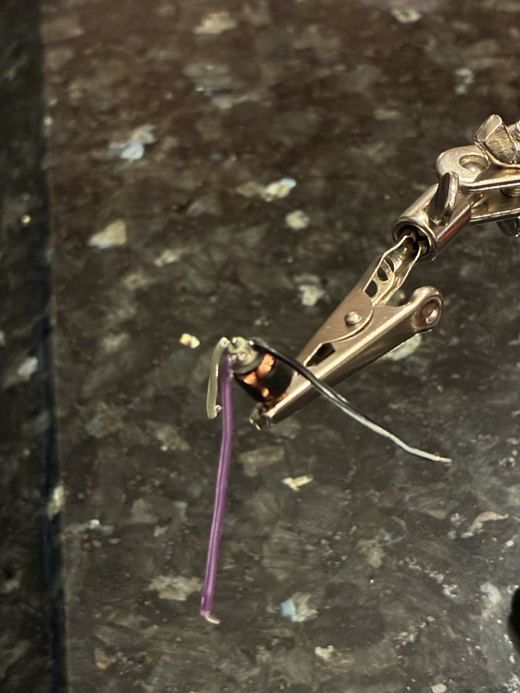

In [26]:
photos(["20-rotor-leads-soldered.jpg"], cols=1, width=520)

The drive runs from tab 1 to tab 2. That puts coil 1-2 straight across the drive and coils 2-3 and 3-1 in series beside it. Coil 1-2 carries 2/3 of the current and the other two 1/3 each, so coil 1-2 takes 2/3 of the heat and the other two 1/6 each. The resistance the board reads is the pair, and how much it moves for a change in each coil is

$$\frac{\partial R_\mathrm{pair}}{\partial R_{12}} = \left(\frac{R_{23} + R_{31}}{R_{12} + R_{23} + R_{31}}\right)^2 = \frac{4}{9}, \qquad \frac{\partial R_\mathrm{pair}}{\partial R_{23}} = \frac{\partial R_\mathrm{pair}}{\partial R_{31}} = \frac{1}{9}$$

for equal coils. Over $R_\mathrm{pair} = \frac{2}{3} R_c$ that weights the three coils 4 to 1 to 1. So the rise the board reads is

$$\Delta T = \frac{4 \, \Delta T_{12} + \Delta T_{23} + \Delta T_{31}}{6}$$

a weighted copper temperature, leaning on the coil that takes most of the heat.

The method reads the resistance from raw counts in each streamed drive window, as `capture.py` does. The window's second half, so the current's rise is out of it. The tap difference's median over the shunt's median above the torque-off zero of the same sweep, both in raw counts, so a ratio of two of them is a ratio of resistances with every scale cancelled. The copper at room, $R_0$, is the median of the ten room probes, and the copper's rise over room is

$$\Delta T = \left(\frac{R}{R_0} - 1\right) (234.5 + T_0)$$

with $T_0$ the room the probes sat at, the thermocouple's reading before the heat through the stage 0 correction. That is copper's coefficient at the reference temperature, $1/(234.5 + T_0)$, 0.393 % per C being its value at 20 C. The coefficient is not measured here. Earlier work soaked a whole MG90 of the same model, a different unit wound from the same wire in the same process, in a dryer box until it sat at one temperature, with a K thermocouple on the can, and read the DC resistance across its terminals at rest on the meter at each plateau, 4.52 ohm at 28.6 C and 5.09 ohm at 61.5 C. The fitted slope there is 0.396 +/- 0.010 % per C, 101 % of copper's 0.393, with a fixed term of -0.04 +/- 0.11 ohm, so the loop is copper with nothing else in series at rest and the textbook coefficient holds to about 2.5 %. A similar coefficient is expected for mg90-b, and the run here checks that the bare copper through the board reads its own temperature over it.

### The meter windows before the board

The room, a lead zero, the leads at their board ends, and the room again. The `tabs ohm` window was skipped on purpose, the probes left apart, so it reads OL throughout, and the rotor's own reading is the hand-read tab pair 1-2.

In [27]:
CW = {w: meter(COOL, w) for w in ("room-c1", "zero", "tabs-ohm", "leads-ohm", "room-c2")}
COOL_ZERO = float(CW["zero"]["value"].median())
LEADS_BOARD_END = float(CW["leads-ohm"]["value"].median()) - COOL_ZERO   # the rotor and both leads, at the leads' board ends
for w, d in CW.items():
    if w.startswith("room"):
        print(f"{w}: {d['value'].min():.1f} to {d['value'].max():.1f} C read, median {np.median(t_corr(d['value'])):.2f} C corrected, {len(d)} packets")
    else:
        print(f"{w}: {d['ol'].sum()} of {len(d)} OL" + ("" if d["ol"].all() else f", {d['value'].min():.2f} to {d['value'].max():.2f}, median {d['value'].median():.2f} ohm"))
print(f"the rotor and leads at the board end {LEADS_BOARD_END:.2f} ohm with the zero off, against the hand-read pair 1-2 alone {PAIRS[0]:.2f} ohm, "
      f"{(cmarks['leads ohm'] - tmarks.set_index('mark')['t_host']['tabs 1-2 ohm']) / 60:.0f} min later")

room-c1: 28.6 to 28.6 C read, median 28.73 C corrected, 120 packets
zero: 0 of 40 OL, 0.05 to 0.06, median 0.06 ohm
tabs-ohm: 80 of 80 OL
leads-ohm: 0 of 80 OL, 4.02 to 4.07, median 4.03 ohm
room-c2: 24.8 to 24.9 C read, median 24.90 C corrected, 120 packets
the rotor and leads at the board end 3.97 ohm with the zero off, against the hand-read pair 1-2 alone 4.01 ohm, 58 min later


The first room window, `room-c1`, reads 28.6 C flat for its whole minute, while `room-c2` ten minutes later and the board phase read 24.7 to 24.9 C. Nothing in the room changed that much in ten minutes, and the rotor had not been heated. The meter settling after it was switched to temperature is a candidate, untested, and the run takes the later readings as the room.

The rotor and its leads read 3.97 ohm at the leads' board ends, with the zero off, under the rotor's own tab pair 1-2 at 4.01 ohm read by hand about an hour earlier. The leads add resistance and do not take it away, so one of the two readings moved, by its temperature or its contact, and the leads' share of the cool run's resistance is not resolved here. The motor's original leads were 0.08 ohm in series, and these are of the same kind, so the leads most likely own 1 to 2 % of what the board reads. The leads barely warm, so they dilute the rise the board reads by about their share.

### The heat and the probes

The board's three sweeps, each window's resistance over the room's as a rise in C. The room probes come first, 5 ms at 100 % once a second for ten seconds. The heat is 5 s at 100 % on the 3.3 V rail, a 100 ms streamed window each second with the drive held between them, and it runs on with no pause into probes 0.2 s apart for six seconds. The cool sweep starts about a second later, probes once a second for a minute, then every 5 s to about eleven minutes. The clock is seconds from the start of the heat.

In [28]:
def resistances(folder):
    # one row per streamed drive window: host times, R as raw counts (taps over shunt), the second half's medians, full duty, rows
    df, meta = tel.load(folder, BOARD)                                  # checks the sense block against the board entry
    seg = pd.read_csv(folder / "segments.csv").set_index("seg")
    zero = float(df[df["seg"] == 0]["current_raw"].median())             # the torque-off zero of this sweep
    out = []
    for s, g in df[df["seg"] > 0].groupby("seg"):
        if seg.loc[s, "cmd_duty_q15"] <= 0:
            continue
        tail = g.iloc[len(g) // 2:]                                     # the window's second half, the rise out of it
        v = float((tail["vmotor_a"] - tail["vmotor_b"]).median())
        i = float(tail["current_raw"].median()) - zero
        out.append({"seg": s, "t_start": seg.loc[s, "t_start"], "t_end": seg.loc[s, "t_end"], "r": v / i, "v_counts": v, "i_counts": i,
                    "full": bool((tail["duty_counts"] >= meta["pwm_period_ticks"]).all()), "rows": len(g),
                    "missing": int(tel.gaps(df).sum())})
    return pd.DataFrame(out), meta, df, zero


ROOM_W, room_meta, _, _ = resistances(COOL / "board" / "room")
HEAT_W, heat_meta, heat_df, HEAT_ZERO = resistances(COOL / "board" / "heat-0")
COOL_W, cool_meta, _, _ = resistances(COOL / "board" / "cool")
R0 = float(ROOM_W["r"].median())                                        # the copper at room, raw counts ratio
T0 = HEAT_W["t_start"].iloc[0]                                          # the clock's zero, the heat's first window
T_ROOM0 = float(np.median(t_corr(temp[temp["t_host"] < T0]["value"])))   # the room the probes sat at, the thermocouple before the heat, corrected
K_ROOM = 234.5 + T_ROOM0                                                # 1 / copper's coefficient referred to that room, C
for W in (ROOM_W, HEAT_W, COOL_W):
    W["t"] = W["t_start"] - T0
    W["rise"] = (W["r"] / R0 - 1) * K_ROOM                              # C over room, by the copper's resistance
HEAT_W["kind"] = np.where(HEAT_W["rows"] > 1000, "heat", "tail")         # the 100 ms windows against the 5 ms probes
HW, TAIL = HEAT_W[HEAT_W["kind"] == "heat"], HEAT_W[HEAT_W["kind"] == "tail"]
DRIVE_END = TAIL["t"].iloc[0]                                           # the held drive ends where the first tail probe starts
volts = (HW["v_counts"] - C_OFF) / K_CPV                                 # the terminal-chain line inverted
amps = (HW["i_counts"] - B_OFF) / G_CPA                                  # the current-scale line inverted
print(f"room {T_ROOM0:.2f} C by the thermocouple, so the coefficient there is 1 / {K_ROOM:.2f} C = {100 / K_ROOM:.4f} % per C")
print(f"room probes: R0 {R0:.4f} counts ratio, the ten within {(ROOM_W['r'].min() / R0 - 1) * 100:+.2f} to {(ROOM_W['r'].max() / R0 - 1) * 100:+.2f} %, "
      f"{ROOM_W['rise'].min():+.2f} to {ROOM_W['rise'].max():+.2f} C")
print("heat windows, rise over room (C):", ", ".join(f"{r:.1f}" for r in HW["rise"]), "| full duty in every window:", bool(HEAT_W["full"].all()))
print("heat windows, current (A) through the lines:", ", ".join(f"{a:.3f}" for a in amps), "| terminal (V):", ", ".join(f"{v:.3f}" for v in volts))
print(f"the drive held to {DRIVE_END:.2f} s; the first tail probe {TAIL['rise'].iloc[0]:+.1f} C, the last at {TAIL['t'].iloc[-1]:.1f} s "
      f"{TAIL['rise'].iloc[-1]:+.1f} C; the cool sweep from {COOL_W['t'].iloc[0]:.1f} s to {COOL_W['t'].iloc[-1]:.0f} s, {len(COOL_W)} probes")
print("missing rows:", int(ROOM_W["missing"].iloc[0]), int(HEAT_W["missing"].iloc[0]), int(COOL_W["missing"].iloc[0]),
      "| rows dropped in meta:", room_meta["rows_dropped"], heat_meta["rows_dropped"], cool_meta["rows_dropped"])

room 24.90 C by the thermocouple, so the coefficient there is 1 / 259.40 C = 0.3855 % per C
room probes: R0 0.8905 counts ratio, the ten within -0.17 to +0.23 %, -0.44 to +0.58 C
heat windows, rise over room (C): 1.9, 20.0, 29.7, 36.3, 41.7 | full duty in every window: True
heat windows, current (A) through the lines: 0.774, 0.727, 0.704, 0.689, 0.677 | terminal (V): 3.183, 3.195, 3.203, 3.207, 3.211
the drive held to 5.73 s; the first tail probe +46.0 C, the last at 12.3 s +21.0 C; the cool sweep from 13.3 s to 700 s, 168 probes
missing rows: 0 0 0 | rows dropped in meta: 0 0 0


The ten room probes agree within -0.17 to +0.23 %, about $\pm$0.5 C. One count of tap difference is about 0.13 % of the reading here, and the probes scatter over a count or two, so the room is known to about half a degree.

The heat held 100 % in every window, and the copper read +41.7 C over room in the last heating window, past the run's 40 C target, so the script skipped the second heat. The current falls as the copper warms, from 0.77 A in the first window to 0.68 A in the last, while the terminal volts rise by a few counts, which is the copper's own resistance pushing back against a rail that barely moves. The drive held on to 5.73 s, and the first tail probe read +46.0 C. Six seconds later the copper read +21.0 C. No row is missing from any sweep.

### The fast tail and the slow tail

Left, the first 20 s, the heating windows, the tail probes and the first cool probes, with one exponential and an offset fitted to the tail probes. Right, the whole run on the same clock, the cool sweep's probes, the thermocouple through the stage 0 correction as a rise over its own room reading, and one exponential and an offset fitted to the cool probes after the step described below. The thing to see on the left is how fast the copper gives up its excess, and on the right the step and how the copper and the thermocouple come together.

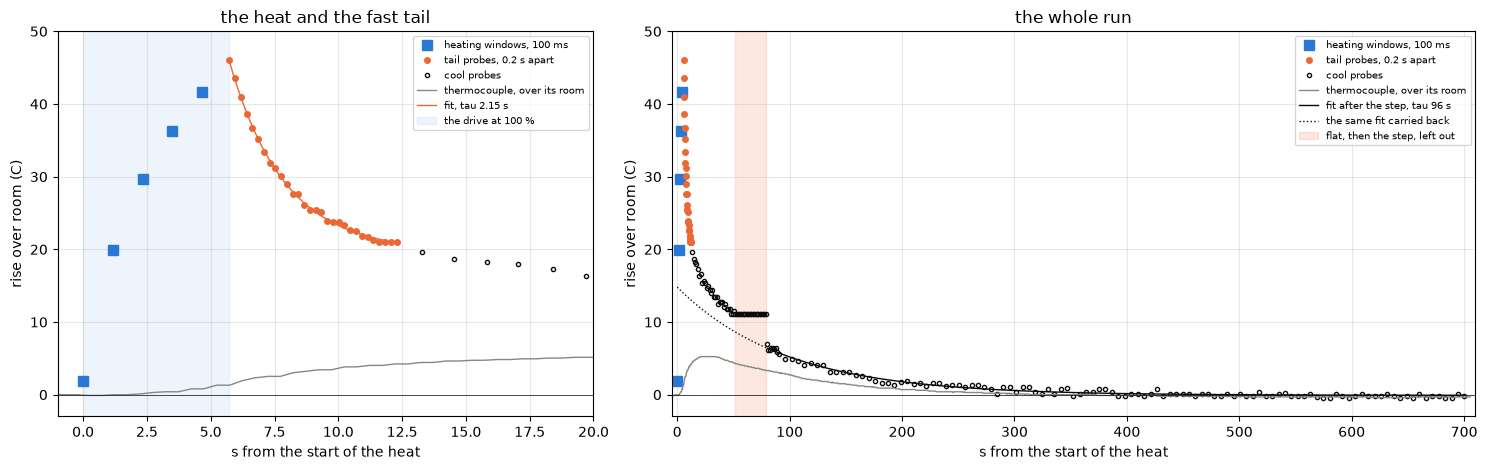

fast tail: tau 2.15 +/- 0.05 s, amplitude 26.2 C, offset 19.7 C, residual rms 0.28 C
the flat: 22 probes from 51.8 to 78.5 s all at +11.14 C, then +6.93 C at 79.8 s, a drop of 4.2 C (1.58 % of R) in 1.3 s; the next five probes +6.1 to +6.9 C
slow tail after the step: tau 96.5 +/- 3.4 s, amplitude 14.9 C at t = 0, offset -0.09 +/- 0.04 C, residual rms 0.29 C over 116 probes
the last two minutes: -0.47 to +0.15 C, median -0.15 C
the cool probes from 25 s to the flat sit +2.2 to +3.9 C over the post-step fit carried back
thermocouple: room 24.90 C corrected, peak +5.2 C at 21 s; it reads nothing at the step, [3.2, 3.4] C around it


In [29]:
def expo(t, a, tau, c):
    # one exponential and an offset
    return a * np.exp(-t / tau) + c


FAST_P, FAST_COV = curve_fit(expo, TAIL["t"] - DRIVE_END, TAIL["rise"], p0=(25, 2, 20))   # from the drive's end
FAST_SE = np.sqrt(np.diag(FAST_COV))
FAST_RES = TAIL["rise"] - expo(TAIL["t"] - DRIVE_END, *FAST_P)
cw = COOL_W.reset_index(drop=True)
k = int(np.argmin(np.diff(cw["rise"].to_numpy())))                      # the largest single drop between two cool probes
STEP_T = (cw.loc[k, "t"], cw.loc[k + 1, "t"])
flat = k
while flat > 0 and cw.loc[flat - 1, "rise"] == cw.loc[k, "rise"]:
    flat -= 1                                                           # back to the first probe of the flat run before the drop
FLAT_T = (cw.loc[flat, "t"], cw.loc[k, "t"])
STEP_C = cw.loc[k, "rise"] - cw.loc[k + 1, "rise"]
STEP_PCT = (cw.loc[k, "r"] / cw.loc[k + 1, "r"] - 1) * 100
LATER = cw.loc[k + 1:k + 6, "rise"]                                     # the next few probes after the drop
POST = cw.loc[k + 1:]                                                   # the slow fit's stretch, after the step
SLOW_P, SLOW_COV = curve_fit(expo, POST["t"], POST["rise"], p0=(10, 100, 0))
SLOW_SE = np.sqrt(np.diag(SLOW_COV))
SLOW_RES = POST["rise"] - expo(POST["t"], *SLOW_P)
END = cw[cw["t"] >= cw["t"].iloc[-1] - 120]                             # the last two minutes
PRE = cw[(cw["t"] >= 25) & (cw["t"] < FLAT_T[0])]                       # the cool probes before the flat, past the fast tail
PRE_EXCESS = PRE["rise"] - expo(PRE["t"], *SLOW_P)                      # how far over the post-step fit carried back they sit
TT = temp.assign(t=temp["t_host"] - T0, t_c=t_corr(temp["value"]))
TC_ROOM = T_ROOM0                                                       # the thermocouple at room, before the heat
TT["rise"] = TT["t_c"] - TC_ROOM

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
for a in ax:
    a.plot(HW["t"], HW["rise"], "s", ms=7, color=BLUE, label="heating windows, 100 ms")
    a.plot(TAIL["t"], TAIL["rise"], "o", ms=4, color=ORANGE, label="tail probes, 0.2 s apart")
    a.plot(cw["t"], cw["rise"], "o", ms=3, color=INK, mfc="none", label="cool probes")
    a.plot(TT["t"], TT["rise"], "-", lw=1, color=MUTED, label="thermocouple, over its room")
    a.axhline(0, color=INK, lw=0.5)
tt = np.linspace(0, 6.6, 100)
ax[0].plot(DRIVE_END + tt, expo(tt, *FAST_P), color=ORANGE, lw=1, label=f"fit, tau {FAST_P[1]:.2f} s")
ax[0].axvspan(0, DRIVE_END, color=BLUE, alpha=0.08, label="the drive at 100 %")
ax[0].set_xlim(-1, 20); ax[0].set_ylim(-3, 50); ax[0].set_title("the heat and the fast tail")
ts = np.linspace(0, cw["t"].iloc[-1], 400)
ax[1].plot(ts[ts >= STEP_T[1]], expo(ts[ts >= STEP_T[1]], *SLOW_P), color=INK, lw=1, label=f"fit after the step, tau {SLOW_P[1]:.0f} s")
ax[1].plot(ts[ts < STEP_T[1]], expo(ts[ts < STEP_T[1]], *SLOW_P), color=INK, lw=1, ls=":", label="the same fit carried back")
ax[1].axvspan(*FLAT_T, color=ORANGE, alpha=0.15, label="flat, then the step, left out")
ax[1].set_xlim(-5, cw["t"].iloc[-1] + 10); ax[1].set_ylim(-3, 50); ax[1].set_title("the whole run")
for a in ax:
    a.set_xlabel("s from the start of the heat"); a.set_ylabel("rise over room (C)"); a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"fast tail: tau {FAST_P[1]:.2f} +/- {FAST_SE[1]:.2f} s, amplitude {FAST_P[0]:.1f} C, offset {FAST_P[2]:.1f} C, residual rms {np.sqrt(np.mean(FAST_RES ** 2)):.2f} C")
print(f"the flat: {k - flat + 1} probes from {FLAT_T[0]:.1f} to {FLAT_T[1]:.1f} s all at {cw.loc[k, 'rise']:+.2f} C, then {cw.loc[k + 1, 'rise']:+.2f} C at "
      f"{STEP_T[1]:.1f} s, a drop of {STEP_C:.1f} C ({STEP_PCT:.2f} % of R) in {STEP_T[1] - STEP_T[0]:.1f} s; the next five probes {LATER.min():+.1f} to {LATER.max():+.1f} C")
print(f"slow tail after the step: tau {SLOW_P[1]:.1f} +/- {SLOW_SE[1]:.1f} s, amplitude {SLOW_P[0]:.1f} C at t = 0, offset {SLOW_P[2]:+.2f} +/- {SLOW_SE[2]:.2f} C, "
      f"residual rms {np.sqrt(np.mean(SLOW_RES ** 2)):.2f} C over {len(POST)} probes")
print(f"the last two minutes: {END['rise'].min():+.2f} to {END['rise'].max():+.2f} C, median {END['rise'].median():+.2f} C")
print(f"the cool probes from 25 s to the flat sit {PRE_EXCESS.min():+.1f} to {PRE_EXCESS.max():+.1f} C over the post-step fit carried back")
print(f"thermocouple: room {TC_ROOM:.2f} C corrected, peak {TT['rise'].max():+.1f} C at {TT.loc[TT['rise'].idxmax(), 't']:.0f} s; "
      f"it reads nothing at the step, {TT[(TT['t'] > STEP_T[0] - 3) & (TT['t'] < STEP_T[1] + 3)]['rise'].agg(['min', 'max']).round(1).tolist()} C around it")

The tail probes fall from +46.0 C to +21.0 C in six seconds, and one exponential with an offset fits them with a time constant of 2.15 $\pm$ 0.05 s. The excess falling that fast is the copper giving its heat to the iron it is wound on, which is many times heavier and sits right under it. There are no brushes in this path, so the node near 2 s that rest-resistance saw through the brushes, 1.90 s with a bracket of 1.75 to 2.06, is most likely the copper's own exchange with the iron and not the brush contact, moderate to high confidence. The two are close, and the 10 % between them is inside what one rotor in open air against one motor in its can can differ by.

Then a step. From about 48 s the reading stops falling, and from 51.8 s to 78.5 s it sits at one value, +11.14 C, for 22 probes in a row, where the copper was still cooling by about a tenth of a degree a second before it. In the next 1.3 s the reading drops 4.2 C, 1.6 % of the resistance, and the five probes after that read +6.1 to +6.9 C, 4.2 to 5.0 C under the flat. The thermocouple shows nothing at that moment. Copper in still air does not drop 4 C in a second, and a copper that stops cooling for half a minute and then catches up all at once is not a thermal shape. The leads were joined to the board side with clips, and a clip's contact settling is the likely cause, high confidence that the step is electrical. The flat and the step are left out of every fit.

After the step the copper cools smoothly and comes back to room. Over the last two minutes it reads -0.47 to +0.15 C against the room probes, -0.15 C in the median, inside the room's own scatter. So the readings after the step agree with the room probes, and they are most likely the true ones. One exponential with an offset fits them with a time constant of 96 $\pm$ 3 s, about a minute and a half, with the offset at -0.09 C. That is the whole rotor, copper and iron together, giving its heat to the air and through the shaft to the clip.

One thing in the figure does not fit that picture, and the data do not settle it. The fit after the step, carried back, sits under every cool probe before the flat, by 2.2 to 3.9 C over 25 to 52 s, more the earlier. If the clip's contact added a fixed amount from some moment before the flat until the step, the probes before the flat would carry that amount, and here they carry less than the 4.2 to 5.0 C step and more the earlier they are. A third time scale between the 2 s exchange and the 96 s tail, such as the iron giving heat to the shaft and the clip, would bend the cooling the same way. Nothing here separates the two, and the open questions carry the run that does. Until then, the readings between the tail's end and the step are uncertain by up to the step's size, and the peak, the heat rise and the fast tail ahead of them may carry part of it too.

### How fast the copper warms

The first heating window row by row, the resistance in raw counts per row over the room's as a rise in C, against time from the drive's first row. A line through it from 10 ms gives the first rate of warming. The heat put in over the same window is the terminal volts times the current through the stage 1 lines. An effective heat capacity is then

$$C_\mathrm{eff} = \frac{P}{dT/dt}$$

an upper bound on what the weighted reading sees, since some heat already leaves the copper for the iron in the first 100 ms and the reading then rises slower than the copper alone would. The rail is at 3.3 V, the level stage 1 did not grade, so the power is also shown with stage 1's 3.3 V deviations divided out, as a guide.

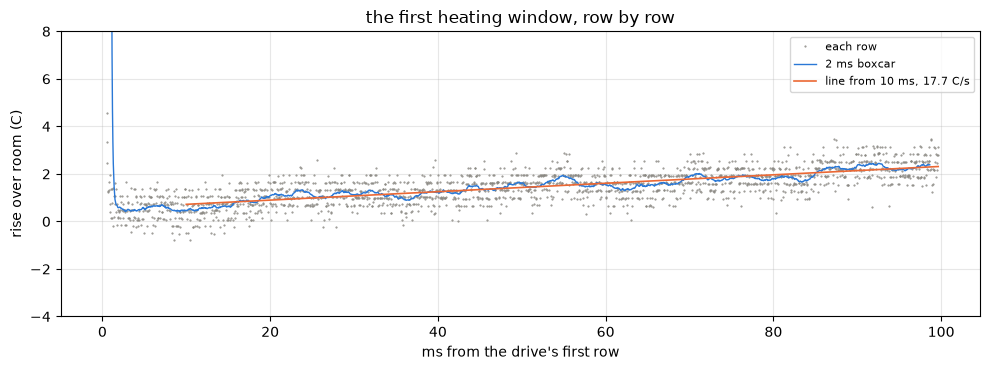

window means, C over room: 5-10 ms +0.57, 10-20 ms +0.71, 20-40 ms +1.13, 40-60 ms +1.50, 60-80 ms +1.67, 80-100 ms +2.17
first rate 17.7 C/s; chord from the first window to the second 15.3 C/s
power in the first window 3.183 V x 0.774 A = 2.46 W through the lines, 2.02 W with stage 1's 3.3 V deviations out
C_eff 0.139 J/C through the lines, 0.114 J/C as a guide; as copper 0.36 and 0.30 g; rest-resistance's warming bound 0.137 J/C


In [30]:
w1 = heat_df[heat_df["seg"] == HW["seg"].iloc[0]]
on = int(np.flatnonzero(w1["duty_counts"].to_numpy() != 0)[0])          # the drive's first row
w1 = w1.iloc[on:]
t1 = np.arange(len(w1)) / BOARD.tick_hz                                 # s from the drive's first row
r1 = (w1["vmotor_a"] - w1["vmotor_b"]).to_numpy(float) / (w1["current_raw"].to_numpy(float) - HEAT_ZERO)
rise1 = (r1 / R0 - 1) * K_ROOM
fit = t1 >= 0.010                                                       # past the current's rise and the first milliseconds
LINE1 = np.polyfit(t1[fit], rise1[fit], 1)                              # C per s and C at the start
P_W = float(volts.iloc[0] * amps.iloc[0])                               # W through the lines, the first window
P_W_GUIDE = P_W / ((1 + TERM_3V3 / 100) * (1 + CUR_3V3 / 100))          # stage 1's 3.3 V deviations divided out
C_EFF = P_W / LINE1[0]
C_EFF_GUIDE = P_W_GUIDE / LINE1[0]
CHORD = (HW["rise"].iloc[1] - HW["rise"].iloc[0]) / (HW["t"].iloc[1] - HW["t"].iloc[0])   # first window to second, the heat leaking meanwhile
fig, ax = plt.subplots(figsize=(10, 3.8))
box = np.convolve(rise1, np.ones(40) / 40, mode="same")                 # 2 ms boxcar
ax.plot(t1 * 1e3, rise1, ".", ms=1, color=MUTED, label="each row")
ax.plot(t1[20:-20] * 1e3, box[20:-20], color=BLUE, lw=1, label="2 ms boxcar")
ax.plot(t1[fit] * 1e3, np.polyval(LINE1, t1[fit]), color=ORANGE, lw=1.2, label=f"line from 10 ms, {LINE1[0]:.1f} C/s")
ax.set_ylim(-4, 8); ax.set_xlabel("ms from the drive's first row"); ax.set_ylabel("rise over room (C)")
ax.set_title("the first heating window, row by row"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
early = [(a, b, float(rise1[(t1 >= a) & (t1 < b)].mean())) for a, b in ((0.005, 0.010), (0.010, 0.020), (0.020, 0.040), (0.040, 0.060), (0.060, 0.080), (0.080, 0.100))]
print("window means, C over room:", ", ".join(f"{a * 1e3:.0f}-{b * 1e3:.0f} ms {m:+.2f}" for a, b, m in early))
print(f"first rate {LINE1[0]:.1f} C/s; chord from the first window to the second {CHORD:.1f} C/s")
print(f"power in the first window {volts.iloc[0]:.3f} V x {amps.iloc[0]:.3f} A = {P_W:.2f} W through the lines, {P_W_GUIDE:.2f} W with stage 1's 3.3 V deviations out")
print(f"C_eff {C_EFF:.3f} J/C through the lines, {C_EFF_GUIDE:.3f} J/C as a guide; as copper {C_EFF / C_CU:.2f} and {C_EFF_GUIDE / C_CU:.2f} g; "
      f"rest-resistance's warming bound {RR['copper_heat_capacity_max_j_per_c']['value']:.3f} J/C")

From 10 ms on, the first window rises along a line at 17.7 C per second, and the chord from the first window to the second reads 15.3 C per second, lower as the heat leaks to the iron in between. Through the stage 1 lines the first window puts 2.46 W into the path, so $C_\mathrm{eff}$ is about 0.14 J per C, the heat capacity of about 0.36 g of copper. With stage 1's deviations at the 3.3 V level divided out the power is 2.02 W and $C_\mathrm{eff}$ 0.11 J per C. Rest-resistance bounded the copper's heat capacity from its laps' warming at 0.137 J per C if every ohm were copper, which is about the same number from the terminals.

This is a rough number with three caveats. The power includes the leads and the clips, 1 to 2 % of it. The 3.3 V level is not graded, and the guide's factor came from a resistor at a lower current. And $C_\mathrm{eff}$ belongs to the weighted reading. If the three coils kept their heat apart over the first 100 ms, the weighted reading would rise 1.5 times faster than the mean of the three, since coil 1-2 takes 2/3 of the heat and 2/3 of the weight, so the three coils together could hold up to 1.5 times $C_\mathrm{eff}$. Heat shared between the coils through the iron in that time brings the factor toward one. The teardown did not weigh the copper apart from the iron, so none of this is checked against a copper mass.

The first window also shows no fall at its start. Between 5 and 10 ms the reading is +0.57 C, and it rises steadily from there, while the first 30 to 50 ms of rest-resistance's laps through the brushes fell by about a percent, about 2 C on this scale. The bare rotor at 0.77 A shows no fall of that size, low to moderate confidence, since the room probes the rise is read against are 5 ms windows read at 2.5 to 5 ms and so share the first milliseconds with it.

### The thermocouple against the copper

The thermocouple's rise against the copper's after the step, interpolated onto the cool probes' times. The thing to see is how far behind the surface sensor runs.

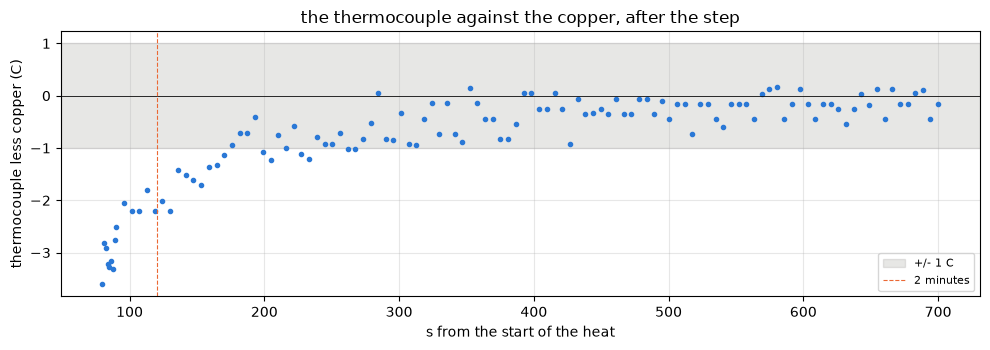

thermocouple peak +5.2 C at 21 s, 15 s after the drive, while the copper read +46.0 C at the drive's end
from 2 minutes on the thermocouple sits -2.2 to +0.2 C from the copper; at 80 s it sits -3.6 C
stage 0: the thermocouple in air settles within 1 C in 34 s


In [31]:
pts = POST[POST["t"] >= 0].copy()
pts["tc"] = np.interp(pts["t"], TT["t"], TT["rise"])                    # the thermocouple at each probe's time
pts["gap"] = pts["tc"] - pts["rise"]
after2 = pts[pts["t"] >= 120]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(pts["t"], pts["gap"], "o", ms=3, color=BLUE)
ax.axhline(0, color=INK, lw=0.6); ax.axhspan(-1, 1, color=MUTED, alpha=0.2, label="+/- 1 C")
ax.axvline(120, color=ORANGE, lw=0.8, ls="--", label="2 minutes")
ax.set_xlabel("s from the start of the heat"); ax.set_ylabel("thermocouple less copper (C)")
ax.set_title("the thermocouple against the copper, after the step"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
peak = TT.loc[TT["rise"].idxmax()]
first_tail = TAIL["rise"].iloc[0]
print(f"thermocouple peak {peak['rise']:+.1f} C at {peak['t']:.0f} s, {peak['t'] - DRIVE_END:.0f} s after the drive, while the copper read {first_tail:+.1f} C at the drive's end")
print(f"from 2 minutes on the thermocouple sits {after2['gap'].min():+.1f} to {after2['gap'].max():+.1f} C from the copper; "
      f"at {pts['t'].iloc[0]:.0f} s it sits {pts['gap'].iloc[0]:+.1f} C")
print(f"stage 0: the thermocouple in air settles within 1 C in {TCPL['settle_air_1c_s']['value']:.0f} s")

The thermocouple peaks at only +5.2 C over its room through the stage 0 correction, about 15 s after the drive ends, while the copper read +46 C at the drive's end. From two minutes on it sits 0 to 2.2 C under the copper, and the gap closes as both come back to room. The tip sat in a gap between two coils under kapton, against enamel and air, and its coupling to the copper was poor. Stage 0 found the bare tip in air takes about half a minute to settle within a degree. So a surface sensor near the winding does not follow the copper on the time scale of seconds, and the copper's resistance does, so the copper's own resistance is the route that follows it.

### The cool core run, the soak and the unwind

The cool core run, with the tip on the iron of a pole face, was not run, by choice. It was there to read the iron beside the copper, to see the copper run seconds ahead of the iron. The winding run shows the tip too slow by tens of seconds to resolve a 2 s exchange, so on the iron it would have read a curve the size of its own lag. A thermometer of a few hundred milliseconds, such as a fine bare-bead thermocouple glued to the iron, would read it.

The plateau soak, which would have measured the copper coefficient on this rotor, was dropped too. The coefficient comes from earlier work on a motor of the same model, and the board heats bare copper well enough to check it at one point. A soak would have tightened the 2.5 % the coefficient is known to here.

The coils were not unwound and weighed. That would have given the copper's mass and so its heat capacity, which would have checked $C_\mathrm{eff}$ and rest-resistance's warming bound against the copper itself, and counted the turns of each coil, which inductance asked for.

## Results

The teardown's numbers, from the parts, the end cap, the winding, the disc and the cool run, each with its range or bracket.

### The results file

Every mass and dimension with the range of its readings, the counts, the inertia bound, the end cap's readings, the leads and the rotor's pairs and coils, the brush path at the meter's current and the stall pass's excess, the ring's sectors on and off the rotor and what the terminals see, its predicted spike charge beside each earlier spike, its swept current, V at 1 mA and exponent, the drive-only current against the ring's current, the fast-decay edges, the offset at the ON edge per run, the edge charges, the conductance fits and their shares, and the cool run's rise, time constants, step and heat capacity.

In [32]:
q = results.quantity


def rng(x, unit, value=None):
    # a value, the mean unless given, with the range of x as the bounds
    x = np.asarray(x, float)
    return q(x.mean() if value is None else value, x.min(), x.max(), unit)


spike_vs_ring = {f"{r['source']}, {r['decay']} decay, {r['point']}": {
    "measured_nc": q(r["nc"], unit="nC"), "volts": q(r["volts"], unit="V"),
    "ring_nc": q((r["ring_lo_nc"] + r["ring_hi_nc"]) / 2, r["ring_lo_nc"], r["ring_hi_nc"], "nC"),
    "inside": q(float(r["in_band"]), unit="1 if inside the ring's band")} for _, r in SP.iterrows()}
NOTES = ("Teardown of mg90-b after every other stage 2 experiment. Masses on a 1 mg scale, dimensions by micrometer (can) and calipers (rotor), "
         "counts off the parts and the photos, all from telemetry/mg90-b/teardown/hand.csv; each quantity's value is the mean of its readings and "
         "the bounds their range. j_cylinder_upper_kg_m2 is the rotor (1.123 g, no pinion) as a uniform cylinder of the stack's 7.03 mm, an upper bound "
         "since the shaft, commutator and disc sit at a smaller radius; the pinion adds at most pinion_j_pct if it sat at the stack's radius. "
         "end_cap_* are terminals-1, the end cap on the empty can: ohms across the tabs and from each tab to the can read OL in every packet, "
         "found from the raw bits (decimals 7, reading 0), capacitance across the tabs against the open probes in air, and the current with the DPS "
         "across the tabs at 3.7, 5.0 and 7.4 V, every packet 0.000 mA. pair_zero_ohm is terminals-1's settled lead zero, leads_ohm the motor's two "
         "leads in series less it. rotor_pair_ohm is the median of the three tab pairs read by hand, zeroed, the bounds their range, rotor_pairs_by_tab "
         "in the order 1-2, 2-3, 3-1; coil_ohm is 1.5 x each pair (three coils in a delta, each pair one coil in parallel with two in series), "
         "coil_direct_ohm one coil read alone after the disc work. The hand readings carry no thermometer: teardown_room_c is the cool run's room "
         "(room-c2 and the board phase before the heat, through the stage 0 correction) with +/- 2 C as the bracket. copper_leads_ohm is "
         "rotor_pair_ohm + leads_ohm at teardown_room_c; brush_path_meter_ohm is rest-resistance's r_ohms_median_ohm less copper_leads_ohm moved "
         "to rest-resistance's room_c over alpha 0.00393, the bounds the 2 C bracket and two meter steps; terminal_over_copper_stall_pct is "
         "rest-resistance's r_term_median_ohm over copper_leads_ohm moved to its board_ntc_c (a proxy, the stall pass's copper was not measured), "
         "the bounds from r_term's range over the holes, stall_excess_v that excess times r_term_amps, the most a brush drop can be if the copper "
         "sat at the proxy. The gray disc was read by hand after the coil wires were cut at one pad: the two pairs through that pad read two sectors "
         "in parallel (the other two pads tied by their coil), so ring_sector_nf = (pair - open-probe stray) / 2 and ring_sector_kohm = 2 x pair, "
         "the bounds the two pairs; at an edge the brushes see 1.5 sectors (each brush on one segment) to 2 sectors (a brush bridging two), "
         "ring_terminal_nf with the midpoint as value, ring_terminal_kohm 2/3 to 1/2 of a sector, all on the meter's ohms, which test the part at the "
         "meter's own small voltage. ring_leak_7v4_ua is the ring's current at 7.4 V from disc-iv-1's black-free pad pair (each brush on one "
         "segment), log-log between the swept steps, the bounds the four legs; it replaces a linear reading of the on-rotor ohms (35 to 47 uA), "
         "which a varistor does not follow. "
         "ring_spike_charge_nc holds each earlier ON-edge spike (inductance fast_on_edge_spike_nc at the window volts printed in the inductance "
         "notebook, bemf-coast spinning_by_point) beside Q = C x the window's volts for the ring's two geometries on the rotor. "
         "drive_only_over_ring_current is every earlier drive-only current (inductance's fast-decay step and bemf-coast's spinning step, "
         "both read at fast decay's own ON edge, fast_on_edge_step_corrected_ma and on_edge_step_corrected_ma, bemf-coast's crest "
         "over meter at its points, its reading term at 60 and 80 % on 5.0 V) over the black-free pad pair's swept current at the same volts, "
         "the median as value, the low bound against twice the pair (a brush bridging two segments, equal sectors), the high against the pair; "
         "it replaces drive_only_over_ring_leak, a ratio per volt against a linear leak. The disc off the rotor, its segments still fused to its "
         "pads: ring_off_rotor_pair_nf and _kohm are the three pad pairs by hand, named by the leads on them, the stray off, each one sector in "
         "parallel with the other two in series; ring_off_rotor_sector_nf and _kohm solve the three sectors from them, the kohm at the meter's "
         "test voltage and not a fixed resistance; ring_brushes_one_segment_nf is the pairs, ring_brushes_bridging_nf two sectors in parallel. "
         "disc-iv-1 reads the black-free pair: ring_pair_cap_nf its pair-cap window less open-cap, ring_pair_ohm_logged_kohm its pair-ohm "
         "window; each sweep step is the meter's median over the 2.5 s before the DPS's read-back; ring_v_at_1ma_v the power law between the "
         "steps around 1 mA on each leg (up and down, both polarities; the bounds the four legs), ring_exponent_at_1ma and ring_exponent_1_2v "
         "the local d ln I / d ln V between 7 and 8 V and between 1 and 2 V, ring_pair_ua_by_v the pair at 3.7, 5.0 and 7.4 V (bounds the "
         "legs) and at 8.4 V (the 7 to 8 V power law carried on), ring_polarity_pct and ring_up_down_pct negative over positive and down over "
         "up from 1 to 8 V, ring_dps_limit_* the steps where the DPS sat on its 2 mA limit, the meter kept over the DPS's read-back. The coil "
         "runs are telemetry/mg90-b__dev-v006-2A-D/teardown/coil-ring-1, coil-noring-1 and coil-can-1, read with inductance fast-1 hole 11 and "
         "bridge-states capture-1 ra and rab, every fast-decay burst but the first of its group. fast_edge_lags_ticks, amp_tau_ticks and "
         "amp_gain are fitted on bridge-states r and ra through a tick-level model of the bridge. window_offset_ma is the window's line from "
         "150 ticks after the commanded start to 20 before its end, read at the fast-decay ON edge, the mean over the bursts +/- its standard "
         "error, window_offset_ms the same per volt of the ON jump, off_drop_over_offset the OFF edge's drop over it against what a "
         "conductance across the inductance gives. edge_charge_nc is the fold over the window's line from 20 ticks before to 40 after the ON "
         "edge (spike) and from 40 to 150 after (tail), ring_tail_nc coil-ring-1 less coil-noring-1 in the tail. iron_loss_* fit L0 || G "
         "behind R_s (rest-resistance's hole 11 stall resistance, the coil's leads by hand) with the ring's C across the terminals (its spike "
         "charge as one residual) from 150 ticks after the ON edge to the end of the floating stretch, both duties at once, the gain held, "
         "1 sigma from the Jacobian scaled by chi2 with a C on its lower bound held; iron_loss_chi2 against L0 alone; iron_loss_share the "
         "ratios of G and of G x L0 with propagated sigmas. The cool run is telemetry/mg90-b__dev-v006-2A-D/teardown/cool-winding-1: "
         "the bare rotor in still air, held by its shaft in a clip, leads on commutator tabs 1 and 2 joined to the board by clips, heated at 100 % "
         "on the 3.3 V rail; R per streamed window is the median tap difference over the median shunt above the sweep's torque-off zero in raw counts, "
         "over the window's second half; R0 the median of the ten room probes; a rise is (R / R0 - 1) x (234.5 + tc_room_c), copper's coefficient referred to the room the probes sat at, a weighted copper temperature "
         "(coil 1-2 weighs 4, the other two 1 each), with the coefficient from earlier work and not measured here; heat_rise_c is the last 100 ms "
         "heating window, heat_peak_probe_c the first probe after the drive, fast_tau_s one exponential plus offset over the 30 probes 0.2 s apart "
         "after the drive (bounds +/- one standard error), slow_tau_s the same over the cool probes after the step, cool_step_c the step at "
         "flat_window_s (a clip contact, left out), pre_step_excess_c how far the cool probes from 25 s to the flat sit over the slow fit carried back, "
         "unresolved; c_eff_j_per_k is the first window's power through the stage 1 lines over its warming rate from 10 ms, the lower bound with "
         "stage 1's 3.3 V deviations divided out, an upper bound on what the weighted reading sees; the cool run's numbers belong to this rotor in "
         "open air and feed no calibration. tc_* is the thermocouple in the winding through the stage 0 correction, room-c1's 28.6 C flat is "
         "unexplained and not used.")
path = results.write("2-motor", "teardown", COOL, pair=MOTOR.key, notes=NOTES,
    hand_readings=str(results.rel(HAND_DIR / "hand.csv")), terminals=str(results.rel(TERMINALS)),
    mass_whole_g=q(MASS["whole motor"], unit="g"), mass_pinion_g=q(MASS["pinion"], unit="g"), mass_rotor_g=q(MASS["rotor"], unit="g"),
    mass_can_g=q(MASS["can"], unit="g"), mass_end_cap_g=q(MASS["end cap"], unit="g"), mass_parts_sum_g=q(PARTS_SUM, unit="g"),
    can_flats_mm=rng(DIMS["can across flats"], "mm"), can_rounds_mm=rng(DIMS["can across rounds"], "mm"),
    body_length_mm=rng(DIMS["body length"], "mm"), rotor_diameter_mm=rng(DIMS["rotor stack diameter"], "mm"),
    rotor_stack_length_mm=rng(DIMS["rotor stack length"], "mm"), commutator_diameter_mm=rng(DIMS["commutator diameter"], "mm"),
    shaft_diameter_mm=rng(DIMS["shaft diameter"], "mm"),
    counts={k.replace(" ", "_"): q(v, unit="count") for k, v in COUNT.items()},
    j_cylinder_upper_kg_m2=q(J_CYL, unit="kg m^2"), pinion_j_pct=q(PINION_PCT, unit="%"),
    end_cap_ohm_ol_packets=q(sum(T[w]["ol"].sum() for w in OHM_WINDOWS), unit=f"of {sum(len(T[w]) for w in OHM_WINDOWS)} packets"),
    end_cap_tabs_nf=rng(T["tabs cap"]["nf"], "nF", value=T["tabs cap"]["nf"].median()), open_probe_nf=rng(OPEN_NF, "nF"),
    end_cap_iv_ma={f"{v:.1f} V": q(T[w]["ma"].max(), 0, MA_STEP, "mA") for v, w in IV.items()},
    pair_zero_ohm=q(PAIR_ZERO, unit="ohm"), leads_ohm=q(LEADS, LEADS - STEP, LEADS + STEP, "ohm"),
    rotor_pair_ohm=rng(PAIRS, "ohm", value=R_ROTOR), rotor_pairs_by_tab=[round(float(p), 3) for p in PAIRS],
    coil_ohm=rng(COILS, "ohm"), coil_direct_ohm=q(COIL_DIRECT, COIL_DIRECT - STEP, COIL_DIRECT + STEP, "ohm"),
    teardown_room_c=q(T_HAND, T_HAND - T_HAND_BR, T_HAND + T_HAND_BR, "C"),
    copper_leads_ohm=q(CU_LEADS, CU_LEADS - RES, CU_LEADS + RES, "ohm"),
    brush_path_meter_ohm=q(BRUSH_METER, BRUSH_METER - BRUSH_METER_BR, BRUSH_METER + BRUSH_METER_BR, "ohm"),
    terminal_over_copper_stall_pct=q(OVER_PCT, OVER_LO, OVER_HI, "%"), stall_excess_v=q(EXCESS_V, unit="V"),
    ring_sector_nf=rng(SECTOR_NF, "nF"), ring_sector_kohm=rng(SECTOR_KOHM, "kohm"),
    ring_terminal_nf=q((C_LO + C_HI) / 2, C_LO, C_HI, "nF"),
    ring_terminal_kohm=q(np.mean(list(RING_KOHM.values())), min(RING_KOHM.values()), max(RING_KOHM.values()), "kohm"),
    ring_leak_7v4_ua=q(LEVEL_UA[7.4], *LEVEL_UA_BR[7.4], "uA"),
    ring_spike_charge_nc=spike_vs_ring,
    drive_only_over_ring_current=q(PV["over_ring"].median(), PV["over_ring_bridged"].min(), PV["over_ring"].max(), "ratio"),
    ring_off_rotor_pair_nf={p: q(c, unit="nF") for p, c in zip(PADS, OFF_NF)},
    ring_off_rotor_pair_kohm={p: q(r, unit="kohm on the meter's ohms") for p, r in zip(PADS, OFF_KOHM)},
    ring_off_rotor_sector_nf={p: q(c, unit="nF") for p, c in zip(PADS, SEC_NF)},
    ring_off_rotor_sector_kohm={p: q(r, unit="kohm on the meter's ohms") for p, r in zip(PADS, SEC_KOHM)},
    ring_brushes_one_segment_nf=rng(ONE_SEG_NF, "nF"), ring_brushes_bridging_nf=rng(BRIDGE_NF, "nF"),
    ring_pair_cap_nf=q(PAIR_CAP_NF, unit="nF"), ring_pair_ohm_logged_kohm=q(PAIR_OHM_KOHM, unit="kohm"),
    ring_v_at_1ma_v=rng(V1MA, "V"), ring_exponent_at_1ma=rng(N_TOP, "d ln I / d ln V, 7 to 8 V"),
    ring_exponent_1_2v=rng(N_ALL[:, 0], "d ln I / d ln V, 1 to 2 V"),
    ring_pair_ua_by_v={f"{v} V": q(LEVEL_UA[v], *LEVEL_UA_BR.get(v, (None, None)), "uA") for v in LEVELS},
    ring_polarity_pct=q(SYM_PCT.median(), SYM_PCT.min(), SYM_PCT.max(), "%"),
    ring_up_down_pct=q(UPDOWN_PCT.median(), UPDOWN_PCT.min(), UPDOWN_PCT.max(), "%"),
    ring_dps_limit_v=rng(PLATEAU["volts"], "V", value=PLATEAU["volts"].median()),
    ring_dps_limit_meter_ma=rng(PLATEAU["ua"] / 1e3, "mA", value=PLATEAU["ua"].median() / 1e3),
    ring_dps_limit_dps_ma=rng(PLATEAU["dps_ma"], "mA"),
    fast_edge_lags_ticks={"on": q(ON_LAG, unit="ticks after the commanded start"), "off": q(OFF_LAG, unit="ticks after the commanded end")},
    amp_tau_ticks=q(TAU_A, unit="ticks"), amp_gain=q(GAIN_A, unit="ratio"),
    window_offset_ma={name: {f"{pct} %": q(r["step"], r["step"] - r["step_se"], r["step"] + r["step_se"], "mA")
                             for pct, r in STEPS.xs(name, level="set").iterrows()} for name in ORDER},
    window_offset_ms={name: {f"{pct} %": q(r["g_on"], r["g_on"] - r["g_on_se"], r["g_on"] + r["g_on_se"], "mS of the ON jump")
                             for pct, r in STEPS.xs(name, level="set").iterrows()} for name in ORDER},
    off_drop_over_offset={name: {f"{pct} %": q(r["drop_over_step"], unit=f"ratio, a conductance gives {r['mirror']:.2f}")
                                 for pct, r in STEPS.xs(name, level="set").iterrows()} for name in ORDER[:4]},
    edge_charge_nc={name: {f"{pct} %": {"spike": q(Q.loc[(name, pct), "spike_nc"], unit="nC"), "tail": q(Q.loc[(name, pct), "tail_nc"], unit="nC")}
                           for pct in (25, 40)} for name in LOOK},
    ring_tail_nc={f"{p} %": q(v, unit="nC") for p, v in RING_TAIL.items()},
    iron_loss_g_ms={name: q(v["g"][0] * 1e3, (v["g"][0] - v["g"][1]) * 1e3, (v["g"][0] + v["g"][1]) * 1e3, "mS") for name, v in FIT_A1.items()},
    iron_loss_l0_mh={name: q(v["l0"][0] * 1e3, (v["l0"][0] - v["l0"][1]) * 1e3, (v["l0"][0] + v["l0"][1]) * 1e3, "mH") for name, v in FIT_A1.items()},
    iron_loss_g_l0_us={name: q(v["gl"][0] * 1e6, (v["gl"][0] - v["gl"][1]) * 1e6, (v["gl"][0] + v["gl"][1]) * 1e6, "us") for name, v in FIT_A1.items()},
    iron_loss_chi2={name: {m: q(FITS[name][m][2], unit="chi2/dof") for m in ("M0", "A1")} for name in FITS},
    iron_loss_share={k: q(v, v - s, v + s, "ratio") for k, (v, s) in SHARE.items()},
    rise_coefficient_pct_per_c=q(100 / K_ROOM, unit="% per C at tc_room_c"),
    room_probe_spread_pct=q(0, (ROOM_W["r"].min() / R0 - 1) * 100, (ROOM_W["r"].max() / R0 - 1) * 100, "%"),
    heat_rise_c=q(HW["rise"].iloc[-1], unit="C"), heat_peak_probe_c=q(TAIL["rise"].iloc[0], unit="C"),
    fast_tail_end_c=q(TAIL["rise"].iloc[-1], unit="C"),
    fast_tau_s=q(FAST_P[1], FAST_P[1] - FAST_SE[1], FAST_P[1] + FAST_SE[1], "s"),
    slow_tau_s=q(SLOW_P[1], SLOW_P[1] - SLOW_SE[1], SLOW_P[1] + SLOW_SE[1], "s"),
    cool_step_c=q(STEP_C, unit="C"), cool_step_pct=q(STEP_PCT, unit="%"), flat_window_s=q(FLAT_T[0], FLAT_T[0], STEP_T[1], "s"),
    pre_step_excess_c=rng(PRE_EXCESS, "C", value=PRE_EXCESS.median()),
    end_rise_c=rng(END["rise"], "C", value=END["rise"].median()),
    heat_power_w=q(P_W, P_W_GUIDE, P_W, "W"), heat_rate_c_per_s=q(LINE1[0], unit="C/s"),
    c_eff_j_per_k=q(C_EFF, C_EFF_GUIDE, C_EFF, "J/C"),
    leads_board_end_ohm=q(LEADS_BOARD_END, unit="ohm"),
    tc_room_c=q(TC_ROOM, unit="C"), tc_peak_rise_c=q(peak["rise"], unit="C"), tc_peak_s=q(peak["t"], unit="s"),
    tc_gap_after_2min_c=rng(after2["gap"], "C", value=after2["gap"].median()))
print("wrote", path)

wrote stages/2-motor/teardown/results/mg90-b.json


## Limitations

- One motor. Every number here belongs to mg90-b. The coils' match, the ring's sectors and curve, the conductance and the inertia bound say nothing about another unit until another unit is opened.
- The hand readings carry no thermometer. The room an hour later stands in, with $\pm$2 C, which is $\pm$0.03 ohm on the copper and leads, and that bracket sets the brush path's resolution at a milliamp more than the meter's step does.
- The tab pairs, the disc and the one-coil reading were read off the display by hand. The tab pair 1-2 window logged empty and was deleted, and the 2-3 and 3-1 windows were never logged, so there is no packet record of them. The disc was read once per pair.
- The ring's geometry assumes the three sectors are equal and the pads sit at the segments. The two pairs through the cut pad agree within 0.6 % on capacitance and 4 % on resistance, which supports it for two of the three sectors. The third sector, between the two tied pads, was never read on its own there. Off the rotor all three pad pairs were read, and the sectors solve to within 9 % of each other on capacitance and within half on ohms.
- The disc was swept once, on one pad pair, black-free, after the white lead had come off and been soldered again on the free pad. The other two pairs and the sectors come from the hand readings, whose ohms are the meter's test voltage's. The logged windows read the swept pair 2.6 % and 4.7 % over its hand readings, unexplained. The ring's capacitance at a fast edge is taken as its value on the meter's slow capacitance test.
- The sweep stopped at the DPS's 2 mA limit, which held the pair at 8.3 V and 1.3 mA. The curve past that, where a full 2S pack sits, is the 7 to 8 V power law carried on.
- The coil runs are one run each, on one coil, at one angle in the can. The can and the magnets came back together. In the can the coil's window slope differs by direction, and the fit takes both directions under one $L_0$.
- The conductance is a pure $G$ fitted from about 3 us after the ON edge. The part that builds over the first microseconds sits outside the band and is not modelled. With no ring across the coil, the ring's $C$ has nothing to hold it and sits on its lower bound, and there the fit's end point moves with rounding by a few hundredths of a millisiemens on $G$, inside its sigma.
- The duty curve's cross-check is quoted from an offline analysis and not recomputed here.
- The leads and the clips are in the cool run's resistance. Their share, 1 to 2 %, dilutes every rise by about as much and was not resolved, since the board-end reading sat under the rotor's own.
- A clip's contact stepped the cool run's reading by 4.2 C in one probe and 4.2 to 5.0 C over the next few. The readings after the step agree with the room, and the readings before it are uncertain by up to the step's size, which covers the peak, the heat rise and the fast tail as well as the stretch before the flat.
- The rotor was held by its shaft in a clip with 1 to 2 mm of air to the iron, so some heat left through the shaft into the clip. The slow time constant belongs to that mount in still air.
- The heat ran on the 3.3 V rail, which stage 1 did not grade, so the power and $C_\mathrm{eff}$ are rough. The ratio route to the rise cancels every scale and is not affected.
- The thermocouple in the winding coupled poorly, and the first room window read 28.6 C flat for no known reason.

## What earlier work established

Before the staged notebooks, the thermal and electrical work on MG90 motors read the terminals of assembled servos. Its data are not reused here, and two of its conclusions bear on this notebook.

- A whole MG90 of the same model soaked in a dryer box to plateaus read 4.52 ohm at 28.6 C and 5.09 ohm at 61.5 C on the meter, a slope of 0.396 +/- 0.010 % per C, 101 % of copper's 0.393, with a fixed term of -0.04 +/- 0.11 ohm. The teardown takes the textbook coefficient from that, and its cool run checks the route through the board on bare copper.
- A burst model of the terminal current inferred about 10 to 15 nF across the terminals from the charge at the PWM edge. The ring found here is 7.1 to 9.5 nF at an edge on the rotor and 7.7 to 10.8 nF off it, the same order and somewhat under it.

## Open questions

- Why bemf-coast's slow-decay spikes, and its fast-decay spike at 40 % on 7.4 V, read under the ring's charge. A scope across the terminals and a current probe on one lead through a few ON edges in each decay at one duty read the charge the terminals take at the edge. If it is 1.5 to 2 sectors times the step in both decays, the fold's split of the spike from the step is the cause, and if slow decay's edge takes less, the ring charges partly another way there.
- What carries the second half of the iron loss, the can's steel or the magnets. They came back together in coil-can-1. Ohms across one magnet's faces say whether the magnets conduct at all, and the coil in the can with the magnets out, or the magnets alone around the bare coil, splits the two.
- What builds over the first microseconds of the window. The fit leaves the data 2 to 5 mA under its line from 0.8 to 3.1 us, more in the can and on the motor. The coil without the ring, in the can, at 10, 15, 25 and 40 % fast decay reads the window line's intercept against the window's length, and that gives the building part's time constant with no ring to hide the first 2 us.
- Why the inductance grows with the time scale on the assembled motor, inductance's open question. The coil runs read one $L_0$ over a window and do not test the period fit's slide from 150 to 450 us. An offline look at the same captures found that slide on the assembled motor and not on the single coil, bare or in the can, which points at the brushes or at the other two coils. The two cut coils reconnected in the can with no brushes, run through the same groups, split those.
- Why the coil in the can reads its window slope lower in reverse than forward, where the motor at hole 11 and the bare coil do not. The magnets' field adding to or taking from the coil's own in the tooth is the candidate. The same groups with the rotor turned half a turn in the can reverse the coil against the magnets, and a split that follows the turn belongs to the magnets.
- What the ring passes past its 1 mA point, where a full 2S pack sits. The sweep met the DPS's limit at 8.3 V. The same pair swept with a limit of 10 mA through 8 to 10 V reads the rest of the curve.
- What the lead share in the cool run is. A lead-only reading at the board end, the two leads clipped together at their rotor ends, read in the same sitting as the rotor at its tabs, gives it directly.
- Where the cool run's offset came in. A repeat of the cool run with the leads soldered at the board end, no clips, and the thermocouple off the winding gives a cooling with no contact step. If its probes from 25 to 50 s sit on the slow fit carried back, the extra here was the contact, and if they sit over it as these do, the cooling has a third time scale and a two-exponential fit after the fast tail reads it.
- The early fall that rest-resistance saw through the brushes. The first heating window here shows none on the bare rotor, read against probes that share its first milliseconds. A 300 ms step into the bare rotor from the DPS, read on a scope across the tabs with a current probe, reads the winding's own first 50 ms with nothing shared, and settles whether the fall belongs to the brushes.
- What the copper weighs. Unwinding the three coils and weighing them gives the copper's heat capacity, which checks $C_\mathrm{eff}$ and rest-resistance's warming bound, and counts each coil's turns for inductance's 120 degree pattern.

## Conclusion

The mg90-b motor weighs 3.182 g, its parts add up to it within a milligram, and its counts match the registry. Three poles carry three coils of 6.02, 6.02 and 6.05 ohm in a delta, equal within 0.5 %, under two brushes of three wire fingers each on a three-segment commutator. The rotor weighs 1.123 g over a 7.03 mm stack, so its inertia is at most 6.94 x $10^{-9}$ kg m$^2$, which speed-torque's and rest-resistance's run-ups sit 10 to 14 % under, consistent, and two of no-load-current's routes sit over, so those routes read high.

The end cap carries no part across its terminals or to the can, high confidence. The leads are 0.08 ohm in series. The copper and the leads read 4.09 ohm, 4.100 at rest-resistance's `room_c`, against the meter route's 4.100, so at a milliamp the brush path reads about zero within $\pm$0.05 ohm. The stall pass's 4.455 ohm at 0.78 A sits 8.6 % over the copper and the leads, about 0.28 V at that current, so the brush path under current carries most of the gap if the copper sat near the board's temperature, and the copper caps the brush drop there at about 0.3 V instead of 0.5.

Behind the commutator is a gray disc, a varistor ring of three sectors of 5.0 to 5.5 nF each off the rotor. The brushes see 7.7 to 10.8 nF of it at a PWM edge, 7.1 to 9.5 nF as read on the rotor. That holds the charge of inductance's spike and of bemf-coast's fast-decay spike at two of its three points, moderate to high confidence, and bemf-coast's third fast-decay point and its three slow-decay spikes read under it, unresolved. Its current is smooth, symmetric and strongly nonlinear. One pad pair passes 1 mA at 7.82 V with a local exponent that rises from 1.9 between 1 and 2 V to 4.0 between 7 and 8 V, 0.21 mA at 5.0 V and 0.80 mA at 7.4 V, high confidence. A full 2S pack at 8.4 V sits past that 1 mA point. The ring's current is 16 to 119 times under the drive-only current at the same volts, so the ring is out as that current's cause, high confidence, by a factor of about 16 at the closest, and not by the three orders of magnitude a linear reading of its ohms gave.

One coil of the bare rotor, driven through the board with no brushes, no magnets and no can, still carries an offset at the ON edge, 7 to 10 mA at 4.9 V, and back in the can with its magnets 18 to 22 mA, the motor's 18 to 23. The ring sector adds the spike and a slower tail over the first 3 us and nothing after. A conductance across the inductance fits every run where an inductor alone does not, 4.6 mS on the motor, 3.8 mS for the coil in the can and 1.9 mS on the bare coil. So the drive-only current is most likely an iron-loss conductance across the magnetizing inductance, about half of it in the rotor's laminations and the rest arriving with the can and the magnets, with the brushes at most a minor share and the board out, moderate to high confidence, one run each. A part of it builds over the first few microseconds. Carried unchanged into bemf-coast's meter runs, an offline analysis found the same conductance predicts the reading term's fall with duty.

From the terminals in, the motor is then the leads, the brushes, the varistor ring across the segments behind them, and the armature, its copper in series with the magnetizing inductance, the iron-loss conductance across that inductance, and the back-EMF.

The bare rotor heated through the board to +42 C in 5 s gives up its excess with a time constant of 2.15 s, +46 to +21 C in six seconds, with no brushes in the path, so the 2 s node seen through the brushes in rest-resistance is most likely the copper's exchange with the iron, moderate to high confidence. The whole rotor then cools with a time constant of about 96 s in open air on its clip, back to room within half a degree. A clip contact stepped the reading by 4.2 to 5.0 C partway through, and the readings before the step sit over the fit after it by an amount the run does not settle. The thermocouple in the winding saw +5.2 C of the copper's +46 C. The run supports the method. The copper's resistance through the board reads the copper's temperature back to room on the textbook coefficient, and the copper runs seconds ahead of anything a surface sensor reads, which is what a brushed motor of this class most likely shares.

Later stages take the coils, the copper and leads, the ring's capacitance and curve, the iron-loss conductance and the inertia bound from `results/mg90-b.json`. The cool run's time constants and $C_\mathrm{eff}$ describe this rotor in open air and are not constants for anything else.